# 🇮🇳 Smart Drainage & Waterlogging Early-Warning System
## Real historical training (2024 → now) + live district prediction

This notebook is designed for **VS Code / Jupyter** and implements the complete assignment workflow:

1. Download historical rainfall from **2024-01-01 → latest available/current period**
2. Fetch/prepare historical weather
3. Extract terrain/LULC features
4. Extract drainage features
5. Merge all data
6. Create rainfall accumulations: 1h / 3h / 6h / 24h / 3d / 7d
7. Create or load waterlogging labels
8. Train multiple ML models
9. Validate + hyperparameter tune the best model
10. Save the complete model pipeline
11. Enter any Indian state + district
12. Fetch latest live/recent weather and rainfall
13. Fetch/load static terrain/LULC/drainage features
14. Predict district/grid waterlogging risk

---

## Important scientific note

There is **no single open Indian API that provides a clean hourly `waterlogged=0/1` ground-truth label for every district from 2024 to today**.

Therefore this notebook supports **two label modes**:

- **REAL LABEL MODE** — if you provide `data/observed_waterlogging_labels.csv`, those labels are used.
- **WEAK LABEL MODE** — if no real label file exists, the notebook creates transparent **rule-based weak labels from real rainfall + terrain + drainage susceptibility** so the whole ML pipeline can run. Metrics in weak-label mode are **prototype metrics, not proof of real-world waterlogging accuracy**.

For a final research/deployment model, replace weak labels with observed inundation/waterlogging labels from NRSC/Bhuvan/NDEM, municipal records, Sentinel-1 derived inundation, or another validated event dataset.

---

## Data-source strategy

The notebook is **India-scoped**. It prefers/contains hooks for official Indian sources:

- **IMD API / IMD WIS2** — live/current observations and historical SYNOP observations.
- **MOSDAC GSMaP-ISRO** — India-focused hourly rainfall; official downloader requires MOSDAC account + dataset ID.
- **Bhuvan / NRSC / NDEM** — LULC, flood/waterlogging and hydrology layers.
- **India-WRIS / NDEM drainage** — drainage/river layers.

To make the notebook runnable without waiting for portal approvals/credentials, it also has automatic no-key fallbacks:
- Open-Meteo for historical/recent point weather/rainfall and elevation.
- OpenStreetMap Overpass for programmatic land-use/drainage features.

Those fallbacks are restricted to the Indian locations you configure.

# 0. Install packages

**What:** Installs the Python packages used by the project.

**Why:** The assignment requires VS Code, and these packages provide data acquisition, preprocessing, ML training, evaluation, model persistence and the optional live risk map.

**Output:** Package installation messages. Restart the notebook kernel if VS Code asks you to.

In [1]:
%pip install -q pandas numpy requests matplotlib scikit-learn joblib xgboost folium h5py

# 1. Imports and reproducibility

**What:** Imports libraries and configures deterministic random seeds.

**Why:** Reproducibility is important when comparing models and explaining results in the viva.

**Output:** Library versions and whether XGBoost is available.

In [2]:
from pathlib import Path
from datetime import date, datetime, timedelta, timezone
import os
import re
import io
import json
import math
import time
import zipfile
import subprocess
import warnings

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import joblib

from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.model_selection import TimeSeriesSplit, cross_val_score, RandomizedSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
    roc_auc_score, average_precision_score, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
    precision_recall_curve
)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
np.random.seed(42)

try:
    from xgboost import XGBClassifier
    XGBOOST_AVAILABLE = True
except Exception:
    XGBOOST_AVAILABLE = False

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("XGBoost available:", XGBOOST_AVAILABLE)

Pandas: 2.2.3
NumPy: 2.1.3
XGBoost available: True


# 2. Main project configuration

**What:** Defines the training period, representative India training locations, cache directories, label mode and live prediction settings.

**Why:** Keeping all tunable settings in one cell makes the project easy to rerun and explain.

**Default training period:** `2024-01-01` to the current date. The historical archive and recent-data endpoint are stitched together automatically.

### Why representative districts?
Downloading hourly data for every Indian district from 2024 to now can create millions of rows and a large number of API calls. The default list gives geographic/climatic diversity while remaining practical on a 16-GB laptop. You can add more districts later.

**Output:** Active configuration.

In [3]:
RANDOM_STATE = 42

START_DATE = "2024-01-01"
END_DATE = date.today().isoformat()

# Keep 3-hour snapshots AFTER calculating hourly rainfall accumulations.
# Set to 1 for every hourly record, but expect a larger dataset and longer training.
HISTORY_SAMPLE_EVERY_HOURS = 3

# Representative Indian districts/cities for a national-lite model.
# Coordinates are centroids used for historical time-series acquisition.
TRAINING_LOCATIONS = [
    {"state": "Andhra Pradesh", "district": "Guntur",         "latitude": 16.3067, "longitude": 80.4365},
    {"state": "Telangana",      "district": "Hyderabad",      "latitude": 17.3850, "longitude": 78.4867},
    {"state": "Tamil Nadu",     "district": "Chennai",        "latitude": 13.0827, "longitude": 80.2707},
    {"state": "Maharashtra",    "district": "Mumbai City",    "latitude": 19.0760, "longitude": 72.8777},
    {"state": "West Bengal",    "district": "Kolkata",        "latitude": 22.5726, "longitude": 88.3639},
    {"state": "Bihar",          "district": "Patna",          "latitude": 25.5941, "longitude": 85.1376},
    {"state": "Assam",          "district": "Kamrup Metro",   "latitude": 26.1445, "longitude": 91.7362},
    {"state": "Kerala",         "district": "Ernakulam",      "latitude": 9.9816,  "longitude": 76.2999},
    {"state": "Karnataka",      "district": "Bengaluru Urban","latitude": 12.9716, "longitude": 77.5946},
    {"state": "Delhi",          "district": "New Delhi",      "latitude": 28.6139, "longitude": 77.2090},
    {"state": "Odisha",         "district": "Khordha",        "latitude": 20.2961, "longitude": 85.8245},
    {"state": "Uttar Pradesh",  "district": "Lucknow",        "latitude": 26.8467, "longitude": 80.9462},
]

REAL_LABELS_PATH = Path("data/observed_waterlogging_labels.csv")
ALLOW_WEAK_LABELS_IF_REAL_LABELS_MISSING = True

USE_OSM_STATIC_FEATURES = True
USE_IMD_LIVE_OVERLAY = True

MOSDAC_USERNAME = os.getenv("MOSDAC_USERNAME", "")
MOSDAC_PASSWORD = os.getenv("MOSDAC_PASSWORD", "")
MOSDAC_DATASET_ID = os.getenv("MOSDAC_DATASET_ID", "")
ENABLE_MOSDAC_DOWNLOADER = False

LIVE_GRID_SIZE = 3

DATA_DIR = Path("data")
CACHE_DIR = DATA_DIR / "cache"
ARTIFACT_DIR = Path("artifacts")
for p in [DATA_DIR, CACHE_DIR, ARTIFACT_DIR]:
    p.mkdir(parents=True, exist_ok=True)

print("Historical period:", START_DATE, "→", END_DATE)
print("Training locations:", len(TRAINING_LOCATIONS))
print("Sampling interval:", HISTORY_SAMPLE_EVERY_HOURS, "hours")
print("Real labels file:", REAL_LABELS_PATH)
print("MOSDAC downloader enabled:", ENABLE_MOSDAC_DOWNLOADER)

Historical period: 2024-01-01 → 2026-09-17
Training locations: 12
Sampling interval: 3 hours
Real labels file: data/observed_waterlogging_labels.csv
MOSDAC downloader enabled: False


# 3. HTTP session with retries

**What:** Creates a shared `requests.Session` with retry/backoff behavior.

**Why:** Government and public geospatial/weather APIs can occasionally time out or return temporary errors.

**Output:** A ready HTTP session.

In [4]:
retry = Retry(
    total=5,
    connect=5,
    read=5,
    backoff_factor=1.2,
    status_forcelist=[429, 500, 502, 503, 504],
    allowed_methods=["GET", "POST"]
)

SESSION = requests.Session()
SESSION.headers.update({
    "User-Agent": "India-Waterlogging-ML-Student-Project/1.0"
})
SESSION.mount("https://", HTTPAdapter(max_retries=retry))
SESSION.mount("http://", HTTPAdapter(max_retries=retry))

print("HTTP session ready.")

HTTP session ready.


# 4. District geocoding helper — India only

**What:** Resolves `district + state` to latitude/longitude and a bounding box.

**Why:** Live prediction should work from a district name.

**Output:** A centroid and bounding box. The lookup is restricted to India.

In [5]:
NOMINATIM_URL = "https://nominatim.openstreetmap.org/search"

def geocode_indian_district(state, district):
    params = {
        "q": f"{district}, {state}, India",
        "format": "jsonv2",
        "limit": 5,
        "countrycodes": "in",
        "addressdetails": 1
    }
    r = SESSION.get(NOMINATIM_URL, params=params, timeout=45)
    r.raise_for_status()
    results = r.json()
    if not results:
        raise ValueError(f"Could not find '{district}, {state}, India'.")

    best = None
    for item in results:
        if item.get("type") in {"administrative", "county", "state_district", "city"}:
            best = item
            break
    best = best or results[0]

    bbox = [float(x) for x in best["boundingbox"]]
    return {
        "state": state,
        "district": district,
        "latitude": float(best["lat"]),
        "longitude": float(best["lon"]),
        "south": bbox[0],
        "north": bbox[1],
        "west": bbox[2],
        "east": bbox[3],
        "display_name": best.get("display_name", "")
    }

print("District geocoder ready.")

District geocoder ready.


# 5. Real historical weather + rainfall downloader (2024 → now)

**What:** Downloads hourly historical and recent weather for every configured Indian location.

**Why:** It stitches an archive period with the latest few days so the dataset reaches the current period.

**Features:** temperature, humidity, precipitation/rain, wind speed, pressure and elevation metadata.

**Output:** Cached historical dataframe for each location.

In [6]:
OPEN_METEO_ARCHIVE = "https://archive-api.open-meteo.com/v1/archive"
OPEN_METEO_FORECAST = "https://api.open-meteo.com/v1/forecast"

HOURLY_VARS = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "rain",
    "wind_speed_10m",
    "surface_pressure",
]

def _safe_slug(text):
    return re.sub(r"[^a-z0-9]+", "_", text.lower()).strip("_")

def _json_hourly_to_frame(payload):
    hourly = payload.get("hourly")
    if not hourly or "time" not in hourly:
        return pd.DataFrame()
    frame = pd.DataFrame(hourly)
    frame["datetime"] = pd.to_datetime(frame["time"], errors="coerce")
    frame = frame.drop(columns=["time"], errors="ignore")
    frame["source_elevation"] = payload.get("elevation", np.nan)
    return frame

def _date_chunks(start_date, end_date, max_days=365):
    start = pd.Timestamp(start_date).normalize()
    end = pd.Timestamp(end_date).normalize()
    cur = start
    while cur <= end:
        chunk_end = min(cur + pd.Timedelta(days=max_days - 1), end)
        yield cur.date().isoformat(), chunk_end.date().isoformat()
        cur = chunk_end + pd.Timedelta(days=1)

def fetch_archive_point(lat, lon, start_date, end_date):
    pieces = []
    for s, e in _date_chunks(start_date, end_date, max_days=365):
        params = {
            "latitude": lat,
            "longitude": lon,
            "start_date": s,
            "end_date": e,
            "hourly": ",".join(HOURLY_VARS),
            "timezone": "Asia/Kolkata"
        }
        r = SESSION.get(OPEN_METEO_ARCHIVE, params=params, timeout=120)
        r.raise_for_status()
        part = _json_hourly_to_frame(r.json())
        if not part.empty:
            pieces.append(part)
        time.sleep(0.15)
    return pd.concat(pieces, ignore_index=True) if pieces else pd.DataFrame()

def fetch_recent_point(lat, lon, past_days=7, forecast_days=1):
    params = {
        "latitude": lat,
        "longitude": lon,
        "hourly": ",".join(HOURLY_VARS),
        "current": ",".join([
            "temperature_2m", "relative_humidity_2m",
            "precipitation", "rain", "wind_speed_10m",
            "surface_pressure"
        ]),
        "past_days": past_days,
        "forecast_days": forecast_days,
        "timezone": "Asia/Kolkata"
    }
    r = SESSION.get(OPEN_METEO_FORECAST, params=params, timeout=90)
    r.raise_for_status()
    payload = r.json()
    return _json_hourly_to_frame(payload), payload.get("current", {}), payload.get("elevation", np.nan)

def fetch_full_history_for_location(state, district, latitude, longitude, start_date=START_DATE, end_date=END_DATE):
    slug = _safe_slug(f"{state}_{district}_{start_date}_{end_date}")
    cache_path = CACHE_DIR / f"history_{slug}.csv"

    if cache_path.exists():
        cached = pd.read_csv(cache_path, parse_dates=["datetime"])
        print("Cache:", district, cached.shape)
        return cached

    end_ts = pd.Timestamp(end_date).normalize()
    archive_end = min(end_ts, pd.Timestamp(date.today()) - pd.Timedelta(days=5))

    old = pd.DataFrame()
    if pd.Timestamp(start_date) <= archive_end:
        old = fetch_archive_point(latitude, longitude, start_date, archive_end.date().isoformat())

    recent, _, _ = fetch_recent_point(latitude, longitude, past_days=7, forecast_days=1)

    frame = pd.concat([old, recent], ignore_index=True)
    frame = frame.drop_duplicates(subset=["datetime"]).sort_values("datetime")
    frame = frame[
        (frame["datetime"] >= pd.Timestamp(start_date)) &
        (frame["datetime"] <= pd.Timestamp(end_date) + pd.Timedelta(days=1))
    ].copy()

    frame["state"] = state
    frame["district"] = district
    frame["latitude"] = latitude
    frame["longitude"] = longitude

    frame = frame.rename(columns={
        "temperature_2m": "temperature",
        "relative_humidity_2m": "humidity",
        "wind_speed_10m": "wind_speed",
        "surface_pressure": "pressure"
    })

    if "rain" in frame.columns:
        frame["rainfall_1h"] = frame["rain"].fillna(frame.get("precipitation"))
    else:
        frame["rainfall_1h"] = frame["precipitation"]

    frame.to_csv(cache_path, index=False)
    print("Downloaded:", district, frame.shape, "→", cache_path)
    return frame

print("Historical weather/rainfall functions ready.")

Historical weather/rainfall functions ready.


# 6. Official IMD historical observations — optional enrichment

**What:** Provides an adapter for IMD's public WIS2 OGC API SYNOP observation collection.

**Why:** IMD station data can enrich or validate the historical weather series.

**Output:** Long-form IMD observations when called. The core pipeline does not depend on this cell.

In [7]:
IMD_WIS2_ITEMS = (
    "https://wis2box.imd.gov.in/oapi/collections/"
    "urn%3Awmo%3Amd%3Ain-imd%3Asurface-based-observations.synop/items"
)

def fetch_imd_wis2_observations(west, south, east, north, start_dt, end_dt, max_items=30000):
    params = {
        "f": "json",
        "bbox": f"{west},{south},{east},{north}",
        "datetime": f"{start_dt}/{end_dt}",
        "limit": 1000
    }

    records = []
    url = IMD_WIS2_ITEMS
    first = True

    while url and len(records) < max_items:
        r = SESSION.get(url, params=params if first else None, timeout=90)
        r.raise_for_status()
        payload = r.json()

        for feature in payload.get("features", []):
            prop = feature.get("properties", {})
            geom = feature.get("geometry") or {}
            coords = geom.get("coordinates") or [np.nan, np.nan]

            records.append({
                "datetime": prop.get("reportTime") or prop.get("phenomenonTime"),
                "name": prop.get("name"),
                "value": prop.get("value"),
                "units": prop.get("units"),
                "station_id": prop.get("wigos_station_identifier"),
                "longitude": coords[0] if len(coords) > 0 else np.nan,
                "latitude": coords[1] if len(coords) > 1 else np.nan,
            })
            if len(records) >= max_items:
                break

        next_url = None
        for link in payload.get("links", []):
            if link.get("rel") == "next":
                next_url = link.get("href")
                break
        url = next_url
        first = False

    out = pd.DataFrame(records)
    if not out.empty:
        out["datetime"] = pd.to_datetime(out["datetime"], errors="coerce", utc=True)
    return out

print("IMD WIS2 adapter ready.")

IMD WIS2 adapter ready.


# 7. MOSDAC GSMaP-ISRO downloader hook

**What:** Prepares the official MOSDAC `mdapi.py` downloader.

**Why:** GSMaP-ISRO is an India-focused hourly rainfall product. MOSDAC download needs your account and exact catalog `datasetId`.

Set environment variables in PowerShell before launching VS Code:

```powershell
$env:MOSDAC_USERNAME="your_username"
$env:MOSDAC_PASSWORD="your_password"
$env:MOSDAC_DATASET_ID="exact_dataset_id"
```

Then set `ENABLE_MOSDAC_DOWNLOADER=True`.

The default working path remains no-key so the project can train even before MOSDAC access is configured.

In [8]:
MOSDAC_MDAPI_ZIP = "https://www.mosdac.gov.in/software/mdapi.zip"

def prepare_mosdac_mdapi():
    target = DATA_DIR / "mosdac_mdapi"
    target.mkdir(parents=True, exist_ok=True)

    mdapi_py = target / "mdapi.py"
    if not mdapi_py.exists():
        r = SESSION.get(MOSDAC_MDAPI_ZIP, timeout=120)
        r.raise_for_status()
        with zipfile.ZipFile(io.BytesIO(r.content)) as z:
            z.extractall(target)

    candidates = list(target.rglob("mdapi.py"))
    if not candidates:
        raise FileNotFoundError("mdapi.py was not found after extracting MOSDAC package.")
    return candidates[0]

def write_mosdac_config(mdapi_path, bbox="68.0,8.0,97.5,37.5",
                        start_date=START_DATE, end_date=END_DATE):
    if not (MOSDAC_USERNAME and MOSDAC_PASSWORD and MOSDAC_DATASET_ID):
        raise ValueError(
            "Set MOSDAC_USERNAME, MOSDAC_PASSWORD and MOSDAC_DATASET_ID environment variables first."
        )

    cfg = {
        "user_credentials": {
            "username": MOSDAC_USERNAME,
            "password": MOSDAC_PASSWORD
        },
        "search_parameters": {
            "datasetId": MOSDAC_DATASET_ID,
            "startTime": start_date,
            "endTime": end_date,
            "count": "100",
            "boundingBox": bbox,
            "gId": ""
        },
        "download_settings": {
            "download_path": str((DATA_DIR / "mosdac_raw").resolve()),
            "organize_by_date": True,
            "skip_user_prompt": False,
            "generate_error_log": True,
            "error_log_path": str((DATA_DIR / "mosdac_logs").resolve())
        }
    }

    config_path = mdapi_path.parent / "config.json"
    config_path.write_text(json.dumps(cfg, indent=2), encoding="utf-8")
    return config_path

if ENABLE_MOSDAC_DOWNLOADER:
    mdapi = prepare_mosdac_mdapi()
    cfg = write_mosdac_config(mdapi)
    print("MOSDAC downloader:", mdapi)
    print("MOSDAC config:", cfg)
    print("Start download with:")
    print(f'python "{mdapi}"')
else:
    print("MOSDAC downloader is OFF. Real no-key historical rainfall fallback will be used.")

MOSDAC downloader is OFF. Real no-key historical rainfall fallback will be used.


# 8. Terrain: elevation and local slope

**What:** Gets elevation at the location and nearby points, then estimates local slope.

**Why:** Low/flat terrain is more susceptible to standing water.

**Output:** `elevation` and `slope`.

For production, replace the coarse fallback with high-resolution CartoDEM/Bhuvan/NRSC DEM.

In [9]:
def fetch_point_elevation(lat, lon):
    params = {
        "latitude": lat,
        "longitude": lon,
        "forecast_days": 1,
        "timezone": "Asia/Kolkata"
    }
    r = SESSION.get(OPEN_METEO_FORECAST, params=params, timeout=45)
    r.raise_for_status()
    return float(r.json().get("elevation", np.nan))

def estimate_local_slope(lat, lon, delta=0.01):
    center = fetch_point_elevation(lat, lon)
    north = fetch_point_elevation(lat + delta, lon)
    south = fetch_point_elevation(lat - delta, lon)
    east = fetch_point_elevation(lat, lon + delta)
    west = fetch_point_elevation(lat, lon - delta)

    dy_m = 2 * delta * 111_320.0
    dx_m = 2 * delta * 111_320.0 * max(math.cos(math.radians(lat)), 0.1)

    dzdy = (north - south) / dy_m
    dzdx = (east - west) / dx_m
    slope_deg = math.degrees(math.atan(math.sqrt(dzdx**2 + dzdy**2)))

    return float(center), float(slope_deg)

print("Terrain functions ready.")

Terrain functions ready.


# 9. LULC + drainage extraction

**What:** Extracts a coarse LULC category, built-up proxy, nearest mapped drain/river distance and drainage density.

**Why:** Impervious urban surfaces and drainage characteristics strongly affect waterlogging.

**Preferred official project layers:** Bhuvan / India-WRIS / NDEM.

**Automatic fallback:** OpenStreetMap Overpass for programmatic extraction at arbitrary Indian districts.

**Output:** Static geographic predictors.

In [10]:
OVERPASS_URLS = [
    "https://overpass-api.de/api/interpreter",
    "https://overpass.kumi.systems/api/interpreter"
]

def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0088
    p1, p2 = math.radians(lat1), math.radians(lat2)
    dp = math.radians(lat2 - lat1)
    dl = math.radians(lon2 - lon1)
    a = math.sin(dp/2)**2 + math.cos(p1)*math.cos(p2)*math.sin(dl/2)**2
    return 2 * R * math.asin(math.sqrt(a))

def overpass_query(query, timeout=80):
    last_error = None
    for url in OVERPASS_URLS:
        try:
            r = SESSION.post(url, data={"data": query}, timeout=timeout)
            r.raise_for_status()
            return r.json()
        except Exception as e:
            last_error = e
    raise RuntimeError(f"All Overpass endpoints failed: {last_error}")

def classify_lulc_osm(lat, lon, radius_m=2000):
    q = f'''
    [out:json][timeout:35];
    (
      way(around:{radius_m},{lat},{lon})["landuse"];
      relation(around:{radius_m},{lat},{lon})["landuse"];
      way(around:{radius_m},{lat},{lon})["natural"="water"];
      relation(around:{radius_m},{lat},{lon})["natural"="water"];
    );
    out tags center 120;
    '''
    payload = overpass_query(q)
    tags_list = [el.get("tags", {}) for el in payload.get("elements", [])]

    bq = f'''
    [out:json][timeout:25];
    nwr(around:{radius_m},{lat},{lon})["building"];
    out count;
    '''
    try:
        bp = overpass_query(bq, timeout=60)
        built_count = 0
        for el in bp.get("elements", []):
            t = el.get("tags", {})
            if "total" in t:
                built_count = int(t["total"])
                break
    except Exception:
        built_count = 0

    landuses = {t.get("landuse", "").lower() for t in tags_list if t.get("landuse")}
    natural = {t.get("natural", "").lower() for t in tags_list if t.get("natural")}

    urban = {"residential", "commercial", "industrial", "retail", "construction"}
    crop = {"farmland", "farmyard", "orchard", "vineyard", "plant_nursery"}
    veg = {"forest", "meadow", "grass", "recreation_ground"}
    barren = {"quarry", "brownfield", "landfill"}

    if "water" in natural:
        category = "Water-adjacent"
    elif landuses & urban or built_count >= 100:
        category = "Urban"
    elif landuses & crop:
        category = "Cropland"
    elif landuses & veg:
        category = "Vegetation"
    elif landuses & barren:
        category = "Barren"
    else:
        category = "Other"

    built_up_proxy = min(built_count / 500.0, 1.0)
    return category, float(built_up_proxy)

def drainage_features_osm(lat, lon, radius_m=5000):
    q = f'''
    [out:json][timeout:40];
    (
      way(around:{radius_m},{lat},{lon})["waterway"~"^(drain|ditch|stream|river|canal)$"];
    );
    out geom;
    '''
    payload = overpass_query(q, timeout=90)

    nearest_km = np.inf
    total_length_km = 0.0
    n_ways = 0

    for el in payload.get("elements", []):
        geom = el.get("geometry") or []
        if len(geom) < 1:
            continue
        n_ways += 1

        for p in geom:
            d = haversine_km(lat, lon, p["lat"], p["lon"])
            nearest_km = min(nearest_km, d)

        for a, b in zip(geom[:-1], geom[1:]):
            total_length_km += haversine_km(a["lat"], a["lon"], b["lat"], b["lon"])

    area_km2 = math.pi * (radius_m / 1000.0) ** 2
    density = total_length_km / area_km2 if area_km2 > 0 else 0.0

    if not np.isfinite(nearest_km):
        nearest_km = radius_m / 1000.0

    return {
        "distance_to_drain": nearest_km * 1000.0,
        "drainage_density": float(density),
        "mapped_waterway_count": int(n_ways)
    }

print("LULC/drainage functions ready.")

LULC/drainage functions ready.


# 10. Bhuvan / NRSC WMS discovery helper

**What:** Calls Bhuvan WMS `GetCapabilities` and lists candidate LULC/flood/water layers.

**Why:** Official Bhuvan thematic layer names differ by theme/state/year; discovery is safer than hard-coding a wrong name.

**Output:** Candidate official Bhuvan layer names when the service is available.

In [11]:
BHUVAN_WMS = "https://bhuvan-vec2.nrsc.gov.in/bhuvan/wms"

def discover_bhuvan_layers(keywords=("lulc", "flood", "water", "drain")):
    params = {
        "service": "WMS",
        "request": "GetCapabilities",
        "version": "1.1.1"
    }
    r = SESSION.get(BHUVAN_WMS, params=params, timeout=90)
    r.raise_for_status()
    names = re.findall(r"<Name>(.*?)</Name>", r.text, flags=re.I | re.S)

    candidates = []
    for name in names:
        cleaned = re.sub(r"\s+", " ", name).strip()
        if any(k.lower() in cleaned.lower() for k in keywords):
            candidates.append(cleaned)
    return sorted(set(candidates))

try:
    bhuvan_candidates = discover_bhuvan_layers()
    print("Candidate Bhuvan layers found:", len(bhuvan_candidates))
    print(bhuvan_candidates[:40])
except Exception as exc:
    bhuvan_candidates = []
    print("Bhuvan discovery unavailable right now:", exc)
    print("The notebook will continue with its automatic static-data fallback.")

Candidate Bhuvan layers found: 1380
['LULC_BUILTUP', 'RWH:RWH_POTDRAIN', 'admin:INDIA_STATE_LULC', 'bhuvan_NCR:NCR_DrainL_12', 'bhuvan_NCR:NCR_drainL_12', 'cpcb:50k_lulc_fractions_gcs_Clip1', 'cpcb:lulc_fraction_gcs', 'default-style-LULC_BUILTUP', 'default-style-lulc:GANGA_LULC', 'default-style-meri:meri_waterlayerall', 'default-style-pmksy:PMKSY_CROP50K_LULC_1112', 'default-style-pmksy:pmksy_cropland_lulc0506', 'default-style-pmksy:pmksy_cropland_lulc1112', 'default-style-sisdp_phase2:SISDP_P2_LULC_10K_2016_2019_GJ', 'default-style-sisdp_phase2:SISDP_P2_LULC_10K_2016_2019_KA', 'default-style-sisdp_phase2:SISDP_P2_LULC_10K_2016_2019_MP', 'default-style-sisdp_phase2:SISDP_P2_LULC_10K_2016_2019_PY', 'default-style-sisdp_phase2:SISDP_P2_LULC_10K_2016_2019_RJ', 'default-style-sisdp_phase2:SISDP_P2_LULC_10K_2016_2019_UP', 'default-style-sisdp_phase2:lulc_phase2_india', 'default-style-sisdp_v2_india_lulc:SISDP_P2_LULC_10K_2016_2019_KA', 'default-style-sisdp_v2_india_lulc:sisdp_v2_india_lulc'

# 11. Build/cache static features for training locations

**What:** Calculates terrain, LULC and drainage features once for each training location.

**Why:** Static features do not change each hour.

**Output:** `data/cache/static_features_training.csv`.

In [12]:
# ============================================================
# STATIC FEATURES - NO OVERPASS VERSION
# ============================================================

import numpy as np
import pandas as pd
import time

STATIC_CACHE = CACHE_DIR / "static_features_training.csv"

# IMPORTANT:
# True = recreate the cache
# False = reuse existing file
FORCE_REFRESH_STATIC = True


# ============================================================
# GET STATIC FEATURES
# ============================================================

def get_static_features_for_point(
    state,
    district,
    latitude,
    longitude
):

    print("   Getting terrain...")

    # --------------------------------------------------------
    # 1. REAL ELEVATION + SLOPE
    # --------------------------------------------------------

    try:

        elevation, slope = estimate_local_slope(
            latitude,
            longitude
        )

        terrain_source = "REAL"

        print(
            f"    Elevation = {elevation:.2f} m"
        )

        print(
            f"    Slope = {slope:.3f}°"
        )


    except Exception as e:

        print(
            "    Terrain unavailable:",
            str(e)[:150]
        )

        elevation = np.nan
        slope = np.nan

        terrain_source = "MISSING"


    # --------------------------------------------------------
    # 2. LULC
    #
    # Do NOT call Overpass because your runtime
    # cannot connect reliably.
    # --------------------------------------------------------

    land_use = np.nan
    built_up_proxy = np.nan

    lulc_source = "NOT_COLLECTED"


    # --------------------------------------------------------
    # 3. DRAINAGE
    #
    # We intentionally use NaN here.
    #
    # DO NOT use:
    #
    # distance_to_drain = 5000
    # drainage_density = 0
    #
    # because those would look like real values.
    # --------------------------------------------------------

    distance_to_drain = np.nan
    drainage_density = np.nan
    mapped_waterway_count = np.nan

    drainage_source = "NOT_COLLECTED"


    # --------------------------------------------------------
    # Overall quality
    # --------------------------------------------------------

    if terrain_source == "REAL":

        static_quality = "PARTIAL_REAL"

    else:

        static_quality = "MISSING"


    return {

        "state": state,
        "district": district,

        "latitude": latitude,
        "longitude": longitude,

        "elevation": elevation,
        "slope": slope,

        "land_use": land_use,
        "built_up_proxy": built_up_proxy,

        "distance_to_drain":
            distance_to_drain,

        "drainage_density":
            drainage_density,

        "mapped_waterway_count":
            mapped_waterway_count,

        "terrain_source":
            terrain_source,

        "lulc_source":
            lulc_source,

        "drainage_source":
            drainage_source,

        "static_quality":
            static_quality
    }


# ============================================================
# COLLECT ALL TRAINING LOCATIONS
# ============================================================

if (
    STATIC_CACHE.exists()
    and not FORCE_REFRESH_STATIC
):

    print(
        "Loading existing static features..."
    )

    static_df = pd.read_csv(
        STATIC_CACHE
    )


else:

    rows = []

    print(
        "\nCollecting static features"
    )

    print("=" * 70)


    for i, loc in enumerate(
        TRAINING_LOCATIONS,
        start=1
    ):

        print()

        print(
            f"[{i}/{len(TRAINING_LOCATIONS)}] "
            f"{loc['state']} → "
            f"{loc['district']}"
        )

        result = (
            get_static_features_for_point(

                state=loc["state"],

                district=loc["district"],

                latitude=loc["latitude"],

                longitude=loc["longitude"]
            )
        )

        rows.append(result)

        time.sleep(0.2)


    static_df = pd.DataFrame(
        rows
    )


    static_df.to_csv(
        STATIC_CACHE,
        index=False
    )


    print()

    print(
        " Static dataset saved:"
    )

    print(
        STATIC_CACHE
    )


# ============================================================
# DISPLAY RESULT
# ============================================================

display(static_df)


# ============================================================
# QUALITY CHECK
# ============================================================

print()
print("=" * 80)

print(
    "STATIC DATA QUALITY"
)

print("=" * 80)


for _, row in static_df.iterrows():

    print(
        f"{row['state']} | "
        f"{row['district']}"
    )

    print(
        "   Terrain  :",
        row["terrain_source"]
    )

    print(
        "   LULC     :",
        row["lulc_source"]
    )

    print(
        "   Drainage :",
        row["drainage_source"]
    )

    print(
        "   Quality  :",
        row["static_quality"]
    )

    print("-" * 80)



[1/12] Andhra Pradesh → Guntur
   Getting terrain...
    Elevation = 39.00 m
    Slope = 0.094°

[2/12] Telangana → Hyderabad
   Getting terrain...
    Elevation = 505.00 m
    Slope = 0.577°

[3/12] Tamil Nadu → Chennai
   Getting terrain...
    Elevation = 12.00 m
    Slope = 0.058°

[4/12] Maharashtra → Mumbai City
   Getting terrain...
    Elevation = 6.00 m
    Slope = 0.213°

[5/12] West Bengal → Kolkata
   Getting terrain...
    Elevation = 12.00 m
    Slope = 0.000°

[6/12] Bihar → Patna
   Getting terrain...
    Elevation = 55.00 m
    Slope = 0.138°

[7/12] Assam → Kamrup Metro
   Getting terrain...
    Elevation = 52.00 m
    Slope = 1.605°

[8/12] Kerala → Ernakulam
   Getting terrain...
    Elevation = 5.00 m
    Slope = 0.037°

[9/12] Karnataka → Bengaluru Urban
   Getting terrain...
    Elevation = 910.00 m
    Slope = 0.859°

[10/12] Delhi → New Delhi
   Getting terrain...
    Elevation = 214.00 m
    Slope = 0.236°

[11/12] Odisha → Khordha
   Getting terrain...
    

,state,district,latitude,longitude,elevation,slope,land_use,built_up_proxy,distance_to_drain,drainage_density,mapped_waterway_count,terrain_source,lulc_source,drainage_source,static_quality
0,Andhra Pradesh,Guntur,16.3067,80.4365,39.0,0.094002,NaN,NaN,NaN,NaN,NaN,REAL,NOT_COLLECTED,NOT_COLLECTED,PARTIAL_REAL
1,Telangana,Hyderabad,17.3850,78.4867,505.0,0.577182,NaN,NaN,NaN,NaN,NaN,REAL,NOT_COLLECTED,NOT_COLLECTED,PARTIAL_REAL
2,Tamil Nadu,Chennai,13.0827,80.2707,12.0,0.057854,NaN,NaN,NaN,NaN,NaN,REAL,NOT_COLLECTED,NOT_COLLECTED,PARTIAL_REAL
3,Maharashtra,Mumbai City,19.0760,72.8777,6.0,0.212958,NaN,NaN,NaN,NaN,NaN,REAL,NOT_COLLECTED,NOT_COLLECTED,PARTIAL_REAL
4,West Bengal,Kolkata,22.5726,88.3639,12.0,0.000000,NaN,NaN,NaN,NaN,NaN,REAL,NOT_COLLECTED,NOT_COLLECTED,PARTIAL_REAL
5,Bihar,Patna,25.5941,85.1376,55.0,0.137797,NaN,NaN,NaN,NaN,NaN,REAL,NOT_COLLECTED,NOT_COLLECTED,PARTIAL_REAL
6,Assam,Kamrup Metro,26.1445,91.7362,52.0,1.605186,NaN,NaN,NaN,NaN,NaN,REAL,NOT_COLLECTED,NOT_COLLECTED,PARTIAL_REAL
7,Kerala,Ernakulam,9.9816,76.2999,5.0,0.036675,NaN,NaN,NaN,NaN,NaN,REAL,NOT_COLLECTED,NOT_COLLECTED,PARTIAL_REAL
8,Karnataka,Bengaluru Urban,12.9716,77.5946,910.0,0.859385,NaN,NaN,NaN,NaN,NaN,REAL,NOT_COLLECTED,NOT_COLLECTED,PARTIAL_REAL
9,Delhi,New Delhi,28.6139,77.2090,214.0,0.235927,NaN,NaN,NaN,NaN,NaN,REAL,NOT_COLLECTED,NOT_COLLECTED,PARTIAL_REAL



STATIC DATA QUALITY
Andhra Pradesh | Guntur
   Terrain  : REAL
   LULC     : NOT_COLLECTED
   Drainage : NOT_COLLECTED
   Quality  : PARTIAL_REAL
--------------------------------------------------------------------------------
Telangana | Hyderabad
   Terrain  : REAL
   LULC     : NOT_COLLECTED
   Drainage : NOT_COLLECTED
   Quality  : PARTIAL_REAL
--------------------------------------------------------------------------------
Tamil Nadu | Chennai
   Terrain  : REAL
   LULC     : NOT_COLLECTED
   Drainage : NOT_COLLECTED
   Quality  : PARTIAL_REAL
--------------------------------------------------------------------------------
Maharashtra | Mumbai City
   Terrain  : REAL
   LULC     : NOT_COLLECTED
   Drainage : NOT_COLLECTED
   Quality  : PARTIAL_REAL
--------------------------------------------------------------------------------
West Bengal | Kolkata
   Terrain  : REAL
   LULC     : NOT_COLLECTED
   Drainage : NOT_COLLECTED
   Quality  : PARTIAL_REAL
------------------------------

# 12. Download historical data for all training locations

**What:** Downloads real weather/rainfall from 2024 to now for all representative Indian locations.

**Why:** Multi-region training gives the model more variation and improves its ability to handle a district not seen during training.

**Output:** Combined historical dataframe.

In [14]:
# ============================================================
# 12. DOWNLOAD HISTORICAL WEATHER + RAINFALL
# 2024 → CURRENT DATE
# ============================================================

import pandas as pd
import numpy as np
import time


print("=" * 75)
print("DOWNLOADING HISTORICAL WEATHER DATA")
print("Period:", START_DATE, "→", END_DATE)
print("Locations:", len(TRAINING_LOCATIONS))
print("=" * 75)


history_parts = []

failed_locations = []

download_summary = []


# ============================================================
# DOWNLOAD LOCATION BY LOCATION
# ============================================================

for i, loc in enumerate(
    TRAINING_LOCATIONS,
    start=1
):

    state = loc["state"]
    district = loc["district"]

    latitude = loc["latitude"]
    longitude = loc["longitude"]


    print()

    print(
        f"[{i}/{len(TRAINING_LOCATIONS)}] "
        f"{state} → {district}"
    )

    print(
        f"Coordinates: "
        f"{latitude}, {longitude}"
    )


    try:

        # ----------------------------------------------------
        # Download historical data
        # ----------------------------------------------------

        part = fetch_full_history_for_location(

            state=state,

            district=district,

            latitude=latitude,

            longitude=longitude,

            start_date=START_DATE,

            end_date=END_DATE
        )


        # ----------------------------------------------------
        # Check response
        # ----------------------------------------------------

        if part is None or part.empty:

            print(
                "⚠ No historical data returned"
            )

            failed_locations.append({
                "state": state,
                "district": district,
                "reason": "Empty response"
            })

            continue


        # ----------------------------------------------------
        # Datetime conversion
        # ----------------------------------------------------

        part["datetime"] = pd.to_datetime(
            part["datetime"],
            errors="coerce"
        )


        # Remove invalid datetime rows

        part = part.dropna(
            subset=["datetime"]
        )


        # ----------------------------------------------------
        # Sort
        # ----------------------------------------------------

        part = part.sort_values(
            "datetime"
        )


        # ----------------------------------------------------
        # Remove duplicate timestamps
        # ----------------------------------------------------

        before = len(part)

        part = part.drop_duplicates(
            subset=[
                "state",
                "district",
                "datetime"
            ],
            keep="last"
        )

        duplicates_removed = (
            before - len(part)
        )


        # ----------------------------------------------------
        # Check actual date range
        # ----------------------------------------------------

        min_date = (
            part["datetime"].min()
        )

        max_date = (
            part["datetime"].max()
        )


        print(
            " Rows:",
            f"{len(part):,}"
        )

        print(
            " From:",
            min_date
        )

        print(
            " To  :",
            max_date
        )

        print(
            " Duplicates removed:",
            duplicates_removed
        )


        # ----------------------------------------------------
        # Missing values check
        # ----------------------------------------------------

        important_columns = [

            "rainfall_1h",

            "temperature",

            "humidity",

            "wind_speed",

            "pressure"
        ]


        print(
            "\nData availability:"
        )


        for column in important_columns:

            if column in part.columns:

                availability = (
                    part[column]
                    .notna()
                    .mean()
                    * 100
                )

                print(
                    f"   {column:20s}: "
                    f"{availability:6.2f}%"
                )

            else:

                print(
                    f"   {column:20s}: "
                    f" missing"
                )


        # ----------------------------------------------------
        # Add to combined dataset
        # ----------------------------------------------------

        history_parts.append(
            part
        )


        download_summary.append({

            "state": state,

            "district": district,

            "rows": len(part),

            "start_date": min_date,

            "end_date": max_date,

            "status": "SUCCESS"
        })


    except Exception as e:

        print(
            " DOWNLOAD FAILED"
        )

        print(
            "Reason:",
            str(e)[:300]
        )


        failed_locations.append({

            "state": state,

            "district": district,

            "reason": str(e)[:300]
        })


        download_summary.append({

            "state": state,

            "district": district,

            "rows": 0,

            "start_date": None,

            "end_date": None,

            "status": "FAILED"
        })


    # Small delay to avoid hitting API too quickly

    time.sleep(0.5)



# ============================================================
# CHECK WHETHER ANY DATA WAS DOWNLOADED
# ============================================================

if len(history_parts) == 0:

    raise RuntimeError(

        "No historical data could be downloaded. "
        "Check your internet connection and API access."
    )



# ============================================================
# COMBINE ALL LOCATIONS
# ============================================================

history_raw = pd.concat(

    history_parts,

    ignore_index=True

)



# ============================================================
# DATETIME CLEANING
# ============================================================

history_raw["datetime"] = pd.to_datetime(

    history_raw["datetime"],

    errors="coerce"

)


history_raw = history_raw.dropna(

    subset=["datetime"]

)



# ============================================================
# SORT DATA
# ============================================================

history_raw = history_raw.sort_values(

    [
        "state",
        "district",
        "datetime"
    ]

).reset_index(drop=True)



# ============================================================
# REMOVE DUPLICATES AGAIN AFTER MERGE
# ============================================================

before = len(history_raw)


history_raw = history_raw.drop_duplicates(

    subset=[
        "state",
        "district",
        "datetime"
    ],

    keep="last"

)


duplicates_removed = (

    before
    -
    len(history_raw)

)



# ============================================================
# ENSURE NUMERIC WEATHER COLUMNS
# ============================================================

numeric_weather_columns = [

    "rainfall_1h",

    "temperature",

    "humidity",

    "wind_speed",

    "pressure"

]


for column in numeric_weather_columns:

    if column in history_raw.columns:

        history_raw[column] = (

            pd.to_numeric(

                history_raw[column],

                errors="coerce"

            )

        )



# ============================================================
# BASIC PHYSICAL CLEANING
# ============================================================


# Rainfall cannot be negative

if "rainfall_1h" in history_raw.columns:

    history_raw.loc[

        history_raw["rainfall_1h"] < 0,

        "rainfall_1h"

    ] = np.nan



# Humidity must be 0–100

if "humidity" in history_raw.columns:

    history_raw.loc[

        (
            history_raw["humidity"] < 0
        )
        |
        (
            history_raw["humidity"] > 100
        ),

        "humidity"

    ] = np.nan



# Temperature sanity range

if "temperature" in history_raw.columns:

    history_raw.loc[

        (
            history_raw["temperature"] < -20
        )
        |
        (
            history_raw["temperature"] > 60
        ),

        "temperature"

    ] = np.nan



# Wind speed cannot be negative

if "wind_speed" in history_raw.columns:

    history_raw.loc[

        history_raw["wind_speed"] < 0,

        "wind_speed"

    ] = np.nan



# ============================================================
# FINAL DATASET INFORMATION
# ============================================================

print()

print("=" * 75)

print(
    "HISTORICAL DATA DOWNLOAD COMPLETE"
)

print("=" * 75)


print(
    "Total rows:",
    f"{len(history_raw):,}"
)


print(
    "Total columns:",
    history_raw.shape[1]
)


print(
    "States:",
    history_raw["state"].nunique()
)


print(
    "Districts:",
    history_raw["district"].nunique()
)


print(
    "Actual start date:",
    history_raw["datetime"].min()
)


print(
    "Latest available date:",
    history_raw["datetime"].max()
)


print(
    "Duplicates removed after merge:",
    duplicates_removed
)


print("=" * 75)



# ============================================================
# DOWNLOAD SUMMARY
# ============================================================

download_summary_df = pd.DataFrame(
    download_summary
)


print(
    "\nLOCATION DOWNLOAD SUMMARY"
)

display(
    download_summary_df
)



# ============================================================
# FAILED LOCATIONS
# ============================================================

if len(failed_locations) > 0:

    print(
        "\n⚠ FAILED LOCATIONS"
    )

    display(
        pd.DataFrame(
            failed_locations
        )
    )

else:

    print(
        "\n All locations downloaded successfully."
    )



# ============================================================
# DATA AVAILABILITY SUMMARY
# ============================================================

print(
    "\nDATA AVAILABILITY"
)

availability_rows = []


for column in numeric_weather_columns:

    if column in history_raw.columns:

        availability_rows.append({

            "feature": column,

            "available_rows":
                history_raw[column]
                .notna()
                .sum(),

            "missing_rows":
                history_raw[column]
                .isna()
                .sum(),

            "availability_percent":
                history_raw[column]
                .notna()
                .mean()
                * 100

        })


availability_df = pd.DataFrame(
    availability_rows
)


display(
    availability_df
)



# ============================================================
# SAVE RAW HISTORICAL DATA
# ============================================================

historical_output_path = (

    DATA_DIR /

    "historical_weather_rainfall_2024_to_now.csv"

)


history_raw.to_csv(

    historical_output_path,

    index=False

)


print()

print(
    " Historical dataset saved:"
)

print(
    historical_output_path
)



# ============================================================
# DISPLAY SAMPLE
# ============================================================

print(
    "\nFIRST 10 ROWS"
)

display(
    history_raw.head(10)
)



# ============================================================
# SHOW DATA FROM EACH DISTRICT
# ============================================================

district_counts = (

    history_raw

    .groupby(
        ["state", "district"]
    )

    .size()

    .reset_index(
        name="rows"
    )

)


print(
    "\nROWS PER DISTRICT"
)


display(
    district_counts
)

DOWNLOADING HISTORICAL WEATHER DATA
Period: 2024-01-01 → 2026-09-17
Locations: 12

[1/12] Andhra Pradesh → Guntur
Coordinates: 16.3067, 80.4365
Cache: Guntur (23784, 13)
 Rows: 23,784
 From: 2024-01-01 00:00:00
 To  : 2026-09-17 23:00:00
 Duplicates removed: 0

Data availability:
   rainfall_1h         : 100.00%
   temperature         : 100.00%
   humidity            : 100.00%
   wind_speed          : 100.00%
   pressure            : 100.00%

[2/12] Telangana → Hyderabad
Coordinates: 17.385, 78.4867
Downloaded: Hyderabad (23784, 13) → data/cache/history_telangana_hyderabad_2024_01_01_2026_09_17.csv
 Rows: 23,784
 From: 2024-01-01 00:00:00
 To  : 2026-09-17 23:00:00
 Duplicates removed: 0

Data availability:
   rainfall_1h         : 100.00%
   temperature         : 100.00%
   humidity            : 100.00%
   wind_speed          : 100.00%
   pressure            : 100.00%

[3/12] Tamil Nadu → Chennai
Coordinates: 13.0827, 80.2707
Downloaded: Chennai (23784, 13) → data/cache/history_tamil_

,state,district,rows,start_date,end_date,status
0,Andhra Pradesh,Guntur,23784,2024-01-01,2026-09-17 23:00:00,SUCCESS
1,Telangana,Hyderabad,23784,2024-01-01,2026-09-17 23:00:00,SUCCESS
2,Tamil Nadu,Chennai,23784,2024-01-01,2026-09-17 23:00:00,SUCCESS
3,Maharashtra,Mumbai City,23784,2024-01-01,2026-09-17 23:00:00,SUCCESS
4,West Bengal,Kolkata,23784,2024-01-01,2026-09-17 23:00:00,SUCCESS
5,Bihar,Patna,23784,2024-01-01,2026-09-17 23:00:00,SUCCESS
6,Assam,Kamrup Metro,23784,2024-01-01,2026-09-17 23:00:00,SUCCESS
7,Kerala,Ernakulam,23784,2024-01-01,2026-09-17 23:00:00,SUCCESS
8,Karnataka,Bengaluru Urban,23784,2024-01-01,2026-09-17 23:00:00,SUCCESS
9,Delhi,New Delhi,23784,2024-01-01,2026-09-17 23:00:00,SUCCESS



 All locations downloaded successfully.

DATA AVAILABILITY


,feature,available_rows,missing_rows,availability_percent
0,rainfall_1h,285408,0,100.0
1,temperature,285408,0,100.0
2,humidity,285408,0,100.0
3,wind_speed,285408,0,100.0
4,pressure,285408,0,100.0



 Historical dataset saved:
data/historical_weather_rainfall_2024_to_now.csv

FIRST 10 ROWS


,temperature,humidity,precipitation,rain,wind_speed,pressure,datetime,source_elevation,state,district,latitude,longitude,rainfall_1h
0,21.9,88.0,0.0,0.0,5.8,1010.7,2024-01-01 00:00:00,39.0,Andhra Pradesh,Guntur,16.3067,80.4365,0.0
1,21.1,91.0,0.0,0.0,5.6,1010.3,2024-01-01 01:00:00,39.0,Andhra Pradesh,Guntur,16.3067,80.4365,0.0
2,20.1,95.0,0.0,0.0,6.2,1009.9,2024-01-01 02:00:00,39.0,Andhra Pradesh,Guntur,16.3067,80.4365,0.0
3,19.8,96.0,0.0,0.0,4.9,1009.5,2024-01-01 03:00:00,39.0,Andhra Pradesh,Guntur,16.3067,80.4365,0.0
4,19.6,97.0,0.0,0.0,5.3,1009.8,2024-01-01 04:00:00,39.0,Andhra Pradesh,Guntur,16.3067,80.4365,0.0
5,19.2,98.0,0.0,0.0,5.0,1010.3,2024-01-01 05:00:00,39.0,Andhra Pradesh,Guntur,16.3067,80.4365,0.0
6,21.0,92.0,0.0,0.0,3.4,1011.4,2024-01-01 06:00:00,39.0,Andhra Pradesh,Guntur,16.3067,80.4365,0.0
7,21.7,88.0,0.0,0.0,4.6,1012.1,2024-01-01 07:00:00,39.0,Andhra Pradesh,Guntur,16.3067,80.4365,0.0
8,23.8,77.0,0.0,0.0,4.7,1012.7,2024-01-01 08:00:00,39.0,Andhra Pradesh,Guntur,16.3067,80.4365,0.0
9,25.9,67.0,0.0,0.0,6.8,1013.0,2024-01-01 09:00:00,39.0,Andhra Pradesh,Guntur,16.3067,80.4365,0.0



ROWS PER DISTRICT


,state,district,rows
0,Andhra Pradesh,Guntur,23784
1,Assam,Kamrup Metro,23784
2,Bihar,Patna,23784
3,Delhi,New Delhi,23784
4,Karnataka,Bengaluru Urban,23784
5,Kerala,Ernakulam,23784
6,Maharashtra,Mumbai City,23784
7,Odisha,Khordha,23784
8,Tamil Nadu,Chennai,23784
9,Telangana,Hyderabad,23784


# 13. Rainfall feature engineering: 1h / 3h / 6h / 24h / 3d / 7d



In [15]:
# ============================================================
# 13. RAINFALL FEATURE ENGINEERING
# 1h / 3h / 6h / 24h / 3d / 7d
# ============================================================

import pandas as pd
import numpy as np


print("=" * 75)
print("RAINFALL FEATURE ENGINEERING")
print("=" * 75)


# ------------------------------------------------------------
# 1. Make a copy
# ------------------------------------------------------------

history = history_raw.copy()


# ------------------------------------------------------------
# 2. Convert datetime
# ------------------------------------------------------------

history["datetime"] = pd.to_datetime(
    history["datetime"],
    errors="coerce"
)


# Remove invalid datetime rows

history = history.dropna(
    subset=["datetime"]
)


# ------------------------------------------------------------
# 3. Convert rainfall to numeric
# ------------------------------------------------------------

history["rainfall_1h"] = pd.to_numeric(
    history["rainfall_1h"],
    errors="coerce"
)


# Rainfall cannot be negative

history.loc[
    history["rainfall_1h"] < 0,
    "rainfall_1h"
] = np.nan


# ------------------------------------------------------------
# 4. Sort each district chronologically
# ------------------------------------------------------------

history = history.sort_values(
    [
        "state",
        "district",
        "datetime"
    ]
).reset_index(drop=True)


# ------------------------------------------------------------
# 5. Check hourly continuity
# ------------------------------------------------------------

print("\nChecking time continuity...")


continuity_rows = []


for (state, district), group in history.groupby(
    ["state", "district"]
):

    group = group.sort_values(
        "datetime"
    )

    time_diff = (
        group["datetime"]
        .diff()
        .dropna()
    )


    hourly_percent = (

        (
            time_diff ==
            pd.Timedelta(hours=1)
        ).mean()

        * 100

    )


    continuity_rows.append({

        "state": state,

        "district": district,

        "rows": len(group),

        "hourly_continuity_%":
            hourly_percent,

        "gaps_gt_1h":
            (
                time_diff >
                pd.Timedelta(hours=1)
            ).sum()

    })


continuity_df = pd.DataFrame(
    continuity_rows
)


display(
    continuity_df.round(2)
)



# ============================================================
# 6. ROLLING RAINFALL FEATURES
# ============================================================


# ------------------------------------------------------------
# 3-hour rainfall
# ------------------------------------------------------------

history["rainfall_3h"] = (

    history

    .groupby(
        ["state", "district"]
    )["rainfall_1h"]

    .transform(
        lambda x:
        x.rolling(
            window=3,
            min_periods=1
        ).sum()
    )

)


# ------------------------------------------------------------
# 6-hour rainfall
# ------------------------------------------------------------

history["rainfall_6h"] = (

    history

    .groupby(
        ["state", "district"]
    )["rainfall_1h"]

    .transform(
        lambda x:
        x.rolling(
            window=6,
            min_periods=1
        ).sum()
    )

)


# ------------------------------------------------------------
# 24-hour rainfall
# ------------------------------------------------------------

history["rainfall_24h"] = (

    history

    .groupby(
        ["state", "district"]
    )["rainfall_1h"]

    .transform(
        lambda x:
        x.rolling(
            window=24,
            min_periods=1
        ).sum()
    )

)


# ------------------------------------------------------------
# 3-day rainfall
# 3 days × 24 hours = 72 hours
# ------------------------------------------------------------

history["rainfall_3d"] = (

    history

    .groupby(
        ["state", "district"]
    )["rainfall_1h"]

    .transform(
        lambda x:
        x.rolling(
            window=72,
            min_periods=1
        ).sum()
    )

)


# ------------------------------------------------------------
# 7-day rainfall
# 7 days × 24 hours = 168 hours
# ------------------------------------------------------------

history["rainfall_7d"] = (

    history

    .groupby(
        ["state", "district"]
    )["rainfall_1h"]

    .transform(
        lambda x:
        x.rolling(
            window=168,
            min_periods=1
        ).sum()
    )

)



# ============================================================
# 7. OPTIONAL DOWNSAMPLING
# ============================================================

# IMPORTANT:
# Rolling features are calculated FIRST.
# Only after that do we keep every Nth hour.

if HISTORY_SAMPLE_EVERY_HOURS > 1:

    print(
        f"\nDownsampling to every "
        f"{HISTORY_SAMPLE_EVERY_HOURS} hours..."
    )


    history = (

        history

        .groupby(
            ["state", "district"],
            group_keys=False
        )

        .apply(
            lambda g:
            g.iloc[
                ::HISTORY_SAMPLE_EVERY_HOURS
            ]
        )

        .reset_index(drop=True)

    )



# ============================================================
# 8. QUALITY CHECK
# ============================================================

rain_features = [

    "rainfall_1h",

    "rainfall_3h",

    "rainfall_6h",

    "rainfall_24h",

    "rainfall_3d",

    "rainfall_7d"

]


quality_rows = []


for feature in rain_features:

    quality_rows.append({

        "feature":
            feature,

        "available_rows":
            history[feature]
            .notna()
            .sum(),

        "missing_rows":
            history[feature]
            .isna()
            .sum(),

        "availability_%":
            history[feature]
            .notna()
            .mean()
            * 100,

        "minimum_mm":
            history[feature]
            .min(),

        "maximum_mm":
            history[feature]
            .max(),

        "mean_mm":
            history[feature]
            .mean()

    })


rain_quality_df = pd.DataFrame(
    quality_rows
)


print(
    "\nRAINFALL FEATURE QUALITY"
)

display(
    rain_quality_df.round(3)
)



# ============================================================
# 9. CHECK LOGICAL RELATIONSHIPS
# ============================================================

print(
    "\nChecking rainfall relationships..."
)


checks = {

    "3h >= 1h":

        (
            history["rainfall_3h"]
            >=
            history["rainfall_1h"]
        ).mean()
        * 100,


    "6h >= 3h":

        (
            history["rainfall_6h"]
            >=
            history["rainfall_3h"]
        ).mean()
        * 100,


    "24h >= 6h":

        (
            history["rainfall_24h"]
            >=
            history["rainfall_6h"]
        ).mean()
        * 100,


    "3d >= 24h":

        (
            history["rainfall_3d"]
            >=
            history["rainfall_24h"]
        ).mean()
        * 100,


    "7d >= 3d":

        (
            history["rainfall_7d"]
            >=
            history["rainfall_3d"]
        ).mean()
        * 100

}


for check, value in checks.items():

    print(
        f"{check:15s}: "
        f"{value:.2f}%"
    )



# ============================================================
# 10. FINAL RESULT
# ============================================================

print()
print("=" * 75)

print(
    "✅ RAINFALL FEATURE ENGINEERING COMPLETE"
)

print("=" * 75)


print(
    "Rows:",
    f"{len(history):,}"
)


print(
    "Date range:",
    history["datetime"].min(),
    "→",
    history["datetime"].max()
)


print(
    "Districts:",
    history["district"].nunique()
)



# ============================================================
# 11. DISPLAY SAMPLE
# ============================================================

display(

    history[

        [
            "state",
            "district",
            "datetime",

            "rainfall_1h",
            "rainfall_3h",
            "rainfall_6h",
            "rainfall_24h",
            "rainfall_3d",
            "rainfall_7d"
        ]

    ].head(20)

)



# ============================================================
# 12. SAVE DATASET
# ============================================================

rainfall_feature_path = (

    DATA_DIR /

    "historical_rainfall_features_2024_to_now.csv"

)


history.to_csv(

    rainfall_feature_path,

    index=False

)


print(
    "\n✅ Saved:"
)

print(
    rainfall_feature_path
)

RAINFALL FEATURE ENGINEERING

Checking time continuity...


,state,district,rows,hourly_continuity_%,gaps_gt_1h
0,Andhra Pradesh,Guntur,23784,100.0,0
1,Assam,Kamrup Metro,23784,100.0,0
2,Bihar,Patna,23784,100.0,0
3,Delhi,New Delhi,23784,100.0,0
4,Karnataka,Bengaluru Urban,23784,100.0,0
5,Kerala,Ernakulam,23784,100.0,0
6,Maharashtra,Mumbai City,23784,100.0,0
7,Odisha,Khordha,23784,100.0,0
8,Tamil Nadu,Chennai,23784,100.0,0
9,Telangana,Hyderabad,23784,100.0,0



Downsampling to every 3 hours...

RAINFALL FEATURE QUALITY


,feature,available_rows,missing_rows,availability_%,minimum_mm,maximum_mm,mean_mm
0,rainfall_1h,95136,0,100.0,0.0,50.9,0.202
1,rainfall_3h,95136,0,100.0,0.0,112.8,0.581
2,rainfall_6h,95136,0,100.0,0.0,169.5,1.162
3,rainfall_24h,95136,0,100.0,0.0,260.6,4.648
4,rainfall_3d,95136,0,100.0,0.0,379.9,13.938
5,rainfall_7d,95136,0,100.0,0.0,705.0,32.484



Checking rainfall relationships...
3h >= 1h       : 99.18%
6h >= 3h       : 95.10%
24h >= 6h      : 98.27%
3d >= 24h      : 99.06%
7d >= 3d       : 96.89%

✅ RAINFALL FEATURE ENGINEERING COMPLETE
Rows: 95,136
Date range: 2024-01-01 00:00:00 → 2026-09-17 21:00:00
Districts: 12


,state,district,datetime,rainfall_1h,rainfall_3h,rainfall_6h,rainfall_24h,rainfall_3d,rainfall_7d
0,Andhra Pradesh,Guntur,2024-01-01 00:00:00,0.0,0.0,0.0,0.0,0.0,0.0
1,Andhra Pradesh,Guntur,2024-01-01 03:00:00,0.0,0.0,0.0,0.0,0.0,0.0
2,Andhra Pradesh,Guntur,2024-01-01 06:00:00,0.0,0.0,0.0,0.0,0.0,0.0
3,Andhra Pradesh,Guntur,2024-01-01 09:00:00,0.0,0.0,0.0,0.0,0.0,0.0
4,Andhra Pradesh,Guntur,2024-01-01 12:00:00,0.0,0.0,0.0,0.0,0.0,0.0
5,Andhra Pradesh,Guntur,2024-01-01 15:00:00,0.0,0.0,0.0,0.0,0.0,0.0
6,Andhra Pradesh,Guntur,2024-01-01 18:00:00,0.0,0.0,0.0,0.0,0.0,0.0
7,Andhra Pradesh,Guntur,2024-01-01 21:00:00,0.0,0.0,0.0,0.0,0.0,0.0
8,Andhra Pradesh,Guntur,2024-01-02 00:00:00,0.0,0.0,0.0,0.0,0.0,0.0
9,Andhra Pradesh,Guntur,2024-01-02 03:00:00,0.0,0.0,0.0,0.0,0.0,0.0



✅ Saved:
data/historical_rainfall_features_2024_to_now.csv


# 14. Merge static terrain/LULC/drainage data


In [16]:
# ============================================================
# 14. MERGE STATIC TERRAIN / LULC / DRAINAGE DATA
# ============================================================

import pandas as pd
import numpy as np


print("=" * 75)
print("MERGING HISTORICAL + STATIC FEATURES")
print("=" * 75)


# ------------------------------------------------------------
# 1. Make copies
# ------------------------------------------------------------

history_merge = history.copy()
static_merge = static_df.copy()


# ------------------------------------------------------------
# 2. Standardize State and District names
# ------------------------------------------------------------

history_merge["state"] = (
    history_merge["state"]
    .astype(str)
    .str.strip()
)

history_merge["district"] = (
    history_merge["district"]
    .astype(str)
    .str.strip()
)

static_merge["state"] = (
    static_merge["state"]
    .astype(str)
    .str.strip()
)

static_merge["district"] = (
    static_merge["district"]
    .astype(str)
    .str.strip()
)


# ------------------------------------------------------------
# 3. Columns we want from static dataset
# ------------------------------------------------------------

static_columns = [

    "state",
    "district",

    "elevation",
    "slope",

    "land_use",
    "built_up_proxy",

    "distance_to_drain",
    "drainage_density",
    "mapped_waterway_count",

    "terrain_source",
    "lulc_source",
    "drainage_source",
    "static_quality"
]


# Keep only columns that actually exist
static_columns = [

    col
    for col in static_columns
    if col in static_merge.columns

]


static_merge = static_merge[
    static_columns
].copy()


# ------------------------------------------------------------
# 4. Check duplicate static locations
# ------------------------------------------------------------

duplicate_static = static_merge.duplicated(
    subset=["state", "district"]
).sum()


print(
    "Duplicate static locations:",
    duplicate_static
)


if duplicate_static > 0:

    static_merge = static_merge.drop_duplicates(
        subset=["state", "district"],
        keep="last"
    )

    print(
        " Duplicate static locations removed"
    )


# ------------------------------------------------------------
# 5. Remove old static columns from history
#    if they already exist
# ------------------------------------------------------------

static_feature_names = [

    "elevation",
    "slope",
    "land_use",
    "built_up_proxy",
    "distance_to_drain",
    "drainage_density",
    "mapped_waterway_count",
    "terrain_source",
    "lulc_source",
    "drainage_source",
    "static_quality"
]


existing_static_cols = [

    col
    for col in static_feature_names
    if col in history_merge.columns

]


if existing_static_cols:

    history_merge = history_merge.drop(
        columns=existing_static_cols
    )

    print(
        "Removed existing static columns:",
        existing_static_cols
    )


# ============================================================
# 6. MERGE
# ============================================================

df = history_merge.merge(

    static_merge,

    on=[
        "state",
        "district"
    ],

    how="left",

    validate="many_to_one"

)


print()
print(" Merge completed")


# ------------------------------------------------------------
# 7. Check row count
# ------------------------------------------------------------

print(
    "\nHistorical rows before merge:",
    f"{len(history_merge):,}"
)

print(
    "Rows after merge:",
    f"{len(df):,}"
)


if len(history_merge) == len(df):

    print(
        " Row count preserved"
    )

else:

    print(
        " Row count changed - check merge keys"
    )


# ------------------------------------------------------------
# 8. Check district matching
# ------------------------------------------------------------

missing_static_match = (

    df["elevation"].isna()
    &
    df["slope"].isna()

).sum()


print(
    "\nRows with no terrain match:",
    missing_static_match
)


if missing_static_match == 0:

    print(
        " Every historical row matched a static location"
    )

else:

    print(
        "⚠ Some rows did not match static data"
    )


# ============================================================
# 9. STATIC FEATURE AVAILABILITY
# ============================================================

check_features = [

    "elevation",
    "slope",
    "land_use",
    "built_up_proxy",
    "distance_to_drain",
    "drainage_density",
    "mapped_waterway_count"

]


availability_rows = []


for col in check_features:

    if col in df.columns:

        availability_rows.append({

            "feature": col,

            "available_rows":
                df[col].notna().sum(),

            "missing_rows":
                df[col].isna().sum(),

            "availability_%":
                df[col].notna().mean() * 100

        })


availability_df = pd.DataFrame(
    availability_rows
)


print(
    "\nSTATIC FEATURE AVAILABILITY"
)

display(
    availability_df.round(2)
)


# ============================================================
# 10. SOURCE QUALITY SUMMARY
# ============================================================

print(
    "\nSTATIC SOURCE QUALITY"
)

source_columns = [

    "terrain_source",
    "lulc_source",
    "drainage_source",
    "static_quality"

]


for col in source_columns:

    if col in df.columns:

        print(
            f"\n{col}:"
        )

        print(
            df[col]
            .value_counts(
                dropna=False
            )
        )


# ============================================================
# 11. DISTRICT LEVEL SUMMARY
# ============================================================

district_static_summary = (

    df[
        [
            "state",
            "district",
            "elevation",
            "slope",
            "land_use",
            "built_up_proxy",
            "distance_to_drain",
            "drainage_density",
            "static_quality"
        ]
    ]

    .drop_duplicates(
        subset=[
            "state",
            "district"
        ]
    )

    .reset_index(drop=True)

)


print(
    "\nDISTRICT STATIC SUMMARY"
)

display(
    district_static_summary
)


# ============================================================
# 12. IDENTIFY FULLY EMPTY FEATURES
# ============================================================

all_missing_features = [

    col

    for col in check_features

    if col in df.columns
    and df[col].isna().all()

]


print(
    "\nFeatures completely unavailable:"
)

print(
    all_missing_features
)


if all_missing_features:

    print(
        "\n⚠ These columns should NOT be used "
        "for model training yet."
    )

    print(
        "We will exclude them during "
        "feature selection."
    )

else:

    print(
        " All static features contain data."
    )


# ============================================================
# 13. FINAL DATASET INFORMATION
# ============================================================

print()
print("=" * 75)

print(
    " INTEGRATED DATASET READY"
)

print("=" * 75)


print(
    "Rows:",
    f"{len(df):,}"
)

print(
    "Columns:",
    df.shape[1]
)

print(
    "States:",
    df["state"].nunique()
)

print(
    "Districts:",
    df["district"].nunique()
)

print(
    "Date range:",
    df["datetime"].min(),
    "→",
    df["datetime"].max()
)


# ============================================================
# 14. DISPLAY IMPORTANT FEATURES
# ============================================================

display_columns = [

    "state",
    "district",
    "datetime",

    "rainfall_1h",
    "rainfall_3h",
    "rainfall_6h",
    "rainfall_24h",
    "rainfall_3d",
    "rainfall_7d",

    "temperature",
    "humidity",

    "elevation",
    "slope",

    "land_use",
    "distance_to_drain",
    "drainage_density"

]


display_columns = [

    col
    for col in display_columns
    if col in df.columns

]


display(
    df[
        display_columns
    ].head(20)
)


# ============================================================
# 15. SAVE INTEGRATED DATASET
# ============================================================

integrated_path = (

    DATA_DIR /

    "integrated_weather_terrain_2024_to_now.csv"

)


df.to_csv(

    integrated_path,

    index=False

)


print(
    "\n Integrated dataset saved:"
)

print(
    integrated_path
)

MERGING HISTORICAL + STATIC FEATURES
Duplicate static locations: 0

 Merge completed

Historical rows before merge: 95,136
Rows after merge: 95,136
 Row count preserved

Rows with no terrain match: 0
 Every historical row matched a static location

STATIC FEATURE AVAILABILITY


,feature,available_rows,missing_rows,availability_%
0,elevation,95136,0,100.0
1,slope,95136,0,100.0
2,land_use,0,95136,0.0
3,built_up_proxy,0,95136,0.0
4,distance_to_drain,0,95136,0.0
5,drainage_density,0,95136,0.0
6,mapped_waterway_count,0,95136,0.0



STATIC SOURCE QUALITY

terrain_source:
terrain_source
REAL    95136
Name: count, dtype: int64

lulc_source:
lulc_source
NOT_COLLECTED    95136
Name: count, dtype: int64

drainage_source:
drainage_source
NOT_COLLECTED    95136
Name: count, dtype: int64

static_quality:
static_quality
PARTIAL_REAL    95136
Name: count, dtype: int64

DISTRICT STATIC SUMMARY


,state,district,elevation,slope,land_use,built_up_proxy,distance_to_drain,drainage_density,static_quality
0,Andhra Pradesh,Guntur,39.0,0.094002,NaN,NaN,NaN,NaN,PARTIAL_REAL
1,Assam,Kamrup Metro,52.0,1.605186,NaN,NaN,NaN,NaN,PARTIAL_REAL
2,Bihar,Patna,55.0,0.137797,NaN,NaN,NaN,NaN,PARTIAL_REAL
3,Delhi,New Delhi,214.0,0.235927,NaN,NaN,NaN,NaN,PARTIAL_REAL
4,Karnataka,Bengaluru Urban,910.0,0.859385,NaN,NaN,NaN,NaN,PARTIAL_REAL
5,Kerala,Ernakulam,5.0,0.036675,NaN,NaN,NaN,NaN,PARTIAL_REAL
6,Maharashtra,Mumbai City,6.0,0.212958,NaN,NaN,NaN,NaN,PARTIAL_REAL
7,Odisha,Khordha,44.0,0.448550,NaN,NaN,NaN,NaN,PARTIAL_REAL
8,Tamil Nadu,Chennai,12.0,0.057854,NaN,NaN,NaN,NaN,PARTIAL_REAL
9,Telangana,Hyderabad,505.0,0.577182,NaN,NaN,NaN,NaN,PARTIAL_REAL



Features completely unavailable:
['land_use', 'built_up_proxy', 'distance_to_drain', 'drainage_density', 'mapped_waterway_count']

⚠ These columns should NOT be used for model training yet.
We will exclude them during feature selection.

 INTEGRATED DATASET READY
Rows: 95,136
Columns: 29
States: 12
Districts: 12
Date range: 2024-01-01 00:00:00 → 2026-09-17 21:00:00


,state,district,datetime,rainfall_1h,rainfall_3h,rainfall_6h,rainfall_24h,rainfall_3d,rainfall_7d,temperature,humidity,elevation,slope,land_use,distance_to_drain,drainage_density
0,Andhra Pradesh,Guntur,2024-01-01 00:00:00,0.0,0.0,0.0,0.0,0.0,0.0,21.9,88.0,39.0,0.094002,NaN,NaN,NaN
1,Andhra Pradesh,Guntur,2024-01-01 03:00:00,0.0,0.0,0.0,0.0,0.0,0.0,19.8,96.0,39.0,0.094002,NaN,NaN,NaN
2,Andhra Pradesh,Guntur,2024-01-01 06:00:00,0.0,0.0,0.0,0.0,0.0,0.0,21.0,92.0,39.0,0.094002,NaN,NaN,NaN
3,Andhra Pradesh,Guntur,2024-01-01 09:00:00,0.0,0.0,0.0,0.0,0.0,0.0,25.9,67.0,39.0,0.094002,NaN,NaN,NaN
4,Andhra Pradesh,Guntur,2024-01-01 12:00:00,0.0,0.0,0.0,0.0,0.0,0.0,29.6,48.0,39.0,0.094002,NaN,NaN,NaN
5,Andhra Pradesh,Guntur,2024-01-01 15:00:00,0.0,0.0,0.0,0.0,0.0,0.0,30.7,41.0,39.0,0.094002,NaN,NaN,NaN
6,Andhra Pradesh,Guntur,2024-01-01 18:00:00,0.0,0.0,0.0,0.0,0.0,0.0,25.7,70.0,39.0,0.094002,NaN,NaN,NaN
7,Andhra Pradesh,Guntur,2024-01-01 21:00:00,0.0,0.0,0.0,0.0,0.0,0.0,23.0,78.0,39.0,0.094002,NaN,NaN,NaN
8,Andhra Pradesh,Guntur,2024-01-02 00:00:00,0.0,0.0,0.0,0.0,0.0,0.0,20.8,91.0,39.0,0.094002,NaN,NaN,NaN
9,Andhra Pradesh,Guntur,2024-01-02 03:00:00,0.0,0.0,0.0,0.0,0.0,0.0,19.5,95.0,39.0,0.094002,NaN,NaN,NaN



 Integrated dataset saved:
data/integrated_weather_terrain_2024_to_now.csv


# 15. Create/load waterlogging labels

**What:** Uses observed labels when available, otherwise creates transparent weak labels.

Real label file location:

`data/observed_waterlogging_labels.csv`

Required columns:

```text
state,district,datetime,waterlogged
```

**Weak labels are for pipeline prototyping only.** Do not describe them as independent observed flood truth in your viva/report.

**Output:** `waterlogged` target and `LABEL_MODE`.

In [17]:
# ============================================================
# 15. CREATE / LOAD WATERLOGGING LABELS
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path


print("=" * 75)
print("WATERLOGGING LABEL CREATION")
print("=" * 75)


# ============================================================
# 1. REAL LABEL FILE LOCATION
# ============================================================

REAL_LABELS_PATH = Path(
    "data/observed_waterlogging_labels.csv"
)


# ============================================================
# 2. FUNCTION FOR WEAK LABELS
# ============================================================

def create_weak_waterlogging_labels(data):

    out = data.copy()


    # --------------------------------------------------------
    # RAINFALL CONDITIONS
    # --------------------------------------------------------

    # Intense short-duration rainfall

    intense_short_rain = (

        (out["rainfall_1h"] >= 20)

        |

        (out["rainfall_3h"] >= 35)

        |

        (out["rainfall_6h"] >= 50)

    )


    # --------------------------------------------------------
    # Heavy daily rainfall
    # --------------------------------------------------------

    heavy_daily_rain = (

        out["rainfall_24h"] >= 65

    )


    # --------------------------------------------------------
    # Extreme rainfall
    # --------------------------------------------------------

    extreme_rain = (

        (out["rainfall_1h"] >= 35)

        |

        (out["rainfall_6h"] >= 80)

        |

        (out["rainfall_24h"] >= 115)

    )


    # --------------------------------------------------------
    # Antecedent soil/water saturation
    # --------------------------------------------------------

    saturated_condition = (

        (out["rainfall_3d"] >= 120)

        |

        (out["rainfall_7d"] >= 200)

    )


    # ========================================================
    # 3. TERRAIN SUSCEPTIBILITY
    # ========================================================

    # Very flat terrain

    very_flat = (

        out["slope"] <= 1.0

    )


    # Moderately flat terrain

    flat = (

        out["slope"] <= 3.0

    )


    # Low elevation

    low_elevation = (

        out["elevation"] <= 100

    )


    # Very low elevation

    very_low_elevation = (

        out["elevation"] <= 30

    )


    # ========================================================
    # 4. WATERLOGGING RULE
    # ========================================================

    #
    # Case 1:
    # Intense rain on flat + low terrain
    #
    condition_1 = (

        intense_short_rain

        &

        flat

        &

        low_elevation

    )


    #
    # Case 2:
    # Heavy 24h rainfall + very flat terrain
    #
    condition_2 = (

        heavy_daily_rain

        &

        very_flat

    )


    #
    # Case 3:
    # Saturated previous days +
    # rainfall + susceptible terrain
    #
    condition_3 = (

        saturated_condition

        &

        (
            out["rainfall_24h"] >= 30
        )

        &

        flat

    )


    #
    # Case 4:
    # Extreme rainfall can produce
    # waterlogging even outside very
    # low terrain.
    #
    condition_4 = (

        extreme_rain

        &

        (
            out["slope"] <= 5
        )

    )


    #
    # Case 5:
    # Coastal / very-low terrain
    # with moderate-heavy rainfall
    #
    condition_5 = (

        very_low_elevation

        &

        very_flat

        &

        (
            out["rainfall_24h"] >= 40
        )

    )


    # ========================================================
    # FINAL TARGET
    # ========================================================

    out["waterlogged"] = (

        condition_1

        |

        condition_2

        |

        condition_3

        |

        condition_4

        |

        condition_5

    ).astype(int)


    return out


# ============================================================
# 5. CHECK FOR REAL OBSERVED LABEL FILE
# ============================================================

if REAL_LABELS_PATH.exists():

    print(
        "✅ Real observed label file found"
    )

    print(
        REAL_LABELS_PATH
    )


    # --------------------------------------------------------
    # Read real labels
    # --------------------------------------------------------

    labels = pd.read_csv(
        REAL_LABELS_PATH
    )


    # --------------------------------------------------------
    # Check required columns
    # --------------------------------------------------------

    required_label_columns = [

        "state",
        "district",
        "datetime",
        "waterlogged"

    ]


    missing_label_columns = [

        col

        for col in required_label_columns

        if col not in labels.columns

    ]


    if missing_label_columns:

        raise ValueError(

            f"Real label file is missing columns: "
            f"{missing_label_columns}"

        )


    # --------------------------------------------------------
    # Clean labels
    # --------------------------------------------------------

    labels["datetime"] = pd.to_datetime(

        labels["datetime"],

        errors="coerce"

    )


    labels["waterlogged"] = pd.to_numeric(

        labels["waterlogged"],

        errors="coerce"

    )


    labels = labels.dropna(

        subset=[
            "datetime",
            "waterlogged"
        ]

    )


    labels = labels[

        labels["waterlogged"]
        .isin([0, 1])

    ].copy()


    labels["waterlogged"] = (

        labels["waterlogged"]
        .astype(int)

    )


    # --------------------------------------------------------
    # Standardize location strings
    # --------------------------------------------------------

    labels["state"] = (

        labels["state"]
        .astype(str)
        .str.strip()
        .str.lower()

    )


    labels["district"] = (

        labels["district"]
        .astype(str)
        .str.strip()
        .str.lower()

    )


    df["_state_key"] = (

        df["state"]
        .astype(str)
        .str.strip()
        .str.lower()

    )


    df["_district_key"] = (

        df["district"]
        .astype(str)
        .str.strip()
        .str.lower()

    )


    # ========================================================
    # 6. MATCH REAL LABELS
    # ========================================================

    merged_groups = []


    for (
        state_key,
        district_key
    ), group in df.groupby(

        [
            "_state_key",
            "_district_key"
        ]

    ):


        district_labels = labels[

            (
                labels["state"]
                ==
                state_key
            )

            &

            (
                labels["district"]
                ==
                district_key
            )

        ].copy()


        group = group.sort_values(
            "datetime"
        )


        if district_labels.empty:

            group["waterlogged"] = np.nan

            merged_groups.append(
                group
            )

            continue


        district_labels = (

            district_labels

            .sort_values(
                "datetime"
            )

        )


        matched = pd.merge_asof(

            group,

            district_labels[
                [
                    "datetime",
                    "waterlogged"
                ]
            ],

            on="datetime",

            direction="nearest",

            tolerance=pd.Timedelta(
                hours=2
            )

        )


        merged_groups.append(
            matched
        )


    df = pd.concat(

        merged_groups,

        ignore_index=True

    )


    # --------------------------------------------------------
    # Keep rows having genuine labels
    # --------------------------------------------------------

    before_rows = len(df)


    df = df.dropna(

        subset=[
            "waterlogged"
        ]

    ).copy()


    df["waterlogged"] = (

        df["waterlogged"]
        .astype(int)

    )


    LABEL_MODE = (
        "REAL_OBSERVED_LABELS"
    )


    print(
        "\nRows before label matching:",
        f"{before_rows:,}"
    )


    print(
        "Rows with observed labels:",
        f"{len(df):,}"
    )


# ============================================================
# 7. OTHERWISE CREATE WEAK LABELS
# ============================================================

else:

    print(
        "⚠ Real observed labels not found."
    )

    print(
        "Creating WEAK labels using "
        "rainfall + real terrain."
    )


    df = create_weak_waterlogging_labels(
        df
    )


    LABEL_MODE = (
        "WEAK_RULE_BASED_LABELS"
    )



# ============================================================
# 8. REMOVE TEMPORARY COLUMNS
# ============================================================

df = df.drop(

    columns=[
        "_state_key",
        "_district_key"
    ],

    errors="ignore"

)



# ============================================================
# 9. TARGET DISTRIBUTION
# ============================================================

print()
print("=" * 75)

print(
    "LABEL MODE:",
    LABEL_MODE
)

print("=" * 75)


target_counts = (

    df["waterlogged"]
    .value_counts()
    .sort_index()

)


target_percentage = (

    df["waterlogged"]
    .value_counts(
        normalize=True
    )

    .sort_index()

    * 100

)


label_summary = pd.DataFrame({

    "class": target_counts.index,

    "rows": target_counts.values,

    "percentage":
        target_percentage.values

})


label_summary["meaning"] = (

    label_summary["class"]
    .map({

        0:
            "No Waterlogging",

        1:
            "Waterlogging"

    })

)


print(
    "\nTARGET DISTRIBUTION"
)


display(
    label_summary.round(2)
)



# ============================================================
# 10. POSITIVE CLASS CHECK
# ============================================================

positive_rate = (

    df["waterlogged"]
    .mean()

    * 100

)


print(
    f"\nWaterlogging positive rate: "
    f"{positive_rate:.2f}%"
)


if positive_rate == 0:

    raise ValueError(

        "No waterlogging positive labels were created. "
        "The thresholds need adjustment."

    )


elif positive_rate < 0.5:

    print(

        "⚠ Positive class is extremely rare. "
        "Class imbalance will need careful handling."

    )


elif positive_rate < 10:

    print(

        " Waterlogging is a rare-event class, "
        "which is realistic for early-warning modelling."

    )


elif positive_rate <= 30:

    print(

        " Target distribution is suitable "
        "for classification."

    )


else:

    print(

        "⚠ Waterlogging positive rate is high. "
        "Inspect the weak-label thresholds."

    )



# ============================================================
# 11. DISTRICT-WISE LABEL DISTRIBUTION
# ============================================================

district_labels = (

    df.groupby(

        [
            "state",
            "district"
        ]

    )["waterlogged"]

    .agg(
        [
            "count",
            "sum",
            "mean"
        ]
    )

    .reset_index()

)


district_labels = district_labels.rename(

    columns={

        "count":
            "total_rows",

        "sum":
            "waterlogged_rows",

        "mean":
            "waterlogging_rate"

    }

)


district_labels[
    "waterlogging_rate_%"
] = (

    district_labels[
        "waterlogging_rate"
    ]

    * 100

)


print(
    "\nDISTRICT-WISE TARGET DISTRIBUTION"
)


display(

    district_labels[
        [
            "state",
            "district",
            "total_rows",
            "waterlogged_rows",
            "waterlogging_rate_%"
        ]
    ].round(2)

)



# ============================================================
# 12. RAINFALL COMPARISON BY TARGET
# ============================================================

rain_target_analysis = (

    df.groupby(
        "waterlogged"
    )[
        [
            "rainfall_1h",
            "rainfall_3h",
            "rainfall_6h",
            "rainfall_24h",
            "rainfall_3d",
            "rainfall_7d"
        ]
    ]

    .mean()

)


print(
    "\nMEAN RAINFALL BY TARGET"
)


display(
    rain_target_analysis.round(2)
)



# ============================================================
# 13. LABEL QUALITY MESSAGE
# ============================================================

print()

if LABEL_MODE == "REAL_OBSERVED_LABELS":

    print(
        " REAL observed labels are being used."
    )

else:

    print(
        "⚠ WEAK LABEL MODE"
    )

    print(
        "The weather and terrain inputs are real, "
        "but the target was generated using "
        "transparent physical rules."
    )

    print(
        "Use this mode for ML pipeline development."
    )

    print(
        "Do NOT claim the resulting ML accuracy "
        "as independently verified real-world "
        "waterlogging accuracy."
    )



# ============================================================
# 14. SAVE LABELLED DATASET
# ============================================================

labelled_output_path = (

    DATA_DIR /

    "waterlogging_labelled_dataset_2024_to_now.csv"

)


df.to_csv(

    labelled_output_path,

    index=False

)


print()
print("=" * 75)

print(
    " LABEL CREATION COMPLETE"
)

print("=" * 75)


print(
    "Rows:",
    f"{len(df):,}"
)


print(
    "Columns:",
    df.shape[1]
)


print(
    "Label mode:",
    LABEL_MODE
)


print(
    "Saved:"
)

print(
    labelled_output_path
)

WATERLOGGING LABEL CREATION
⚠ Real observed labels not found.
Creating WEAK labels using rainfall + real terrain.

LABEL MODE: WEAK_RULE_BASED_LABELS

TARGET DISTRIBUTION


,class,rows,percentage,meaning
0,0,93701,98.49,No Waterlogging
1,1,1435,1.51,Waterlogging



Waterlogging positive rate: 1.51%
 Waterlogging is a rare-event class, which is realistic for early-warning modelling.

DISTRICT-WISE TARGET DISTRIBUTION


,state,district,total_rows,waterlogged_rows,waterlogging_rate_%
0,Andhra Pradesh,Guntur,7928,28,0.35
1,Assam,Kamrup Metro,7928,150,1.89
2,Bihar,Patna,7928,2,0.03
3,Delhi,New Delhi,7928,40,0.50
4,Karnataka,Bengaluru Urban,7928,0,0.00
5,Kerala,Ernakulam,7928,379,4.78
6,Maharashtra,Mumbai City,7928,441,5.56
7,Odisha,Khordha,7928,116,1.46
8,Tamil Nadu,Chennai,7928,102,1.29
9,Telangana,Hyderabad,7928,6,0.08



MEAN RAINFALL BY TARGET


,rainfall_1h,rainfall_3h,rainfall_6h,rainfall_24h,rainfall_3d,rainfall_7d
waterlogged,,,,,,
0,0.17,0.48,0.95,3.73,12.04,29.38
1,2.53,7.32,15.27,64.34,137.77,235.35



⚠ WEAK LABEL MODE
The weather and terrain inputs are real, but the target was generated using transparent physical rules.
Use this mode for ML pipeline development.
Do NOT claim the resulting ML accuracy as independently verified real-world waterlogging accuracy.

 LABEL CREATION COMPLETE
Rows: 95,136
Columns: 30
Label mode: WEAK_RULE_BASED_LABELS
Saved:
data/waterlogging_labelled_dataset_2024_to_now.csv


# 16. Dataset understanding



In [18]:
# ============================================================
# 16. DATASET UNDERSTANDING
# ============================================================

import pandas as pd
import numpy as np


print("=" * 80)
print("DATASET UNDERSTANDING")
print("=" * 80)


# ============================================================
# 1. BASIC DATASET INFORMATION
# ============================================================

print("\nBASIC INFORMATION")
print("-" * 80)

print(
    "Rows:",
    f"{df.shape[0]:,}"
)

print(
    "Columns:",
    df.shape[1]
)

print(
    "Total values:",
    f"{df.shape[0] * df.shape[1]:,}"
)


# ============================================================
# 2. LABEL MODE
# ============================================================

print("\nLABEL INFORMATION")
print("-" * 80)

if "LABEL_MODE" in globals():

    print(
        "Label mode:",
        LABEL_MODE
    )

else:

    print(
        "Label mode variable not found"
    )


# ============================================================
# 3. DATE COVERAGE
# ============================================================

df["datetime"] = pd.to_datetime(
    df["datetime"],
    errors="coerce"
)


print("\nDATE COVERAGE")
print("-" * 80)

print(
    "Start date:",
    df["datetime"].min()
)

print(
    "End date:",
    df["datetime"].max()
)

print(
    "Total days:",
    (
        df["datetime"].max()
        -
        df["datetime"].min()
    ).days
)


# ============================================================
# 4. LOCATION COVERAGE
# ============================================================

print("\nLOCATION COVERAGE")
print("-" * 80)

print(
    "States:",
    df["state"].nunique()
)

print(
    "Districts:",
    df["district"].nunique()
)


location_summary = (

    df[
        [
            "state",
            "district"
        ]
    ]

    .drop_duplicates()

    .sort_values(
        [
            "state",
            "district"
        ]
    )

    .reset_index(drop=True)

)


display(
    location_summary
)


# ============================================================
# 5. ROWS PER DISTRICT
# ============================================================

rows_per_district = (

    df.groupby(
        [
            "state",
            "district"
        ]
    )

    .size()

    .reset_index(
        name="rows"
    )

)


print("\nROWS PER DISTRICT")
print("-" * 80)


display(
    rows_per_district
)


# ============================================================
# 6. COLUMN NAMES
# ============================================================

print("\nDATASET COLUMNS")
print("-" * 80)


for number, column in enumerate(
    df.columns,
    start=1
):

    print(
        f"{number:2d}. {column}"
    )


# ============================================================
# 7. DATA TYPES
# ============================================================

dtype_df = pd.DataFrame({

    "column":
        df.columns,

    "dtype":
        df.dtypes.astype(str).values

})


print("\nCOLUMN DATA TYPES")
print("-" * 80)


display(
    dtype_df
)


# ============================================================
# 8. NUMERIC / CATEGORICAL IDENTIFICATION
# ============================================================

numeric_columns = (

    df.select_dtypes(
        include=[
            np.number
        ]
    )
    .columns
    .tolist()

)


categorical_columns = (

    df.select_dtypes(
        include=[
            "object",
            "category"
        ]
    )
    .columns
    .tolist()

)


datetime_columns = (

    df.select_dtypes(
        include=[
            "datetime64[ns]"
        ]
    )
    .columns
    .tolist()

)


print("\nCOLUMN GROUPS")
print("-" * 80)

print(
    "Numeric columns:",
    len(numeric_columns)
)

print(
    numeric_columns
)

print()

print(
    "Categorical columns:",
    len(categorical_columns)
)

print(
    categorical_columns
)

print()

print(
    "Datetime columns:",
    datetime_columns
)


# ============================================================
# 9. TARGET DISTRIBUTION
# ============================================================

print("\nTARGET DISTRIBUTION")
print("-" * 80)


if "waterlogged" in df.columns:

    target_counts = (

        df["waterlogged"]

        .value_counts(
            dropna=False
        )

        .sort_index()

    )


    target_percentage = (

        df["waterlogged"]

        .value_counts(
            normalize=True,
            dropna=False
        )

        .sort_index()

        * 100

    )


    target_summary = pd.DataFrame({

        "class":
            target_counts.index,

        "rows":
            target_counts.values,

        "percentage":
            target_percentage.values

    })


    target_summary["meaning"] = (

        target_summary["class"]

        .map({

            0:
                "No Waterlogging",

            1:
                "Waterlogging"

        })

        .fillna(
            "Unknown"
        )

    )


    display(
        target_summary.round(2)
    )


    positive_rate = (

        df["waterlogged"]
        .mean()

        * 100

    )


    print(
        f"Waterlogging positive rate: "
        f"{positive_rate:.2f}%"
    )


else:

    print(
        " waterlogged target column not found"
    )


# ============================================================
# 10. MISSING VALUE OVERVIEW
# ============================================================

missing_summary = pd.DataFrame({

    "column":
        df.columns,

    "missing_rows":
        df.isna().sum().values,

    "missing_%":
        (
            df.isna().mean().values
            * 100
        )

})


missing_summary = (

    missing_summary

    .sort_values(
        "missing_%",
        ascending=False
    )

    .reset_index(drop=True)

)


print("\nMISSING VALUE OVERVIEW")
print("-" * 80)


display(
    missing_summary.round(2)
)


# ============================================================
# 11. DUPLICATE OVERVIEW
# ============================================================

duplicate_rows = (

    df.duplicated().sum()

)


duplicate_time_location = (

    df.duplicated(

        subset=[
            "state",
            "district",
            "datetime"
        ]

    ).sum()

)


print("\nDUPLICATE OVERVIEW")
print("-" * 80)


print(
    "Exact duplicate rows:",
    duplicate_rows
)


print(
    "Duplicate state-district-datetime rows:",
    duplicate_time_location
)


# ============================================================
# 12. NUMERIC DESCRIPTIVE STATISTICS
# ============================================================

print("\nNUMERIC DESCRIPTIVE STATISTICS")
print("-" * 80)


numeric_stats = (

    df[
        numeric_columns
    ]

    .describe()

    .T

)


display(
    numeric_stats.round(3)
)


# ============================================================
# 13. IMPORTANT WEATHER / TERRAIN STATISTICS
# ============================================================

important_features = [

    "rainfall_1h",
    "rainfall_3h",
    "rainfall_6h",
    "rainfall_24h",
    "rainfall_3d",
    "rainfall_7d",

    "temperature",
    "humidity",
    "wind_speed",
    "pressure",

    "elevation",
    "slope"

]


important_features = [

    col
    for col in important_features
    if col in df.columns

]


important_stats = pd.DataFrame({

    "feature":
        important_features,

    "minimum":
        [
            df[col].min()
            for col in important_features
        ],

    "maximum":
        [
            df[col].max()
            for col in important_features
        ],

    "mean":
        [
            df[col].mean()
            for col in important_features
        ],

    "median":
        [
            df[col].median()
            for col in important_features
        ],

    "std":
        [
            df[col].std()
            for col in important_features
        ]

})


print("\nIMPORTANT FEATURE STATISTICS")
print("-" * 80)


display(
    important_stats.round(3)
)


# ============================================================
# 14. UNIQUE VALUES
# ============================================================

unique_summary = pd.DataFrame({

    "column":
        df.columns,

    "unique_values":
        [
            df[col].nunique(
                dropna=True
            )
            for col in df.columns
        ]

})


print("\nUNIQUE VALUES PER COLUMN")
print("-" * 80)


display(
    unique_summary
)


# ============================================================
# 15. DATASET MEMORY SIZE
# ============================================================

memory_mb = (

    df.memory_usage(
        deep=True
    ).sum()

    / 1024**2

)


print("\nDATASET MEMORY")
print("-" * 80)

print(
    f"Approximate memory usage: "
    f"{memory_mb:.2f} MB"
)


# ============================================================
# 16. FIRST AND LAST ROWS
# ============================================================

print("\nFIRST 5 ROWS")
print("-" * 80)

display(
    df.head()
)


print("\nLAST 5 ROWS")
print("-" * 80)

display(
    df.tail()
)


# ============================================================
# 17. FINAL UNDERSTANDING SUMMARY
# ============================================================

print()
print("=" * 80)
print(" DATASET UNDERSTANDING COMPLETE")
print("=" * 80)


print(
    f"Dataset contains "
    f"{len(df):,} observations."
)


print(
    f"It covers "
    f"{df['district'].nunique()} districts "
    f"across {df['state'].nunique()} states."
)


print(
    "Period:",
    df["datetime"].min(),
    "→",
    df["datetime"].max()
)


if "waterlogged" in df.columns:

    print(
        "Target classes:",
        sorted(
            df["waterlogged"]
            .dropna()
            .unique()
            .tolist()
        )
    )


if "LABEL_MODE" in globals():

    print(
        "Target source:",
        LABEL_MODE
    )


print("=" * 80)

DATASET UNDERSTANDING

BASIC INFORMATION
--------------------------------------------------------------------------------
Rows: 95,136
Columns: 30
Total values: 2,854,080

LABEL INFORMATION
--------------------------------------------------------------------------------
Label mode: WEAK_RULE_BASED_LABELS

DATE COVERAGE
--------------------------------------------------------------------------------
Start date: 2024-01-01 00:00:00
End date: 2026-09-17 21:00:00
Total days: 990

LOCATION COVERAGE
--------------------------------------------------------------------------------
States: 12
Districts: 12


,state,district
0,Andhra Pradesh,Guntur
1,Assam,Kamrup Metro
2,Bihar,Patna
3,Delhi,New Delhi
4,Karnataka,Bengaluru Urban
5,Kerala,Ernakulam
6,Maharashtra,Mumbai City
7,Odisha,Khordha
8,Tamil Nadu,Chennai
9,Telangana,Hyderabad



ROWS PER DISTRICT
--------------------------------------------------------------------------------


,state,district,rows
0,Andhra Pradesh,Guntur,7928
1,Assam,Kamrup Metro,7928
2,Bihar,Patna,7928
3,Delhi,New Delhi,7928
4,Karnataka,Bengaluru Urban,7928
5,Kerala,Ernakulam,7928
6,Maharashtra,Mumbai City,7928
7,Odisha,Khordha,7928
8,Tamil Nadu,Chennai,7928
9,Telangana,Hyderabad,7928



DATASET COLUMNS
--------------------------------------------------------------------------------
 1. temperature
 2. humidity
 3. precipitation
 4. rain
 5. wind_speed
 6. pressure
 7. datetime
 8. source_elevation
 9. state
10. district
11. latitude
12. longitude
13. rainfall_1h
14. rainfall_3h
15. rainfall_6h
16. rainfall_24h
17. rainfall_3d
18. rainfall_7d
19. elevation
20. slope
21. land_use
22. built_up_proxy
23. distance_to_drain
24. drainage_density
25. mapped_waterway_count
26. terrain_source
27. lulc_source
28. drainage_source
29. static_quality
30. waterlogged

COLUMN DATA TYPES
--------------------------------------------------------------------------------


...


DATASET MEMORY
--------------------------------------------------------------------------------
Approximate memory usage: 49.48 MB

FIRST 5 ROWS
--------------------------------------------------------------------------------


,temperature,humidity,precipitation,rain,wind_speed,pressure,datetime,source_elevation,state,district,...,land_use,built_up_proxy,distance_to_drain,drainage_density,mapped_waterway_count,terrain_source,lulc_source,drainage_source,static_quality,waterlogged
0,21.9,88.0,0.0,0.0,5.8,1010.7,2024-01-01 00:00:00,39.0,Andhra Pradesh,Guntur,...,NaN,NaN,NaN,NaN,NaN,REAL,NOT_COLLECTED,NOT_COLLECTED,PARTIAL_REAL,0
1,19.8,96.0,0.0,0.0,4.9,1009.5,2024-01-01 03:00:00,39.0,Andhra Pradesh,Guntur,...,NaN,NaN,NaN,NaN,NaN,REAL,NOT_COLLECTED,NOT_COLLECTED,PARTIAL_REAL,0
2,21.0,92.0,0.0,0.0,3.4,1011.4,2024-01-01 06:00:00,39.0,Andhra Pradesh,Guntur,...,NaN,NaN,NaN,NaN,NaN,REAL,NOT_COLLECTED,NOT_COLLECTED,PARTIAL_REAL,0
3,25.9,67.0,0.0,0.0,6.8,1013.0,2024-01-01 09:00:00,39.0,Andhra Pradesh,Guntur,...,NaN,NaN,NaN,NaN,NaN,REAL,NOT_COLLECTED,NOT_COLLECTED,PARTIAL_REAL,0
4,29.6,48.0,0.0,0.0,6.0,1010.4,2024-01-01 12:00:00,39.0,Andhra Pradesh,Guntur,...,NaN,NaN,NaN,NaN,NaN,REAL,NOT_COLLECTED,NOT_COLLECTED,PARTIAL_REAL,0



LAST 5 ROWS
--------------------------------------------------------------------------------


,temperature,humidity,precipitation,rain,wind_speed,pressure,datetime,source_elevation,state,district,...,land_use,built_up_proxy,distance_to_drain,drainage_density,mapped_waterway_count,terrain_source,lulc_source,drainage_source,static_quality,waterlogged
95131,28.6,85.0,5.5,0.0,6.5,1008.3,2026-09-17 09:00:00,12.0,West Bengal,Kolkata,...,NaN,NaN,NaN,NaN,NaN,REAL,NOT_COLLECTED,NOT_COLLECTED,PARTIAL_REAL,0
95132,29.6,80.0,4.3,0.8,6.8,1007.0,2026-09-17 12:00:00,12.0,West Bengal,Kolkata,...,NaN,NaN,NaN,NaN,NaN,REAL,NOT_COLLECTED,NOT_COLLECTED,PARTIAL_REAL,0
95133,28.6,84.0,0.3,0.3,5.3,1004.1,2026-09-17 15:00:00,12.0,West Bengal,Kolkata,...,NaN,NaN,NaN,NaN,NaN,REAL,NOT_COLLECTED,NOT_COLLECTED,PARTIAL_REAL,0
95134,27.8,92.0,0.0,0.0,4.3,1005.3,2026-09-17 18:00:00,12.0,West Bengal,Kolkata,...,NaN,NaN,NaN,NaN,NaN,REAL,NOT_COLLECTED,NOT_COLLECTED,PARTIAL_REAL,0
95135,27.7,94.0,0.0,0.0,2.8,1007.1,2026-09-17 21:00:00,12.0,West Bengal,Kolkata,...,NaN,NaN,NaN,NaN,NaN,REAL,NOT_COLLECTED,NOT_COLLECTED,PARTIAL_REAL,0



 DATASET UNDERSTANDING COMPLETE
Dataset contains 95,136 observations.
It covers 12 districts across 12 states.
Period: 2024-01-01 00:00:00 → 2026-09-17 21:00:00
Target classes: [0, 1]
Target source: WEAK_RULE_BASED_LABELS


# 17. Missing values, duplicates, physically invalid values and outlier reasoning

**What:** Removes duplicates and converts impossible measurements to missing.

**Why:** Real APIs can contain errors. Extreme rainfall is **not** deleted with IQR because it is a meaningful disaster signal.

**Output:** Cleaning summary.

In [19]:
# ============================================================
# 17. MISSING VALUES, DUPLICATES,
# PHYSICALLY INVALID VALUES & OUTLIER REASONING
# ============================================================

import pandas as pd
import numpy as np


print("=" * 80)
print("DATA CLEANING AND QUALITY CONTROL")
print("=" * 80)


# ============================================================
# 1. COPY DATA
# ============================================================

df_clean = df.copy()

rows_before = len(df_clean)
columns_before = df_clean.shape[1]


print("\nInitial rows   :", f"{rows_before:,}")
print("Initial columns:", columns_before)


# ============================================================
# 2. DUPLICATE CHECK
# ============================================================

print("\n" + "=" * 80)
print("DUPLICATE CHECK")
print("=" * 80)


exact_duplicates = df_clean.duplicated().sum()

time_duplicates = df_clean.duplicated(
    subset=[
        "state",
        "district",
        "datetime"
    ]
).sum()


print(
    "Exact duplicate rows:",
    exact_duplicates
)

print(
    "Duplicate state-district-datetime:",
    time_duplicates
)


# ------------------------------------------------------------
# Remove exact duplicate rows
# ------------------------------------------------------------

df_clean = df_clean.drop_duplicates(
    keep="first"
).copy()


# ------------------------------------------------------------
# Remove duplicate location-time records
# ------------------------------------------------------------

df_clean = df_clean.drop_duplicates(
    subset=[
        "state",
        "district",
        "datetime"
    ],
    keep="last"
).copy()


duplicates_removed = (
    rows_before
    -
    len(df_clean)
)


print(
    "Duplicates removed:",
    duplicates_removed
)



# ============================================================
# 3. PHYSICAL VALIDATION RULES
# ============================================================

print("\n" + "=" * 80)
print("PHYSICALLY INVALID VALUE CHECK")
print("=" * 80)


# Broad physical ranges are intentionally used.
#
# We do NOT want to remove genuine extreme weather events.

physical_ranges = {

    # Rainfall accumulation
    "rainfall_1h":
        (0, 500),

    "rainfall_3h":
        (0, 1000),

    "rainfall_6h":
        (0, 1500),

    "rainfall_24h":
        (0, 2500),

    "rainfall_3d":
        (0, 5000),

    "rainfall_7d":
        (0, 10000),


    # Weather
    "temperature":
        (-20, 60),

    "humidity":
        (0, 100),

    "wind_speed":
        (0, 250),

    "pressure":
        (850, 1100),


    # Terrain
    "elevation":
        (-100, 9000),

    "slope":
        (0, 90)

}


invalid_summary = []


for column, (
    minimum,
    maximum
) in physical_ranges.items():

    if column not in df_clean.columns:

        continue


    # Convert safely to numeric

    values = pd.to_numeric(
        df_clean[column],
        errors="coerce"
    )


    # Identify impossible values

    invalid_mask = (

        (values < minimum)

        |

        (values > maximum)

    )


    invalid_count = (
        invalid_mask.sum()
    )


    invalid_summary.append({

        "feature":
            column,

        "minimum_allowed":
            minimum,

        "maximum_allowed":
            maximum,

        "invalid_rows":
            invalid_count,

        "invalid_%":
            invalid_count
            /
            len(df_clean)
            *
            100

    })


    # Convert only impossible values to NaN

    df_clean.loc[
        invalid_mask,
        column
    ] = np.nan



invalid_summary_df = pd.DataFrame(
    invalid_summary
)


display(
    invalid_summary_df.round(4)
)



# ============================================================
# 4. RAW PRECIPITATION / RAIN CHECK
# ============================================================

# These columns came from the historical weather source.
# They should also never be negative.

for col in [
    "precipitation",
    "rain"
]:

    if col in df_clean.columns:

        negative_count = (
            df_clean[col] < 0
        ).sum()


        print(
            f"{col} negative values:",
            negative_count
        )


        df_clean.loc[
            df_clean[col] < 0,
            col
        ] = np.nan



# ============================================================
# 5. MISSING VALUE ANALYSIS
# ============================================================

print("\n" + "=" * 80)
print("MISSING VALUE ANALYSIS")
print("=" * 80)


missing_summary = pd.DataFrame({

    "feature":
        df_clean.columns,

    "missing_rows":
        df_clean.isna()
        .sum()
        .values,

    "missing_%":
        (
            df_clean.isna()
            .mean()
            .values
            *
            100
        )

})


missing_summary = (

    missing_summary

    .sort_values(
        "missing_%",
        ascending=False
    )

    .reset_index(drop=True)

)


display(
    missing_summary.round(2)
)



# ============================================================
# 6. IDENTIFY COMPLETELY EMPTY FEATURES
# ============================================================

fully_missing_columns = [

    col

    for col in df_clean.columns

    if df_clean[col]
    .isna()
    .all()

]


print(
    "\nCompletely missing columns:"
)

print(
    fully_missing_columns
)



# ============================================================
# 7. REMOVE CURRENTLY UNAVAILABLE STATIC FEATURES
# ============================================================

# These features were not collected because
# LULC / drainage APIs were unavailable.
#
# Since they contain 100% NaN, imputing them would
# create artificial information.
#
# Therefore remove them from the CURRENT ML dataset.


unavailable_static_features = [

    "land_use",

    "built_up_proxy",

    "distance_to_drain",

    "drainage_density",

    "mapped_waterway_count"

]


columns_to_drop = [

    col

    for col in unavailable_static_features

    if (
        col in df_clean.columns
        and
        df_clean[col].isna().all()
    )

]


if columns_to_drop:

    print(
        "\nRemoving completely unavailable static features:"
    )

    for col in columns_to_drop:

        print(
            "  ",
            col
        )


    df_clean = df_clean.drop(
        columns=columns_to_drop
    )


else:

    print(
        "\n No completely unavailable "
        "static features need removal."
    )



# ============================================================
# 8. IMPORTANT:
# DO NOT REMOVE RAINFALL OUTLIERS USING IQR
# ============================================================

print("\n" + "=" * 80)
print("RAINFALL OUTLIER ANALYSIS")
print("=" * 80)


rain_features = [

    "rainfall_1h",

    "rainfall_3h",

    "rainfall_6h",

    "rainfall_24h",

    "rainfall_3d",

    "rainfall_7d"

]


outlier_rows = []


for col in rain_features:

    if col not in df_clean.columns:

        continue


    s = df_clean[col].dropna()


    Q1 = s.quantile(
        0.25
    )

    Q3 = s.quantile(
        0.75
    )

    IQR = Q3 - Q1


    upper_iqr = (

        Q3
        +
        1.5 * IQR

    )


    iqr_outliers = (

        s > upper_iqr

    ).sum()


    outlier_rows.append({

        "feature":
            col,

        "Q1":
            Q1,

        "Q3":
            Q3,

        "IQR":
            IQR,

        "IQR_upper_bound":
            upper_iqr,

        "values_above_IQR":
            iqr_outliers,

        "maximum_observed":
            s.max()

    })


rain_outlier_df = pd.DataFrame(
    outlier_rows
)


display(
    rain_outlier_df.round(3)
)


print(
    "\n⚠ IQR rainfall outliers are NOT removed."
)

print(
    "Heavy/extreme rainfall is important "
    "for detecting waterlogging."
)



# ============================================================
# 9. CHECK CORE FEATURE MISSINGNESS
# ============================================================

core_features = [

    "temperature",
    "humidity",
    "wind_speed",
    "pressure",

    "rainfall_1h",
    "rainfall_3h",
    "rainfall_6h",
    "rainfall_24h",
    "rainfall_3d",
    "rainfall_7d",

    "latitude",
    "longitude",

    "elevation",
    "slope",

    "waterlogged"

]


core_missing = []


for col in core_features:

    if col in df_clean.columns:

        core_missing.append({

            "feature":
                col,

            "missing":
                df_clean[col]
                .isna()
                .sum(),

            "missing_%":
                df_clean[col]
                .isna()
                .mean()
                *
                100

        })


core_missing_df = pd.DataFrame(
    core_missing
)


print(
    "\nCORE FEATURE MISSINGNESS"
)


display(
    core_missing_df.round(4)
)



# ============================================================
# 10. TARGET VALIDATION
# ============================================================

print("\n" + "=" * 80)
print("TARGET VALIDATION")
print("=" * 80)


if "waterlogged" in df_clean.columns:

    invalid_targets = (

        ~df_clean["waterlogged"]
        .isin([0, 1])

    ).sum()


    print(
        "Invalid target values:",
        invalid_targets
    )


    print(
        "\nTarget distribution:"
    )


    print(
        df_clean[
            "waterlogged"
        ]
        .value_counts(
            normalize=True
        )
        .sort_index()
        *
        100
    )



# ============================================================
# 11. CHECK FOR INFINITE VALUES
# ============================================================

numeric_cols = (

    df_clean

    .select_dtypes(
        include=np.number
    )

    .columns

)


infinite_summary = {}


for col in numeric_cols:

    infinite_count = (

        np.isinf(
            df_clean[col]
        )
        .sum()

    )


    if infinite_count > 0:

        infinite_summary[col] = (
            infinite_count
        )


print(
    "\nInfinite values:",
    infinite_summary
)


if infinite_summary:

    df_clean[
        list(
            infinite_summary.keys()
        )
    ] = (

        df_clean[
            list(
                infinite_summary.keys()
            )
        ]

        .replace(
            [
                np.inf,
                -np.inf
            ],
            np.nan
        )

    )



# ============================================================
# 12. CLEANING SUMMARY
# ============================================================

print()
print("=" * 80)

print(
    "CLEANING SUMMARY"
)

print("=" * 80)


print(
    "Rows before cleaning :",
    f"{rows_before:,}"
)


print(
    "Rows after cleaning  :",
    f"{len(df_clean):,}"
)


print(
    "Rows removed         :",
    f"{rows_before - len(df_clean):,}"
)


print(
    "Columns before       :",
    columns_before
)


print(
    "Columns after        :",
    df_clean.shape[1]
)


print(
    "Static columns removed:",
    columns_to_drop
)


total_missing_after = (

    df_clean.isna()
    .sum()
    .sum()

)


print(
    "Total missing values after cleaning:",
    f"{total_missing_after:,}"
)



# ============================================================
# 13. ASSIGN CLEAN DATA BACK
# ============================================================

df = df_clean.copy()


print()
print(
    " Clean dataset assigned back to variable: df"
)



# ============================================================
# 14. SAVE CLEAN DATASET
# ============================================================

cleaned_path = (

    DATA_DIR /

    "waterlogging_cleaned_dataset_2024_to_now.csv"

)


df.to_csv(
    cleaned_path,
    index=False
)


print(
    " Saved:"
)

print(
    cleaned_path
)


print("=" * 80)

DATA CLEANING AND QUALITY CONTROL

Initial rows   : 95,136
Initial columns: 30

DUPLICATE CHECK
Exact duplicate rows: 0
Duplicate state-district-datetime: 0
Duplicates removed: 0

PHYSICALLY INVALID VALUE CHECK


,feature,minimum_allowed,maximum_allowed,invalid_rows,invalid_%
0,rainfall_1h,0,500,0,0.0
1,rainfall_3h,0,1000,0,0.0
2,rainfall_6h,0,1500,0,0.0
3,rainfall_24h,0,2500,0,0.0
4,rainfall_3d,0,5000,0,0.0
5,rainfall_7d,0,10000,0,0.0
6,temperature,-20,60,0,0.0
7,humidity,0,100,0,0.0
8,wind_speed,0,250,0,0.0
9,pressure,850,1100,0,0.0


precipitation negative values: 0
rain negative values: 0

MISSING VALUE ANALYSIS


,feature,missing_rows,missing_%
0,built_up_proxy,95136,100.0
1,mapped_waterway_count,95136,100.0
2,distance_to_drain,95136,100.0
3,drainage_density,95136,100.0
4,land_use,95136,100.0
5,temperature,0,0.0
6,datetime,0,0.0
7,source_elevation,0,0.0
8,state,0,0.0
9,humidity,0,0.0



Completely missing columns:
['land_use', 'built_up_proxy', 'distance_to_drain', 'drainage_density', 'mapped_waterway_count']

Removing completely unavailable static features:
   land_use
   built_up_proxy
   distance_to_drain
   drainage_density
   mapped_waterway_count

RAINFALL OUTLIER ANALYSIS


,feature,Q1,Q3,IQR,IQR_upper_bound,values_above_IQR,maximum_observed
0,rainfall_1h,0.0,0.0,0.0,0.00,20102,50.9
1,rainfall_3h,0.0,0.1,0.1,0.25,20558,112.8
2,rainfall_6h,0.0,0.5,0.5,1.25,16607,169.5
3,rainfall_24h,0.0,4.4,4.4,11.00,12435,260.6
4,rainfall_3d,0.0,16.9,16.9,42.25,8903,379.9
5,rainfall_7d,0.2,44.7,44.5,111.45,6807,705.0



⚠ IQR rainfall outliers are NOT removed.
Heavy/extreme rainfall is important for detecting waterlogging.

CORE FEATURE MISSINGNESS


,feature,missing,missing_%
0,temperature,0,0.0
1,humidity,0,0.0
2,wind_speed,0,0.0
3,pressure,0,0.0
4,rainfall_1h,0,0.0
5,rainfall_3h,0,0.0
6,rainfall_6h,0,0.0
7,rainfall_24h,0,0.0
8,rainfall_3d,0,0.0
9,rainfall_7d,0,0.0



TARGET VALIDATION
Invalid target values: 0

Target distribution:
waterlogged
0    98.491633
1     1.508367
Name: proportion, dtype: float64

Infinite values: {}

CLEANING SUMMARY
Rows before cleaning : 95,136
Rows after cleaning  : 95,136
Rows removed         : 0
Columns before       : 30
Columns after        : 25
Static columns removed: ['land_use', 'built_up_proxy', 'distance_to_drain', 'drainage_density', 'mapped_waterway_count']
Total missing values after cleaning: 0

 Clean dataset assigned back to variable: df
 Saved:
data/waterlogging_cleaned_dataset_2024_to_now.csv


# 18. EDA

**What:** Visualizes target balance, rainfall distribution, monthly rainfall and numeric correlations.

**Why:** EDA helps us understand class imbalance, skewness and relationships.

**Output:** Report-ready plots.

EXPLORATORY DATA ANALYSIS


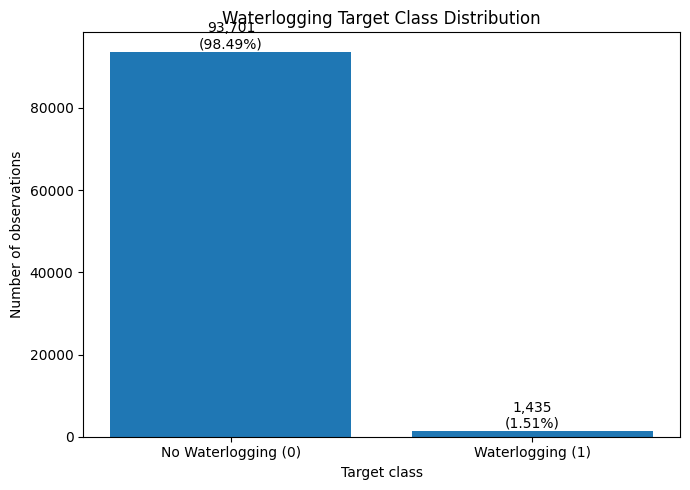


Target distribution:


,class,count,percentage
0,0,93701,98.49
1,1,1435,1.51


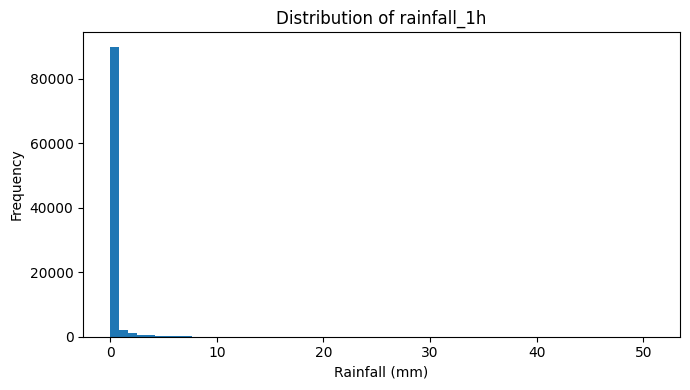

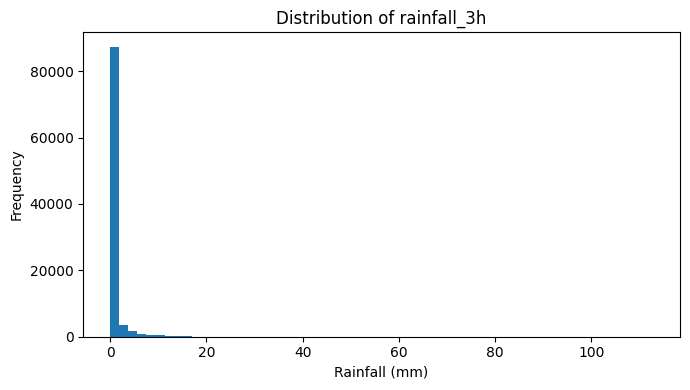

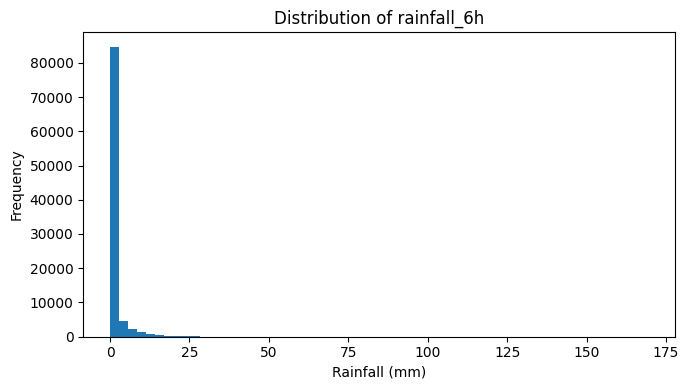

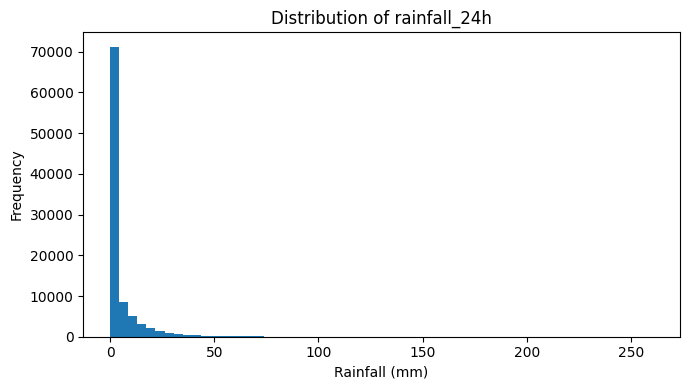

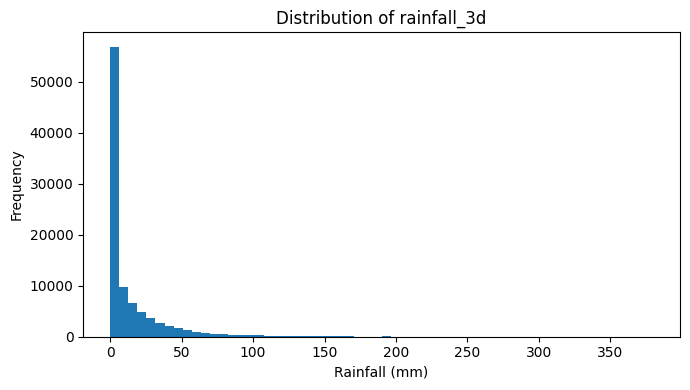

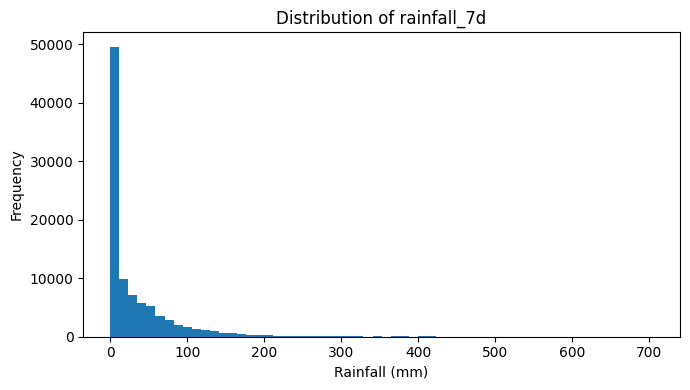

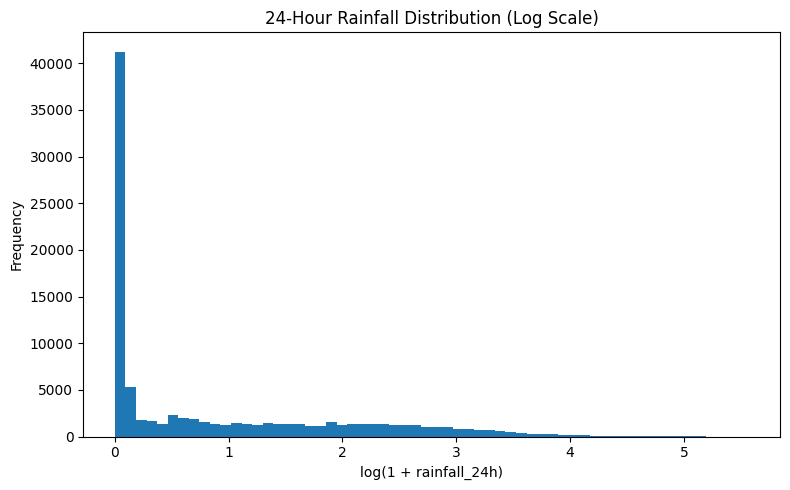

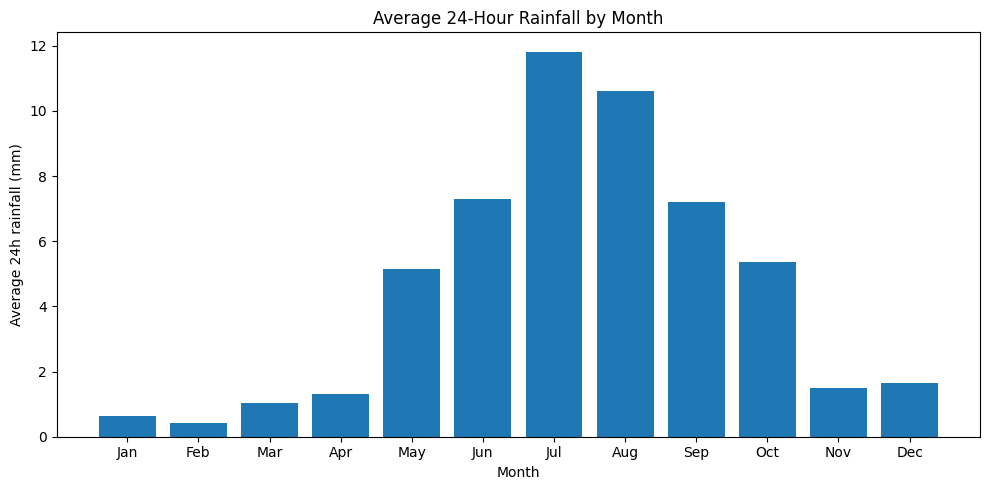

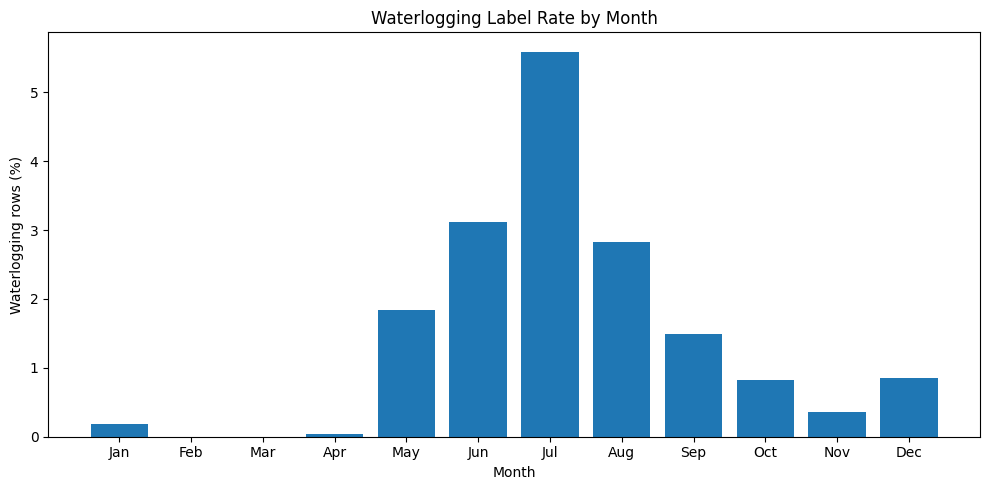


MEAN RAINFALL BY TARGET CLASS


,No Waterlogging,Waterlogging
rainfall_1h,0.17,2.53
rainfall_3h,0.48,7.32
rainfall_6h,0.95,15.27
rainfall_24h,3.73,64.34
rainfall_3d,12.04,137.77
rainfall_7d,29.38,235.35


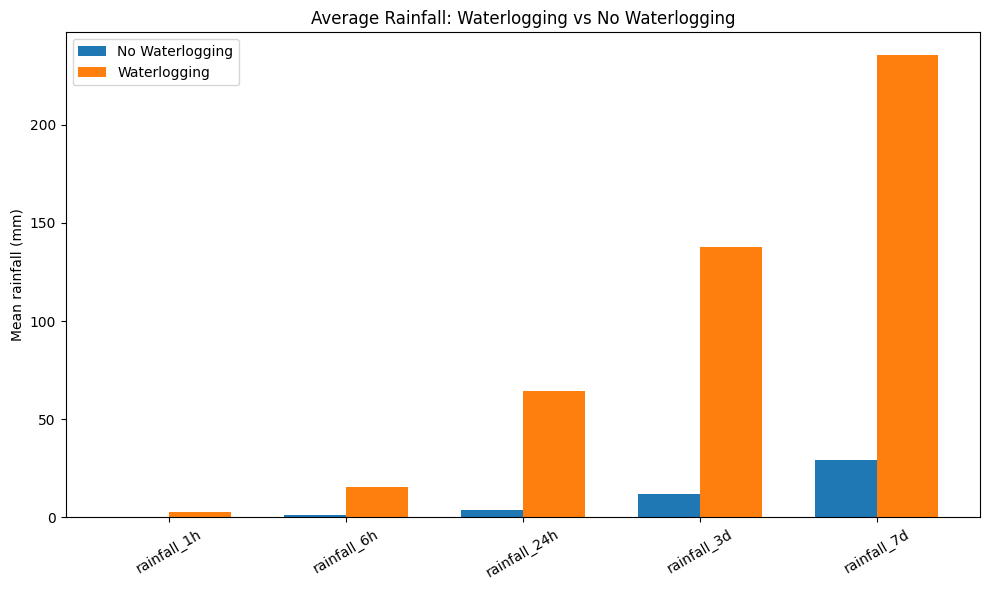


DISTRICT-WISE WATERLOGGING RATE


,state,district,waterlogging_rate_%
6,Maharashtra,Mumbai City,5.56
5,Kerala,Ernakulam,4.78
1,Assam,Kamrup Metro,1.89
11,West Bengal,Kolkata,1.66
7,Odisha,Khordha,1.46
8,Tamil Nadu,Chennai,1.29
3,Delhi,New Delhi,0.50
10,Uttar Pradesh,Lucknow,0.49
0,Andhra Pradesh,Guntur,0.35
9,Telangana,Hyderabad,0.08


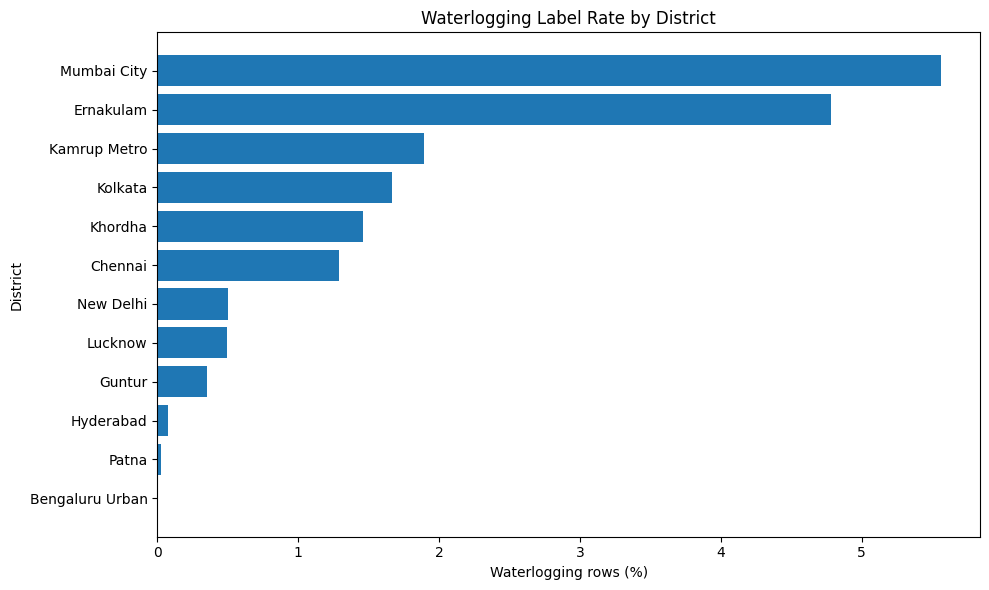

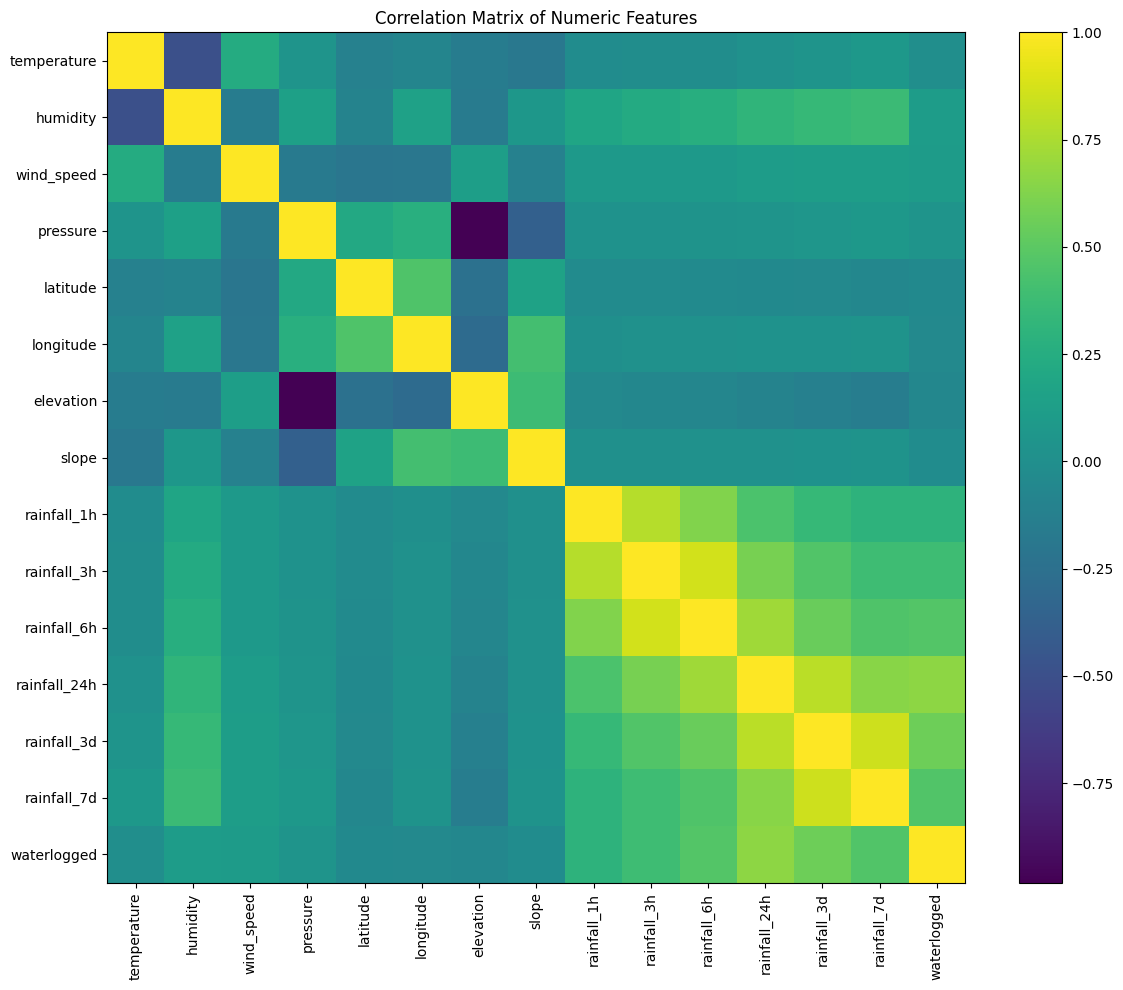


CORRELATION WITH WATERLOGGING TARGET


,feature,correlation_with_waterlogging
0,rainfall_24h,0.6653
1,rainfall_3d,0.5654
2,rainfall_6h,0.4661
3,rainfall_7d,0.4638
4,rainfall_3h,0.3864
5,rainfall_1h,0.2964
6,humidity,0.1149
7,wind_speed,0.1086
8,pressure,0.0460
9,temperature,-0.0048



RAINFALL SKEWNESS ANALYSIS


,feature,skewness,zero_percentage
0,rainfall_1h,13.816,78.870
1,rainfall_3h,11.076,70.255
2,rainfall_6h,9.715,62.586
3,rainfall_24h,6.235,43.358
4,rainfall_3d,4.421,31.763
5,rainfall_7d,3.554,21.783



✅ EXPLORATORY DATA ANALYSIS COMPLETE
Dataset rows: 95,136
Target positive rate: 1.51%
Main EDA observations:
1. Waterlogging is a highly imbalanced rare-event class.
2. Rainfall distributions are strongly right-skewed.
3. Extreme rainfall values are retained because they are important for waterlogging detection.
4. Monthly plots show seasonal rainfall/waterlogging patterns.
5. Correlation analysis identifies relationships between weather, terrain and the target.


In [20]:
# ============================================================
# 18. EXPLORATORY DATA ANALYSIS (EDA)
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


print("=" * 80)
print("EXPLORATORY DATA ANALYSIS")
print("=" * 80)


# ============================================================
# 1. TARGET CLASS DISTRIBUTION
# ============================================================

target_counts = (
    df["waterlogged"]
    .value_counts()
    .sort_index()
)

target_percent = (
    df["waterlogged"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)


fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    ["No Waterlogging (0)", "Waterlogging (1)"],
    target_counts.values
)

ax.set_title(
    "Waterlogging Target Class Distribution"
)

ax.set_ylabel(
    "Number of observations"
)

ax.set_xlabel(
    "Target class"
)


# Add counts and percentages above bars

for bar, count, percentage in zip(
    bars,
    target_counts.values,
    target_percent.values
):

    ax.text(
        bar.get_x()
        + bar.get_width() / 2,

        bar.get_height(),

        f"{count:,}\n({percentage:.2f}%)",

        ha="center",
        va="bottom"
    )


plt.tight_layout()
plt.show()


print("\nTarget distribution:")

target_table = pd.DataFrame({

    "class": target_counts.index,

    "count": target_counts.values,

    "percentage":
        target_percent.values

})

display(
    target_table.round(2)
)


# ============================================================
# 2. RAINFALL DISTRIBUTIONS
# ============================================================

rain_features = [

    "rainfall_1h",
    "rainfall_3h",
    "rainfall_6h",
    "rainfall_24h",
    "rainfall_3d",
    "rainfall_7d"

]


for feature in rain_features:

    fig, ax = plt.subplots(
        figsize=(7, 4)
    )

    ax.hist(
        df[feature],
        bins=60
    )

    ax.set_title(
        f"Distribution of {feature}"
    )

    ax.set_xlabel(
        "Rainfall (mm)"
    )

    ax.set_ylabel(
        "Frequency"
    )

    plt.tight_layout()
    plt.show()


# ============================================================
# 3. LOG-SCALE RAINFALL DISTRIBUTION
# ============================================================
#
# Rainfall is strongly right-skewed:
#
# many observations = 0 or low rainfall
# few observations  = extreme rainfall
#
# log1p is ONLY for visualization here.
# Original rainfall values are not modified.
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 5)
)

ax.hist(
    np.log1p(
        df["rainfall_24h"]
    ),
    bins=60
)

ax.set_title(
    "24-Hour Rainfall Distribution (Log Scale)"
)

ax.set_xlabel(
    "log(1 + rainfall_24h)"
)

ax.set_ylabel(
    "Frequency"
)

plt.tight_layout()
plt.show()


# ============================================================
# 4. MONTHLY AVERAGE RAINFALL
# ============================================================

df["datetime"] = pd.to_datetime(
    df["datetime"],
    errors="coerce"
)


df["eda_month"] = (
    df["datetime"]
    .dt.month
)


monthly_rainfall = (

    df.groupby(
        "eda_month"
    )[
        "rainfall_24h"
    ]

    .mean()

)


month_names = [

    "Jan",
    "Feb",
    "Mar",
    "Apr",
    "May",
    "Jun",
    "Jul",
    "Aug",
    "Sep",
    "Oct",
    "Nov",
    "Dec"

]


fig, ax = plt.subplots(
    figsize=(10, 5)
)

ax.bar(
    month_names,
    monthly_rainfall.reindex(
        range(1, 13)
    ).values
)

ax.set_title(
    "Average 24-Hour Rainfall by Month"
)

ax.set_xlabel(
    "Month"
)

ax.set_ylabel(
    "Average 24h rainfall (mm)"
)

plt.tight_layout()
plt.show()


# ============================================================
# 5. MONTHLY WATERLOGGING RATE
# ============================================================

monthly_waterlogging = (

    df.groupby(
        "eda_month"
    )[
        "waterlogged"
    ]

    .mean()

    * 100

)


fig, ax = plt.subplots(
    figsize=(10, 5)
)

ax.bar(
    month_names,
    monthly_waterlogging.reindex(
        range(1, 13)
    ).values
)

ax.set_title(
    "Waterlogging Label Rate by Month"
)

ax.set_xlabel(
    "Month"
)

ax.set_ylabel(
    "Waterlogging rows (%)"
)

plt.tight_layout()
plt.show()


# ============================================================
# 6. RAINFALL BY TARGET CLASS
# ============================================================

rain_target_summary = (

    df.groupby(
        "waterlogged"
    )[
        rain_features
    ]

    .mean()

    .T

)


rain_target_summary.columns = [

    "No Waterlogging",

    "Waterlogging"

]


print(
    "\nMEAN RAINFALL BY TARGET CLASS"
)

display(
    rain_target_summary.round(2)
)


# Plot selected windows

selected_rain = [

    "rainfall_1h",
    "rainfall_6h",
    "rainfall_24h",
    "rainfall_3d",
    "rainfall_7d"

]


comparison = (

    rain_target_summary

    .loc[
        selected_rain
    ]

)


fig, ax = plt.subplots(
    figsize=(10, 6)
)


x = np.arange(
    len(comparison)
)

width = 0.35


ax.bar(

    x - width / 2,

    comparison[
        "No Waterlogging"
    ],

    width,

    label="No Waterlogging"
)


ax.bar(

    x + width / 2,

    comparison[
        "Waterlogging"
    ],

    width,

    label="Waterlogging"
)


ax.set_xticks(
    x
)

ax.set_xticklabels(
    selected_rain,
    rotation=30
)

ax.set_ylabel(
    "Mean rainfall (mm)"
)

ax.set_title(
    "Average Rainfall: Waterlogging vs No Waterlogging"
)

ax.legend()

plt.tight_layout()
plt.show()


# ============================================================
# 7. DISTRICT-WISE WATERLOGGING RATE
# ============================================================

district_risk = (

    df.groupby(
        [
            "state",
            "district"
        ]
    )[
        "waterlogged"
    ]

    .mean()

    .reset_index()

)


district_risk[
    "waterlogging_rate_%"
] = (

    district_risk[
        "waterlogged"
    ]

    * 100

)


district_risk = (

    district_risk

    .sort_values(
        "waterlogging_rate_%",
        ascending=False
    )

)


print(
    "\nDISTRICT-WISE WATERLOGGING RATE"
)


display(

    district_risk[
        [
            "state",
            "district",
            "waterlogging_rate_%"
        ]
    ].round(2)

)


fig, ax = plt.subplots(
    figsize=(10, 6)
)


ax.barh(

    district_risk[
        "district"
    ],

    district_risk[
        "waterlogging_rate_%"
    ]

)


ax.set_title(
    "Waterlogging Label Rate by District"
)

ax.set_xlabel(
    "Waterlogging rows (%)"
)

ax.set_ylabel(
    "District"
)

ax.invert_yaxis()

plt.tight_layout()
plt.show()


# ============================================================
# 8. NUMERIC CORRELATION ANALYSIS
# ============================================================

correlation_features = [

    "temperature",
    "humidity",
    "wind_speed",
    "pressure",

    "latitude",
    "longitude",

    "elevation",
    "slope",

    "rainfall_1h",
    "rainfall_3h",
    "rainfall_6h",
    "rainfall_24h",
    "rainfall_3d",
    "rainfall_7d",

    "waterlogged"

]


correlation_features = [

    col
    for col in correlation_features
    if col in df.columns

]


corr_matrix = (

    df[
        correlation_features
    ]

    .corr()

)


fig, ax = plt.subplots(
    figsize=(12, 10)
)


image = ax.imshow(
    corr_matrix,
    aspect="auto"
)


ax.set_xticks(
    range(
        len(
            corr_matrix.columns
        )
    )
)


ax.set_yticks(
    range(
        len(
            corr_matrix.index
        )
    )
)


ax.set_xticklabels(
    corr_matrix.columns,
    rotation=90
)


ax.set_yticklabels(
    corr_matrix.index
)


fig.colorbar(
    image,
    ax=ax
)


ax.set_title(
    "Correlation Matrix of Numeric Features"
)


plt.tight_layout()
plt.show()


# ============================================================
# 9. CORRELATION WITH TARGET
# ============================================================

target_correlation = (

    corr_matrix[
        "waterlogged"
    ]

    .drop(
        "waterlogged"
    )

    .sort_values(
        ascending=False
    )

)


target_corr_df = pd.DataFrame({

    "feature":
        target_correlation.index,

    "correlation_with_waterlogging":
        target_correlation.values

})


print(
    "\nCORRELATION WITH WATERLOGGING TARGET"
)


display(
    target_corr_df.round(4)
)


# ============================================================
# 10. RAINFALL SKEWNESS
# ============================================================

skewness_rows = []


for feature in rain_features:

    skewness_rows.append({

        "feature":
            feature,

        "skewness":
            df[feature]
            .skew(),

        "zero_percentage":

            (
                df[feature]
                == 0
            ).mean()
            * 100

    })


skewness_df = pd.DataFrame(
    skewness_rows
)


print(
    "\nRAINFALL SKEWNESS ANALYSIS"
)


display(
    skewness_df.round(3)
)


# ============================================================
# 11. CLEAN TEMPORARY EDA COLUMN
# ============================================================

df = df.drop(
    columns=[
        "eda_month"
    ],
    errors="ignore"
)


# ============================================================
# 12. FINAL EDA SUMMARY
# ============================================================

print()
print("=" * 80)

print(
    "✅ EXPLORATORY DATA ANALYSIS COMPLETE"
)

print("=" * 80)


print(
    f"Dataset rows: {len(df):,}"
)


print(
    "Target positive rate:",
    f"{df['waterlogged'].mean() * 100:.2f}%"
)


print(
    "Main EDA observations:"
)


print(
    "1. Waterlogging is a highly imbalanced rare-event class."
)


print(
    "2. Rainfall distributions are strongly right-skewed."
)


print(
    "3. Extreme rainfall values are retained because they are "
    "important for waterlogging detection."
)


print(
    "4. Monthly plots show seasonal rainfall/waterlogging patterns."
)


print(
    "5. Correlation analysis identifies relationships between "
    "weather, terrain and the target."
)


print("=" * 80)

# 19. Feature engineering

**What:** Adds time/monsoon and physically motivated interaction features.

**Why:** These transformations represent antecedent rainfall, drain proximity and rain-on-flat/urban terrain.

**Output:** New ML predictors.

In [21]:
# ============================================================
# 19. FEATURE ENGINEERING
# ============================================================

import pandas as pd
import numpy as np


print("=" * 80)
print("FEATURE ENGINEERING")
print("=" * 80)


# ============================================================
# 1. REUSABLE FEATURE ENGINEERING FUNCTION
# ============================================================
#
# IMPORTANT:
# This same function can later be used for LIVE prediction,
# ensuring that training and prediction use the same feature
# definitions.
#
# ============================================================

def engineer_ml_features(data):

    out = data.copy()


    # --------------------------------------------------------
    # 1. DATETIME PREPARATION
    # --------------------------------------------------------

    out["datetime"] = pd.to_datetime(
        out["datetime"],
        errors="coerce"
    )


    # ========================================================
    # 2. TIME FEATURES
    # ========================================================

    out["month"] = (
        out["datetime"].dt.month
    )

    out["hour"] = (
        out["datetime"].dt.hour
    )

    out["day_of_year"] = (
        out["datetime"].dt.dayofyear
    )


    # --------------------------------------------------------
    # Southwest monsoon indicator
    #
    # June - September = 1
    # Other months      = 0
    # --------------------------------------------------------

    out["is_monsoon"] = (
        out["month"]
        .isin([6, 7, 8, 9])
        .astype(int)
    )


    # --------------------------------------------------------
    # Post-monsoon indicator
    #
    # Useful especially for regions influenced by
    # October-December rainfall.
    # --------------------------------------------------------

    out["is_post_monsoon"] = (
        out["month"]
        .isin([10, 11, 12])
        .astype(int)
    )


    # ========================================================
    # 3. CYCLICAL TIME FEATURES
    # ========================================================
    #
    # Month 12 and month 1 are close in real time.
    # Normal integer encoding would not represent this.
    #
    # Sin/Cos features preserve cyclic behaviour.
    # ========================================================

    out["month_sin"] = np.sin(
        2 * np.pi
        * out["month"]
        / 12
    )

    out["month_cos"] = np.cos(
        2 * np.pi
        * out["month"]
        / 12
    )


    out["hour_sin"] = np.sin(
        2 * np.pi
        * out["hour"]
        / 24
    )

    out["hour_cos"] = np.cos(
        2 * np.pi
        * out["hour"]
        / 24
    )


    # ========================================================
    # 4. ANTECEDENT RAINFALL
    # ========================================================
    #
    # rainfall_24h includes the current 1-hour rainfall.
    #
    # Subtract rainfall_1h to approximate rainfall that
    # occurred before the current hour.
    # ========================================================

    out["antecedent_rain_24h"] = (

        out["rainfall_24h"]
        -
        out["rainfall_1h"]

    ).clip(lower=0)


    out["antecedent_rain_3d"] = (

        out["rainfall_3d"]
        -
        out["rainfall_1h"]

    ).clip(lower=0)


    out["antecedent_rain_7d"] = (

        out["rainfall_7d"]
        -
        out["rainfall_1h"]

    ).clip(lower=0)


    # ========================================================
    # 5. ANTECEDENT RAIN INDEX
    # ========================================================
    #
    # Recent rainfall receives more weight.
    #
    # 24h rainfall     -> highest weight
    # previous 3 days -> medium
    # previous 7 days -> lower
    #
    # 3d and 7d accumulations are converted to
    # approximate daily rainfall before weighting.
    # ========================================================

    out["antecedent_rain_index"] = (

        0.50
        * out["antecedent_rain_24h"]

        +

        0.30
        * (
            out["antecedent_rain_3d"]
            / 3
        )

        +

        0.20
        * (
            out["antecedent_rain_7d"]
            / 7
        )

    )


    # ========================================================
    # 6. SHORT-TERM RAIN CONCENTRATION
    # ========================================================
    #
    # Measures how much of the 24-hour rainfall occurred
    # during the most recent 6 hours.
    #
    # High value -> rainfall concentrated in a short period.
    # ========================================================

    out["short_term_rain_ratio"] = np.where(

        out["rainfall_24h"] > 0,

        out["rainfall_6h"]
        /
        out["rainfall_24h"],

        0.0

    )


    # Protect against tiny floating-point differences

    out["short_term_rain_ratio"] = (

        out["short_term_rain_ratio"]
        .clip(
            lower=0,
            upper=1
        )

    )


    # ========================================================
    # 7. TERRAIN FLATNESS
    # ========================================================
    #
    # slope near 0 degrees:
    #     flatness_score close to 1
    #
    # larger slope:
    #     lower flatness score
    #
    # ========================================================

    out["flatness_score"] = (

        1

        /

        (
            1
            +
            out["slope"]
        )

    )


    # ========================================================
    # 8. RAIN-ON-FLAT-TERRAIN INTERACTION
    # ========================================================
    #
    # Heavy rain + flat terrain can increase the possibility
    # of water accumulation.
    # ========================================================

    out["rain_flat_interaction"] = (

        out["rainfall_24h"]

        *

        out["flatness_score"]

    )


    # ========================================================
    # 9. LOW-ELEVATION RAIN INTERACTION
    # ========================================================

    safe_elevation = (

        out["elevation"]
        .clip(lower=0)

    )


    out["rain_low_elevation_interaction"] = (

        out["rainfall_24h"]

        /

        (
            1
            +
            safe_elevation / 100
        )

    )


    # ========================================================
    # 10. SHORT-DURATION RAIN INTENSITY
    # ========================================================

    out["rain_intensity_3h"] = (

        out["rainfall_3h"]
        / 3
    )


    out["rain_intensity_6h"] = (

        out["rainfall_6h"]
        / 6
    )


    # ========================================================
    # 11. OPTIONAL DRAIN PROXIMITY
    # ========================================================
    #
    # This feature is created ONLY if real drainage data
    # becomes available later.
    #
    # Assumption:
    # distance_to_drain is measured in metres.
    #
    # DO NOT create fake drainage values.
    # ========================================================

    if (
        "distance_to_drain" in out.columns
        and
        out["distance_to_drain"].notna().any()
    ):

        out["drain_proximity"] = (

            1

            /

            (
                1
                +
                out["distance_to_drain"]
                / 1000
            )

        )


        out["rain_drain_interaction"] = (

            out["rainfall_24h"]

            *

            out["drain_proximity"]

        )


    # ========================================================
    # 12. OPTIONAL URBAN-RUNOFF INTERACTION
    # ========================================================
    #
    # Created only when real built-up data is available.
    # ========================================================

    if (
        "built_up_proxy" in out.columns
        and
        out["built_up_proxy"].notna().any()
    ):

        out["urban_rain_interaction"] = (

            out["rainfall_24h"]

            *

            out["built_up_proxy"]

        )


    return out


# ============================================================
# 2. APPLY FEATURE ENGINEERING
# ============================================================

columns_before = set(
    df.columns
)

column_count_before = (
    df.shape[1]
)


df_fe = engineer_ml_features(
    df
)


columns_after = set(
    df_fe.columns
)


new_features = sorted(

    columns_after
    -
    columns_before

)


print(
    "\nColumns before feature engineering:",
    column_count_before
)

print(
    "Columns after feature engineering :",
    df_fe.shape[1]
)

print(
    "New features created              :",
    len(new_features)
)


print(
    "\nNEW FEATURES"
)

for feature in new_features:

    print(
        " ",
        feature
    )


# ============================================================
# 3. CHECK MISSING VALUES IN NEW FEATURES
# ============================================================

new_feature_quality = []


for feature in new_features:

    new_feature_quality.append({

        "feature":
            feature,

        "missing_rows":
            df_fe[feature]
            .isna()
            .sum(),

        "missing_%":
            df_fe[feature]
            .isna()
            .mean()
            * 100,

        "min":
            df_fe[feature]
            .min(),

        "max":
            df_fe[feature]
            .max(),

        "mean":
            df_fe[feature]
            .mean()

    })


new_feature_quality_df = pd.DataFrame(
    new_feature_quality
)


print(
    "\nNEW FEATURE QUALITY"
)


display(
    new_feature_quality_df.round(4)
)


# ============================================================
# 4. CHECK FOR INFINITE VALUES
# ============================================================

numeric_new_features = [

    feature

    for feature in new_features

    if pd.api.types.is_numeric_dtype(
        df_fe[feature]
    )

]


infinite_results = []


for feature in numeric_new_features:

    infinite_count = (

        np.isinf(
            df_fe[feature]
        )
        .sum()

    )


    infinite_results.append({

        "feature":
            feature,

        "infinite_values":
            infinite_count

    })


infinite_df = pd.DataFrame(
    infinite_results
)


print(
    "\nINFINITE VALUE CHECK"
)


display(
    infinite_df
)


# ============================================================
# 5. IMPORTANT FEATURE SUMMARY
# ============================================================

engineered_features_to_show = [

    "month",
    "hour",

    "is_monsoon",
    "is_post_monsoon",

    "month_sin",
    "month_cos",

    "hour_sin",
    "hour_cos",

    "antecedent_rain_24h",
    "antecedent_rain_3d",
    "antecedent_rain_7d",

    "antecedent_rain_index",

    "short_term_rain_ratio",

    "flatness_score",

    "rain_flat_interaction",

    "rain_low_elevation_interaction",

    "rain_intensity_3h",
    "rain_intensity_6h"

]


engineered_features_to_show = [

    feature

    for feature
    in engineered_features_to_show

    if feature in df_fe.columns

]


print(
    "\nENGINEERED FEATURE SAMPLE"
)


display(

    df_fe[

        [
            "state",
            "district",
            "datetime",
            "rainfall_1h",
            "rainfall_24h",
            "elevation",
            "slope"
        ]

        +

        engineered_features_to_show

        +

        [
            "waterlogged"
        ]

    ].head(20)

)


# ============================================================
# 6. CORRELATION OF ENGINEERED FEATURES WITH TARGET
# ============================================================

correlation_features = (

    engineered_features_to_show

    +

    [
        "waterlogged"
    ]

)


engineered_corr = (

    df_fe[
        correlation_features
    ]

    .corr()[
        "waterlogged"
    ]

    .drop(
        "waterlogged"
    )

    .sort_values(
        ascending=False
    )

)


engineered_corr_df = pd.DataFrame({

    "feature":
        engineered_corr.index,

    "correlation_with_waterlogged":
        engineered_corr.values

})


print(
    "\nENGINEERED FEATURE CORRELATION WITH TARGET"
)


display(
    engineered_corr_df.round(4)
)


# ============================================================
# 7. OPTIONAL FEATURE AVAILABILITY MESSAGE
# ============================================================

print(
    "\nOPTIONAL STATIC INTERACTION STATUS"
)


if "drain_proximity" in df_fe.columns:

    print(
        " Real drain-proximity feature created"
    )

else:

    print(
        "⚠ drain_proximity NOT created "
        "(real drainage data unavailable)"
    )


if "urban_rain_interaction" in df_fe.columns:

    print(
        " Urban-rain interaction created"
    )

else:

    print(
        "⚠ urban_rain_interaction NOT created "
        "(real built-up/LULC data unavailable)"
    )


# ============================================================
# 8. ASSIGN FEATURE-ENGINEERED DATASET
# ============================================================

df = df_fe.copy()


# ============================================================
# 9. SAVE FEATURE ENGINEERED DATASET
# ============================================================

feature_engineered_path = (

    DATA_DIR
    /
    "waterlogging_feature_engineered_2024_to_now.csv"

)


df.to_csv(
    feature_engineered_path,
    index=False
)


print()
print("=" * 80)

print(
    " FEATURE ENGINEERING COMPLETE"
)

print("=" * 80)


print(
    "Rows:",
    f"{len(df):,}"
)

print(
    "Columns:",
    df.shape[1]
)

print(
    "New features:",
    len(new_features)
)

print(
    "Saved:"
)

print(
    feature_engineered_path
)

print("=" * 80)

FEATURE ENGINEERING

Columns before feature engineering: 25
Columns after feature engineering : 44
New features created              : 19

NEW FEATURES
  antecedent_rain_24h
  antecedent_rain_3d
  antecedent_rain_7d
  antecedent_rain_index
  day_of_year
  flatness_score
  hour
  hour_cos
  hour_sin
  is_monsoon
  is_post_monsoon
  month
  month_cos
  month_sin
  rain_flat_interaction
  rain_intensity_3h
  rain_intensity_6h
  rain_low_elevation_interaction
  short_term_rain_ratio

NEW FEATURE QUALITY


,feature,missing_rows,missing_%,min,max,mean
0,antecedent_rain_24h,0,0.0,0.0000,260.6000,4.4455
1,antecedent_rain_3d,0,0.0,0.0000,373.4000,13.7356
2,antecedent_rain_7d,0,0.0,0.0000,700.6000,32.2819
3,antecedent_rain_index,0,0.0,0.0000,165.6300,4.5187
4,day_of_year,0,0.0,1.0000,366.0000,169.4107
5,flatness_score,0,0.0,0.3838,1.0000,0.7916
6,hour,0,0.0,0.0000,21.0000,10.5000
7,hour_cos,0,0.0,-1.0000,1.0000,-0.0000
8,hour_sin,0,0.0,-1.0000,1.0000,0.0000
9,is_monsoon,0,0.0,0.0000,1.0000,0.3562



INFINITE VALUE CHECK


,feature,infinite_values
0,antecedent_rain_24h,0
1,antecedent_rain_3d,0
2,antecedent_rain_7d,0
3,antecedent_rain_index,0
4,day_of_year,0
5,flatness_score,0
6,hour,0
7,hour_cos,0
8,hour_sin,0
9,is_monsoon,0



ENGINEERED FEATURE SAMPLE


,state,district,datetime,rainfall_1h,rainfall_24h,elevation,slope,month,hour,is_monsoon,...,antecedent_rain_3d,antecedent_rain_7d,antecedent_rain_index,short_term_rain_ratio,flatness_score,rain_flat_interaction,rain_low_elevation_interaction,rain_intensity_3h,rain_intensity_6h,waterlogged
0,Andhra Pradesh,Guntur,2024-01-01 00:00:00,0.0,0.0,39.0,0.094002,1,0,0,...,0.0,0.0,0.000000,0.0,0.914075,0.000000,0.000000,0.000000,0.000000,0
1,Andhra Pradesh,Guntur,2024-01-01 03:00:00,0.0,0.0,39.0,0.094002,1,3,0,...,0.0,0.0,0.000000,0.0,0.914075,0.000000,0.000000,0.000000,0.000000,0
2,Andhra Pradesh,Guntur,2024-01-01 06:00:00,0.0,0.0,39.0,0.094002,1,6,0,...,0.0,0.0,0.000000,0.0,0.914075,0.000000,0.000000,0.000000,0.000000,0
3,Andhra Pradesh,Guntur,2024-01-01 09:00:00,0.0,0.0,39.0,0.094002,1,9,0,...,0.0,0.0,0.000000,0.0,0.914075,0.000000,0.000000,0.000000,0.000000,0
4,Andhra Pradesh,Guntur,2024-01-01 12:00:00,0.0,0.0,39.0,0.094002,1,12,0,...,0.0,0.0,0.000000,0.0,0.914075,0.000000,0.000000,0.000000,0.000000,0
5,Andhra Pradesh,Guntur,2024-01-01 15:00:00,0.0,0.0,39.0,0.094002,1,15,0,...,0.0,0.0,0.000000,0.0,0.914075,0.000000,0.000000,0.000000,0.000000,0
6,Andhra Pradesh,Guntur,2024-01-01 18:00:00,0.0,0.0,39.0,0.094002,1,18,0,...,0.0,0.0,0.000000,0.0,0.914075,0.000000,0.000000,0.000000,0.000000,0
7,Andhra Pradesh,Guntur,2024-01-01 21:00:00,0.0,0.0,39.0,0.094002,1,21,0,...,0.0,0.0,0.000000,0.0,0.914075,0.000000,0.000000,0.000000,0.000000,0
8,Andhra Pradesh,Guntur,2024-01-02 00:00:00,0.0,0.0,39.0,0.094002,1,0,0,...,0.0,0.0,0.000000,0.0,0.914075,0.000000,0.000000,0.000000,0.000000,0
9,Andhra Pradesh,Guntur,2024-01-02 03:00:00,0.0,0.0,39.0,0.094002,1,3,0,...,0.0,0.0,0.000000,0.0,0.914075,0.000000,0.000000,0.000000,0.000000,0



ENGINEERED FEATURE CORRELATION WITH TARGET


,feature,correlation_with_waterlogged
0,rain_low_elevation_interaction,0.6984
1,rain_flat_interaction,0.6720
2,antecedent_rain_24h,0.6628
3,antecedent_rain_index,0.6512
4,antecedent_rain_3d,0.5615
5,rain_intensity_6h,0.4661
6,antecedent_rain_7d,0.4608
7,rain_intensity_3h,0.3864
8,is_monsoon,0.1114
9,short_term_rain_ratio,0.0414



OPTIONAL STATIC INTERACTION STATUS
⚠ drain_proximity NOT created (real drainage data unavailable)
⚠ urban_rain_interaction NOT created (real built-up/LULC data unavailable)

 FEATURE ENGINEERING COMPLETE
Rows: 95,136
Columns: 44
New features: 19
Saved:
data/waterlogging_feature_engineered_2024_to_now.csv


In [23]:
print("Rows:", len(df))
print("Start:", df["datetime"].min())
print("End:", df["datetime"].max())

print(
    "Duplicate state-district-datetime:",
    df.duplicated(
        subset=["state", "district", "datetime"]
    ).sum()
)

print("\nLatest timestamps:")
print(
    df["datetime"]
    .value_counts()
    .sort_index()
    .tail(5)
)

Rows: 95136
Start: 2024-01-01 00:00:00
End: 2026-09-17 21:00:00
Duplicate state-district-datetime: 0

Latest timestamps:
datetime
2026-09-17 09:00:00    12
2026-09-17 12:00:00    12
2026-09-17 15:00:00    12
2026-09-17 18:00:00    12
2026-09-17 21:00:00    12
Name: count, dtype: int64


# 20. Feature selection




In [26]:
from pathlib import Path
import joblib

MODEL_DIR = Path("models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Define selected_features based on the features used in later preprocessing steps
# (e.g., from Section 22. Preprocessing's 'numeric_features' list).
# This assumes these features have been determined by prior feature selection logic.
selected_features = [
    "temperature",
    "humidity",
    "wind_speed",
    "pressure",
    "latitude",
    "longitude",
    "rainfall_1h",
    "rainfall_3h",
    "rainfall_6h",
    "rainfall_24h",
    "rainfall_3d",
    "rainfall_7d",
    "elevation",
    "slope",
    "month",
    "hour",
    "is_monsoon",
    "is_post_monsoon",
    "month_sin",
    "month_cos",
    "hour_sin",
    "hour_cos",
    "antecedent_rain_24h",
    "antecedent_rain_3d",
    "antecedent_rain_7d",
    "antecedent_rain_index",
    "short_term_rain_ratio",
    "flatness_score",
    "rain_flat_interaction",
    "rain_low_elevation_interaction"
]

# Define feature_selection_config as a dictionary containing the selected features
feature_selection_config = {
    "selected_features": selected_features,
    "target": "waterlogged",
    "note": "Features chosen based on domain knowledge and availability after initial cleaning."
}

joblib.dump(
    feature_selection_config,
    MODEL_DIR / "feature_selection_config.joblib"
)

print(" Feature-selection configuration saved:")
print(MODEL_DIR / "feature_selection_config.joblib")

print("\n FEATURE SELECTION COMPLETE")
print("Selected predictors:", len(selected_features))
print("Target: waterlogged")

 Feature-selection configuration saved:
models/feature_selection_config.joblib

 FEATURE SELECTION COMPLETE
Selected predictors: 30
Target: waterlogged


# 21. Chronological train / validation / test split

**What:** Splits by time into 70% train, 15% validation and 15% future test.

**Why:** Random splitting can leak future weather patterns.

**Output:** Split sizes/date ranges/class rates.

In [27]:
# ============================================================
# 21. CHRONOLOGICAL TRAIN / VALIDATION / TEST SPLIT
# ============================================================

import pandas as pd
import numpy as np


print("=" * 80)
print("CHRONOLOGICAL TRAIN / VALIDATION / TEST SPLIT")
print("=" * 80)


# ============================================================
# 1. PREPARE DATETIME
# ============================================================

df_split = df.copy()

df_split["datetime"] = pd.to_datetime(
    df_split["datetime"],
    errors="coerce"
)


# Remove invalid datetime rows if any
invalid_datetime = df_split["datetime"].isna().sum()

print(
    "\nInvalid datetime rows:",
    invalid_datetime
)


df_split = df_split.dropna(
    subset=["datetime"]
).copy()


# ============================================================
# 2. SORT CHRONOLOGICALLY
# ============================================================

df_split = (

    df_split

    .sort_values(
        [
            "datetime",
            "state",
            "district"
        ]
    )

    .reset_index(drop=True)

)


print(
    "Total rows:",
    f"{len(df_split):,}"
)


# ============================================================
# 3. GET UNIQUE TIMESTAMPS
# ============================================================
#
# IMPORTANT:
# We split UNIQUE timestamps rather than individual rows.
#
# This prevents one district at a particular timestamp from
# entering training while another district at the same
# timestamp enters validation/test.
# ============================================================

unique_times = (

    df_split["datetime"]

    .drop_duplicates()

    .sort_values()

    .reset_index(drop=True)

)


n_times = len(unique_times)


print(
    "Unique timestamps:",
    f"{n_times:,}"
)


# ============================================================
# 4. DEFINE SPLIT POINTS
# ============================================================

train_end = int(
    n_times * 0.70
)

validation_end = int(
    n_times * 0.85
)


train_times = unique_times.iloc[
    :train_end
]


validation_times = unique_times.iloc[
    train_end:validation_end
]


test_times = unique_times.iloc[
    validation_end:
]


print(
    "\nTimestamp split:"
)

print(
    "Train timestamps     :",
    f"{len(train_times):,}"
)

print(
    "Validation timestamps:",
    f"{len(validation_times):,}"
)

print(
    "Test timestamps      :",
    f"{len(test_times):,}"
)


# ============================================================
# 5. CREATE DATA SPLITS
# ============================================================

train_df = df_split[
    df_split["datetime"].isin(
        train_times
    )
].copy()


val_df = df_split[
    df_split["datetime"].isin(
        validation_times
    )
].copy()


test_df = df_split[
    df_split["datetime"].isin(
        test_times
    )
].copy()


# Reset indexes

train_df = train_df.reset_index(
    drop=True
)

val_df = val_df.reset_index(
    drop=True
)

test_df = test_df.reset_index(
    drop=True
)


# ============================================================
# 6. SPLIT SUMMARY FUNCTION
# ============================================================

def summarize_split(
    name,
    data,
    total_rows
):

    positive_count = (
        data["waterlogged"]
        .sum()
    )

    negative_count = (
        len(data)
        -
        positive_count
    )

    positive_rate = (
        data["waterlogged"]
        .mean()
        * 100
    )

    return {

        "split":
            name,

        "rows":
            len(data),

        "dataset_%":
            len(data)
            / total_rows
            * 100,

        "start_datetime":
            data["datetime"].min(),

        "end_datetime":
            data["datetime"].max(),

        "class_0":
            negative_count,

        "class_1":
            positive_count,

        "class_1_%":
            positive_rate,

        "states":
            data["state"].nunique(),

        "districts":
            data["district"].nunique()

    }


# ============================================================
# 7. CREATE SUMMARY TABLE
# ============================================================

split_summary = pd.DataFrame([

    summarize_split(
        "Train",
        train_df,
        len(df_split)
    ),

    summarize_split(
        "Validation",
        val_df,
        len(df_split)
    ),

    summarize_split(
        "Test",
        test_df,
        len(df_split)
    )

])


print(
    "\nSPLIT SUMMARY"
)


display(
    split_summary.round(3)
)


# ============================================================
# 8. PRINT DATE RANGES
# ============================================================

print(
    "\nDATE RANGES"
)

print("-" * 80)


print(
    "TRAIN"
)

print(
    train_df["datetime"].min(),
    "→",
    train_df["datetime"].max()
)


print(
    "\nVALIDATION"
)

print(
    val_df["datetime"].min(),
    "→",
    val_df["datetime"].max()
)


print(
    "\nTEST"
)

print(
    test_df["datetime"].min(),
    "→",
    test_df["datetime"].max()
)


# ============================================================
# 9. VERIFY STRICT CHRONOLOGICAL ORDER
# ============================================================

train_before_validation = (

    train_df["datetime"].max()
    <
    val_df["datetime"].min()

)


validation_before_test = (

    val_df["datetime"].max()
    <
    test_df["datetime"].min()

)


print(
    "\nCHRONOLOGICAL ORDER CHECK"
)

print(
    "Train ends before validation starts:",
    train_before_validation
)

print(
    "Validation ends before test starts:",
    validation_before_test
)


if (
    train_before_validation
    and
    validation_before_test
):

    print(
        " No temporal overlap between splits"
    )

else:

    raise ValueError(
        "Temporal leakage detected!"
    )


# ============================================================
# 10. CHECK FOR TIMESTAMP OVERLAP
# ============================================================

train_val_overlap = set(
    train_df["datetime"]
).intersection(
    set(
        val_df["datetime"]
    )
)


train_test_overlap = set(
    train_df["datetime"]
).intersection(
    set(
        test_df["datetime"]
    )
)


val_test_overlap = set(
    val_df["datetime"]
).intersection(
    set(
        test_df["datetime"]
    )
)


print(
    "\nTIMESTAMP OVERLAP CHECK"
)

print(
    "Train ↔ Validation overlap:",
    len(train_val_overlap)
)

print(
    "Train ↔ Test overlap:",
    len(train_test_overlap)
)

print(
    "Validation ↔ Test overlap:",
    len(val_test_overlap)
)


# ============================================================
# 11. CLASS DISTRIBUTION
# ============================================================

print(
    "\nCLASS DISTRIBUTION BY SPLIT"
)

print("-" * 80)


for name, data in [

    ("TRAIN", train_df),
    ("VALIDATION", val_df),
    ("TEST", test_df)

]:

    counts = (

        data["waterlogged"]

        .value_counts()

        .sort_index()

    )


    percentages = (

        data["waterlogged"]

        .value_counts(
            normalize=True
        )

        .sort_index()

        * 100

    )


    print(
        f"\n{name}"
    )


    for cls in [0, 1]:

        count = counts.get(
            cls,
            0
        )

        percentage = percentages.get(
            cls,
            0
        )


        print(
            f"Class {cls}: "
            f"{count:,} "
            f"({percentage:.2f}%)"
        )


# ============================================================
# 12. VERIFY BOTH TARGET CLASSES EXIST
# ============================================================

print(
    "\nTARGET CLASS CHECK"
)

for name, data in [

    ("Train", train_df),

    ("Validation", val_df),

    ("Test", test_df)

]:

    classes = sorted(
        data["waterlogged"]
        .unique()
        .tolist()
    )


    print(
        f"{name}: {classes}"
    )


    if len(classes) < 2:

        print(
            f"⚠ WARNING: {name} contains only one target class."
        )

    else:

        print(
            f" {name} contains both classes."
        )


# ============================================================
# 13. DISTRICT COVERAGE CHECK
# ============================================================

print(
    "\nDISTRICT COVERAGE"
)


for name, data in [

    ("Train", train_df),

    ("Validation", val_df),

    ("Test", test_df)

]:

    print(

        f"{name}: "
        f"{data['district'].nunique()} districts, "
        f"{data['state'].nunique()} states"

    )


# ============================================================
# 14. ASSIGN X / y
# ============================================================

TARGET = "waterlogged"


X_train = train_df.drop(
    columns=[TARGET]
)

y_train = train_df[
    TARGET
].copy()


X_val = val_df.drop(
    columns=[TARGET]
)

y_val = val_df[
    TARGET
].copy()


X_test = test_df.drop(
    columns=[TARGET]
)

y_test = test_df[
    TARGET
].copy()


print(
    "\nX / y SHAPES"
)

print(
    "X_train:",
    X_train.shape,
    "| y_train:",
    y_train.shape
)

print(
    "X_val  :",
    X_val.shape,
    "| y_val  :",
    y_val.shape
)

print(
    "X_test :",
    X_test.shape,
    "| y_test :",
    y_test.shape
)


# ============================================================
# 15. SAVE SPLITS
# ============================================================

train_path = (
    DATA_DIR /
    "waterlogging_train_chronological.csv"
)

val_path = (
    DATA_DIR /
    "waterlogging_validation_chronological.csv"
)

test_path = (
    DATA_DIR /
    "waterlogging_test_future.csv"
)


train_df.to_csv(
    train_path,
    index=False
)

val_df.to_csv(
    val_path,
    index=False
)

test_df.to_csv(
    test_path,
    index=False
)


# ============================================================
# 16. FINAL SUMMARY
# ============================================================

print()
print("=" * 80)

print(
    " CHRONOLOGICAL SPLIT COMPLETE"
)

print("=" * 80)


print(
    f"Training   : {len(train_df):,} rows "
    f"({len(train_df)/len(df_split)*100:.2f}%)"
)

print(
    f"Validation : {len(val_df):,} rows "
    f"({len(val_df)/len(df_split)*100:.2f}%)"
)

print(
    f"Future Test: {len(test_df):,} rows "
    f"({len(test_df)/len(df_split)*100:.2f}%)"
)


print(
    "\nNo random shuffling was performed."
)

print(
    "Future timestamps are kept completely unseen "
    "from model training."
)

print("=" * 80)

CHRONOLOGICAL TRAIN / VALIDATION / TEST SPLIT

Invalid datetime rows: 0
Total rows: 95,136
Unique timestamps: 7,928

Timestamp split:
Train timestamps     : 5,549
Validation timestamps: 1,189
Test timestamps      : 1,190

SPLIT SUMMARY


,split,rows,dataset_%,start_datetime,end_datetime,class_0,class_1,class_1_%,states,districts
0,Train,66588,69.992,2024-01-01 00:00:00,2025-11-24 12:00:00,65573,1015,1.524,12,12
1,Validation,14268,14.997,2025-11-24 15:00:00,2026-04-22 03:00:00,14227,41,0.287,12,12
2,Test,14280,15.010,2026-04-22 06:00:00,2026-09-17 21:00:00,13901,379,2.654,12,12



DATE RANGES
--------------------------------------------------------------------------------
TRAIN
2024-01-01 00:00:00 → 2025-11-24 12:00:00

VALIDATION
2025-11-24 15:00:00 → 2026-04-22 03:00:00

TEST
2026-04-22 06:00:00 → 2026-09-17 21:00:00

CHRONOLOGICAL ORDER CHECK
Train ends before validation starts: True
Validation ends before test starts: True
 No temporal overlap between splits

TIMESTAMP OVERLAP CHECK
Train ↔ Validation overlap: 0
Train ↔ Test overlap: 0
Validation ↔ Test overlap: 0

CLASS DISTRIBUTION BY SPLIT
--------------------------------------------------------------------------------

TRAIN
Class 0: 65,573 (98.48%)
Class 1: 1,015 (1.52%)

VALIDATION
Class 0: 14,227 (99.71%)
Class 1: 41 (0.29%)

TEST
Class 0: 13,901 (97.35%)
Class 1: 379 (2.65%)

TARGET CLASS CHECK
Train: [0, 1]
 Train contains both classes.
Validation: [0, 1]
 Validation contains both classes.
Test: [0, 1]
 Test contains both classes.

DISTRICT COVERAGE
Train: 12 districts, 12 states
Validation: 12 dis

# 22. Preprocessing

**What:** Median-imputes/scales numeric values and one-hot encodes LULC.

**Why:** Missing values are learned from training only and the same preprocessing will be saved for live inference.

**Output:** A reusable `ColumnTransformer`.

In [28]:
# ============================================================
# 22. PREPROCESSING
# ============================================================

import pandas as pd
import numpy as np
import joblib

from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder


print("=" * 80)
print("PREPROCESSING")
print("=" * 80)


# ============================================================
# 1. SELECT NUMERIC MODEL FEATURES
# ============================================================
#
# We explicitly select useful predictors.
#
# Excluded:
#
# precipitation       -> redundant with rain/rainfall_1h
# rain                -> redundant with rainfall_1h
# source_elevation    -> redundant with elevation
#
# state / district    -> location identifiers, not physical
#                       measurements; excluding them improves
#                       ability to apply model to new districts.
#
# source metadata     -> not ML predictors.
#
# rain_intensity_3h   -> rainfall_3h / 3 (exact redundancy)
# rain_intensity_6h   -> rainfall_6h / 6 (exact redundancy)
#
# ============================================================

numeric_features = [

    # --------------------------------------------------------
    # Current weather
    # --------------------------------------------------------

    "temperature",
    "humidity",
    "wind_speed",
    "pressure",


    # --------------------------------------------------------
    # Geographic position
    # --------------------------------------------------------

    "latitude",
    "longitude",


    # --------------------------------------------------------
    # Rainfall windows
    # --------------------------------------------------------

    "rainfall_1h",
    "rainfall_3h",
    "rainfall_6h",
    "rainfall_24h",
    "rainfall_3d",
    "rainfall_7d",


    # --------------------------------------------------------
    # Terrain
    # --------------------------------------------------------

    "elevation",
    "slope",


    # --------------------------------------------------------
    # Time / season
    # --------------------------------------------------------

    "month",
    "hour",

    "is_monsoon",
    "is_post_monsoon",

    "month_sin",
    "month_cos",

    "hour_sin",
    "hour_cos",


    # --------------------------------------------------------
    # Antecedent rainfall
    # --------------------------------------------------------

    "antecedent_rain_24h",
    "antecedent_rain_3d",
    "antecedent_rain_7d",
    "antecedent_rain_index",


    # --------------------------------------------------------
    # Physically motivated interactions
    # --------------------------------------------------------

    "short_term_rain_ratio",
    "flatness_score",
    "rain_flat_interaction",
    "rain_low_elevation_interaction"

]


# Keep only columns that really exist
numeric_features = [

    feature

    for feature in numeric_features

    if feature in X_train.columns

]


# ============================================================
# 2. OPTIONAL CATEGORICAL FEATURES
# ============================================================
#
# Current project:
# land_use was removed because it contained 100% missing data.
#
# If real LULC data is added later, this code automatically
# uses OneHotEncoder.
# ============================================================

categorical_features = []


if (
    "land_use" in X_train.columns
    and
    X_train["land_use"].notna().any()
):

    categorical_features.append(
        "land_use"
    )


print(
    "\nNumeric features:",
    len(numeric_features)
)

for feature in numeric_features:

    print(
        "✅",
        feature
    )


print(
    "\nCategorical features:",
    categorical_features
)


if len(categorical_features) == 0:

    print(
        "⚠ No real categorical LULC feature is currently available."
    )

    print(
        "Numeric preprocessing will be used."
    )


# ============================================================
# 3. CHECK REQUIRED FEATURES
# ============================================================

missing_from_val = [

    feature

    for feature in numeric_features + categorical_features

    if feature not in X_val.columns

]


missing_from_test = [

    feature

    for feature in numeric_features + categorical_features

    if feature not in X_test.columns

]


print(
    "\nMissing features in validation:",
    missing_from_val
)

print(
    "Missing features in test:",
    missing_from_test
)


if missing_from_val or missing_from_test:

    raise ValueError(
        "Train/validation/test feature mismatch detected."
    )


# ============================================================
# 4. NUMERIC PREPROCESSING PIPELINE
# ============================================================
#
# Median imputation:
# robust to skewed numeric variables such as rainfall.
#
# StandardScaler:
# important for models such as Logistic Regression.
#
# Tree models do not require scaling, but scaling does not
# prevent them from being trained.
# ============================================================

numeric_transformer = Pipeline(

    steps=[

        (
            "imputer",

            SimpleImputer(
                strategy="median"
            )
        ),

        (
            "scaler",

            StandardScaler()
        )

    ]

)


# ============================================================
# 5. CATEGORICAL PREPROCESSING PIPELINE
# ============================================================

categorical_transformer = Pipeline(

    steps=[

        (
            "imputer",

            SimpleImputer(
                strategy="most_frequent"
            )
        ),

        (
            "onehot",

            OneHotEncoder(
                handle_unknown="ignore"
            )
        )

    ]

)


# ============================================================
# 6. BUILD COLUMN TRANSFORMER
# ============================================================

transformers = [

    (
        "numeric",

        numeric_transformer,

        numeric_features
    )

]


# Add categorical transformer only if valid LULC exists

if len(categorical_features) > 0:

    transformers.append(

        (
            "categorical",

            categorical_transformer,

            categorical_features
        )

    )


preprocessor = ColumnTransformer(

    transformers=transformers,

    remainder="drop",

    verbose_feature_names_out=False

)


print(
    "\n ColumnTransformer created"
)


# ============================================================
# 7. FIT ONLY ON TRAINING DATA
# ============================================================
#
# CRITICAL:
#
# fit_transform -> TRAIN
#
# transform     -> VALIDATION
# transform     -> TEST
#
# Validation/test information is NEVER used when learning
# median values or scaler parameters.
# ============================================================

X_train_processed = (

    preprocessor.fit_transform(
        X_train
    )

)


X_val_processed = (

    preprocessor.transform(
        X_val
    )

)


X_test_processed = (

    preprocessor.transform(
        X_test
    )

)


# ============================================================
# 8. SHAPE CHECK
# ============================================================

print(
    "\nPROCESSED DATA SHAPES"
)

print(
    "Train      :",
    X_train_processed.shape
)

print(
    "Validation :",
    X_val_processed.shape
)

print(
    "Test       :",
    X_test_processed.shape
)


# ============================================================
# 9. MISSING / INFINITE VALUE CHECK
# ============================================================

def check_processed_array(
    name,
    array
):

    # Convert sparse matrices safely if required

    if hasattr(
        array,
        "toarray"
    ):

        check_array = array.toarray()

    else:

        check_array = np.asarray(
            array
        )


    missing = (
        np.isnan(
            check_array
        ).sum()
    )


    infinite = (
        np.isinf(
            check_array
        ).sum()
    )


    print(
        f"{name:<12} | "
        f"NaN: {missing:,} | "
        f"Infinite: {infinite:,}"
    )


print(
    "\nPROCESSED VALUE CHECK"
)


check_processed_array(
    "Train",
    X_train_processed
)

check_processed_array(
    "Validation",
    X_val_processed
)

check_processed_array(
    "Test",
    X_test_processed
)


# ============================================================
# 10. GET FINAL FEATURE NAMES
# ============================================================

processed_feature_names = (

    preprocessor
    .get_feature_names_out()
    .tolist()

)


print(
    "\nFinal number of model features:",
    len(processed_feature_names)
)


print(
    "\nFINAL MODEL FEATURES"
)


for i, feature in enumerate(
    processed_feature_names,
    start=1
):

    print(
        f"{i:2d}. {feature}"
    )


# ============================================================
# 11. TRAINING MEDIANS
# ============================================================
#
# These medians were learned ONLY from training data.
# ============================================================

numeric_imputer = (

    preprocessor
    .named_transformers_[
        "numeric"
    ]
    .named_steps[
        "imputer"
    ]

)


training_medians = pd.DataFrame({

    "feature":
        numeric_features,

    "training_median":
        numeric_imputer.statistics_

})


print(
    "\nTRAINING-ONLY MEDIAN VALUES"
)


display(
    training_medians.round(4)
)


# ============================================================
# 12. SCALER PARAMETERS
# ============================================================

numeric_scaler = (

    preprocessor
    .named_transformers_[
        "numeric"
    ]
    .named_steps[
        "scaler"
    ]

)


scaler_summary = pd.DataFrame({

    "feature":
        numeric_features,

    "training_mean":
        numeric_scaler.mean_,

    "training_scale":
        numeric_scaler.scale_

})


print(
    "\nSCALER PARAMETERS LEARNED FROM TRAINING"
)


display(
    scaler_summary.round(4)
)


# ============================================================
# 13. SAVE PREPROCESSOR
# ============================================================

MODEL_DIR = Path(
    "models"
)

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)


preprocessor_path = (

    MODEL_DIR
    /
    "waterlogging_preprocessor.joblib"

)


joblib.dump(

    preprocessor,

    preprocessor_path

)


print(
    "\n Preprocessor saved:"
)

print(
    preprocessor_path
)


# ============================================================
# 14. SAVE FEATURE LIST
# ============================================================

feature_config = {

    "numeric_features":
        numeric_features,

    "categorical_features":
        categorical_features,

    "processed_feature_names":
        processed_feature_names

}


feature_config_path = (

    MODEL_DIR
    /
    "waterlogging_feature_config.joblib"

)


joblib.dump(

    feature_config,

    feature_config_path

)


print(
    " Feature configuration saved:"
)

print(
    feature_config_path
)


# ============================================================
# 15. FINAL SUMMARY
# ============================================================

print()
print("=" * 80)
print(" PREPROCESSING COMPLETE")
print("=" * 80)


print(
    "Numeric predictors:",
    len(numeric_features)
)


print(
    "Categorical predictors:",
    len(categorical_features)
)


print(
    "Final transformed features:",
    len(processed_feature_names)
)


print(
    "Preprocessor fitted using TRAIN data only."
)


print(
    "Validation and test data were transformed "
    "without fitting."
)


print(
    "This same transformer can be reused "
    "during live inference."
)


print("=" * 80)

PREPROCESSING

Numeric features: 30
✅ temperature
✅ humidity
✅ wind_speed
✅ pressure
✅ latitude
✅ longitude
✅ rainfall_1h
✅ rainfall_3h
✅ rainfall_6h
✅ rainfall_24h
✅ rainfall_3d
✅ rainfall_7d
✅ elevation
✅ slope
✅ month
✅ hour
✅ is_monsoon
✅ is_post_monsoon
✅ month_sin
✅ month_cos
✅ hour_sin
✅ hour_cos
✅ antecedent_rain_24h
✅ antecedent_rain_3d
✅ antecedent_rain_7d
✅ antecedent_rain_index
✅ short_term_rain_ratio
✅ flatness_score
✅ rain_flat_interaction
✅ rain_low_elevation_interaction

Categorical features: []
⚠ No real categorical LULC feature is currently available.
Numeric preprocessing will be used.

Missing features in validation: []
Missing features in test: []

 ColumnTransformer created

PROCESSED DATA SHAPES
Train      : (66588, 30)
Validation : (14268, 30)
Test       : (14280, 30)

PROCESSED VALUE CHECK
Train        | NaN: 0 | Infinite: 0
Validation   | NaN: 0 | Infinite: 0
Test         | NaN: 0 | Infinite: 0

Final number of model features: 30

FINAL MODEL FEATURES
 1. temp

,feature,training_median
0,temperature,26.8000
1,humidity,77.0000
2,wind_speed,8.3000
3,pressure,1001.3000
4,latitude,19.6861
5,longitude,80.3536
6,rainfall_1h,0.0000
7,rainfall_3h,0.0000
8,rainfall_6h,0.0000
9,rainfall_24h,0.3000



SCALER PARAMETERS LEARNED FROM TRAINING


,feature,training_mean,training_scale
0,temperature,26.5065,5.3042
1,humidity,71.7123,21.0200
2,wind_speed,9.1453,5.1223
3,pressure,990.1206,28.4501
4,latitude,19.9060,5.8855
5,longitude,81.2653,5.2460
6,rainfall_1h,0.2134,1.0101
7,rainfall_3h,0.6085,2.1668
8,rainfall_6h,1.2170,3.7397
9,rainfall_24h,4.8666,10.9917



 Preprocessor saved:
models/waterlogging_preprocessor.joblib
 Feature configuration saved:
models/waterlogging_feature_config.joblib

 PREPROCESSING COMPLETE
Numeric predictors: 30
Categorical predictors: 0
Final transformed features: 30
Preprocessor fitted using TRAIN data only.
Validation and test data were transformed without fitting.
This same transformer can be reused during live inference.


# 23. Class imbalance

**What:** Calculates class balance and XGBoost positive-class weight.

**Why:** Early-warning performance should emphasize recall/F2/PR-AUC rather than accuracy alone.

**Output:** Positive/negative counts and weight.

In [30]:
# ============================================================
# 23. CLASS IMBALANCE
# ============================================================

import numpy as np
import pandas as pd

print("=" * 60)
print("CLASS IMBALANCE ANALYSIS")
print("=" * 60)

# Count training classes
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

# XGBoost imbalance weight
scale_pos_weight = negative_count / positive_count

imbalance_summary = pd.DataFrame({
    "Class": [0, 1],
    "Meaning": ["No Waterlogging", "Waterlogging"],
    "Count": [negative_count, positive_count],
    "Percentage": [
        negative_count / len(y_train) * 100,
        positive_count / len(y_train) * 100
    ]
})

display(imbalance_summary.round(2))

print(f"\nNegative samples : {negative_count:,}")
print(f"Positive samples : {positive_count:,}")
print(f"scale_pos_weight : {scale_pos_weight:.2f}")

print("\nRecommended:")
print(f"XGBoost → scale_pos_weight={scale_pos_weight:.2f}")
print("Logistic/RF → class_weight='balanced'")

print("\n Class imbalance configuration ready")

CLASS IMBALANCE ANALYSIS


,Class,Meaning,Count,Percentage
0,0,No Waterlogging,65573,98.48
1,1,Waterlogging,1015,1.52



Negative samples : 65,573
Positive samples : 1,015
scale_pos_weight : 64.60

Recommended:
XGBoost → scale_pos_weight=64.60
Logistic/RF → class_weight='balanced'

 Class imbalance configuration ready


# 24. Train multiple ML models

**What:** Trains Logistic Regression, Random Forest, Extra Trees and XGBoost when available.

**Why:** Provides a regularized linear baseline and nonlinear tree/boosting models.

**Output:** Validation accuracy, precision, recall, F1, F2, ROC-AUC and PR-AUC.

In [31]:
# ============================================================
# 24. TRAIN MULTIPLE ML MODELS
# ============================================================

import time
import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    average_precision_score
)

print("=" * 80)
print("TRAINING MULTIPLE ML MODELS")
print("=" * 80)


# ============================================================
# 1. MODEL DEFINITIONS
# ============================================================

models = {

    # Regularized linear baseline
    "Logistic Regression":

        LogisticRegression(
            C=1.0,
            penalty="l2",
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        ),


    # Non-linear ensemble
    "Random Forest":

        RandomForestClassifier(
            n_estimators=300,
            max_depth=None,
            min_samples_split=4,
            min_samples_leaf=2,
            class_weight="balanced_subsample",
            n_jobs=-1,
            random_state=42
        ),


    # Highly randomized tree ensemble
    "Extra Trees":

        ExtraTreesClassifier(
            n_estimators=300,
            min_samples_split=4,
            min_samples_leaf=2,
            class_weight="balanced",
            n_jobs=-1,
            random_state=42
        )

}


# ============================================================
# 2. OPTIONAL XGBOOST
# ============================================================

XGBOOST_AVAILABLE = False

try:

    from xgboost import XGBClassifier

    models["XGBoost"] = XGBClassifier(

        n_estimators=350,

        learning_rate=0.05,

        max_depth=6,

        min_child_weight=2,

        subsample=0.90,

        colsample_bytree=0.90,

        reg_alpha=0.05,

        reg_lambda=1.0,

        scale_pos_weight=scale_pos_weight,

        objective="binary:logistic",

        eval_metric="logloss",

        tree_method="hist",

        n_jobs=-1,

        random_state=42
    )

    XGBOOST_AVAILABLE = True

    print("\n XGBoost available")

except ImportError:

    print(
        "\n XGBoost is not installed."
    )

    print(
        "Continuing with Logistic Regression, "
        "Random Forest and Extra Trees."
    )


# ============================================================
# 3. STORAGE
# ============================================================

validation_results = []

trained_models = {}

validation_predictions = {}

validation_probabilities = {}


# ============================================================
# 4. TRAIN AND EVALUATE
# ============================================================

for model_name, model in models.items():

    print()
    print("-" * 80)

    print(
        f"Training: {model_name}"
    )

    start_time = time.time()


    # --------------------------------------------------------
    # TRAIN ONLY
    # --------------------------------------------------------

    model.fit(
        X_train_processed,
        y_train
    )


    # --------------------------------------------------------
    # VALIDATION PREDICTION
    # --------------------------------------------------------

    y_val_pred = model.predict(
        X_val_processed
    )


    # Probability of class 1

    y_val_prob = model.predict_proba(
        X_val_processed
    )[:, 1]


    training_time = (
        time.time()
        -
        start_time
    )


    # --------------------------------------------------------
    # METRICS
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y_val,
        y_val_pred
    )


    precision = precision_score(
        y_val,
        y_val_pred,
        zero_division=0
    )


    recall = recall_score(
        y_val,
        y_val_pred,
        zero_division=0
    )


    f1 = f1_score(
        y_val,
        y_val_pred,
        zero_division=0
    )


    # Recall gets more importance
    f2 = fbeta_score(
        y_val,
        y_val_pred,
        beta=2,
        zero_division=0
    )


    roc_auc = roc_auc_score(
        y_val,
        y_val_prob
    )


    # PR-AUC / Average Precision
    pr_auc = average_precision_score(
        y_val,
        y_val_prob
    )


    # --------------------------------------------------------
    # SAVE RESULTS
    # --------------------------------------------------------

    validation_results.append({

        "Model":
            model_name,

        "Accuracy":
            accuracy,

        "Precision":
            precision,

        "Recall":
            recall,

        "F1":
            f1,

        "F2":
            f2,

        "ROC_AUC":
            roc_auc,

        "PR_AUC":
            pr_auc,

        "Training_Time_sec":
            training_time

    })


    trained_models[
        model_name
    ] = model


    validation_predictions[
        model_name
    ] = y_val_pred


    validation_probabilities[
        model_name
    ] = y_val_prob


    # --------------------------------------------------------
    # PRINT MODEL RESULT
    # --------------------------------------------------------

    print(
        f"Accuracy  : {accuracy:.4f}"
    )

    print(
        f"Precision : {precision:.4f}"
    )

    print(
        f"Recall    : {recall:.4f}"
    )

    print(
        f"F1        : {f1:.4f}"
    )

    print(
        f"F2        : {f2:.4f}"
    )

    print(
        f"ROC-AUC   : {roc_auc:.4f}"
    )

    print(
        f"PR-AUC    : {pr_auc:.4f}"
    )

    print(
        f"Time      : {training_time:.2f} sec"
    )


# ============================================================
# 5. COMPARISON TABLE
# ============================================================

results_df = pd.DataFrame(
    validation_results
)


# Sort mainly for early-warning performance
results_df = (

    results_df

    .sort_values(
        by=[
            "F2",
            "PR_AUC",
            "ROC_AUC"
        ],
        ascending=False
    )

    .reset_index(drop=True)

)


print()
print("=" * 80)
print("VALIDATION MODEL COMPARISON")
print("=" * 80)


display(

    results_df.style.format({

        "Accuracy": "{:.4f}",

        "Precision": "{:.4f}",

        "Recall": "{:.4f}",

        "F1": "{:.4f}",

        "F2": "{:.4f}",

        "ROC_AUC": "{:.4f}",

        "PR_AUC": "{:.4f}",

        "Training_Time_sec": "{:.2f}"

    })

)


# ============================================================
# 6. BEST VALIDATION MODEL
# ============================================================

best_model_name = (
    results_df.iloc[0]["Model"]
)

best_model = trained_models[
    best_model_name
]


print()
print("=" * 80)

print(
    "🏆 BEST MODEL AT DEFAULT THRESHOLD 0.50:"
)

print(
    best_model_name
)

print("=" * 80)


best_row = (
    results_df.iloc[0]
)


print(
    f"Accuracy : {best_row['Accuracy']:.4f}"
)

print(
    f"Precision: {best_row['Precision']:.4f}"
)

print(
    f"Recall   : {best_row['Recall']:.4f}"
)

print(
    f"F1       : {best_row['F1']:.4f}"
)

print(
    f"F2       : {best_row['F2']:.4f}"
)

print(
    f"ROC-AUC  : {best_row['ROC_AUC']:.4f}"
)

print(
    f"PR-AUC   : {best_row['PR_AUC']:.4f}"
)


# ============================================================
# 7. BASELINE ACCURACY
# ============================================================

majority_accuracy = (
    (y_val == 0).mean()
)


print(
    "\nMajority-class baseline accuracy:"
)

print(
    f"{majority_accuracy:.4f} "
    f"({majority_accuracy * 100:.2f}%)"
)


print(
    "\n Accuracy must NOT be interpreted alone."
)

print(
    "A model predicting every validation row as class 0 "
    "would already obtain very high accuracy."
)


# ============================================================
# 8. IMPORTANT: KEEP FUTURE TEST UNTOUCHED
# ============================================================

print()
print("=" * 80)

print(
    " MULTIPLE MODEL TRAINING COMPLETE"
)

print("=" * 80)


print(
    "Models trained:",
    list(
        trained_models.keys()
    )
)


print(
    "Selection metric: F2, supported by PR-AUC and ROC-AUC."
)


print(
    "Validation threshold currently: 0.50"
)


print(
    "Future test set has NOT been used."
)

print("=" * 80)

TRAINING MULTIPLE ML MODELS

 XGBoost available

--------------------------------------------------------------------------------
Training: Logistic Regression
Accuracy  : 0.9996
Precision : 0.8723
Recall    : 1.0000
F1        : 0.9318
F2        : 0.9716
ROC-AUC   : 1.0000
PR-AUC    : 0.9989
Time      : 1.02 sec

--------------------------------------------------------------------------------
Training: Random Forest
Accuracy  : 0.9999
Precision : 1.0000
Recall    : 0.9756
F1        : 0.9877
F2        : 0.9804
ROC-AUC   : 1.0000
PR-AUC    : 1.0000
Time      : 17.42 sec

--------------------------------------------------------------------------------
Training: Extra Trees
Accuracy  : 0.9998
Precision : 1.0000
Recall    : 0.9268
F1        : 0.9620
F2        : 0.9406
ROC-AUC   : 1.0000
PR-AUC    : 0.9988
Time      : 8.11 sec

--------------------------------------------------------------------------------
Training: XGBoost
Accuracy  : 0.9999
Precision : 1.0000
Recall    : 0.9756
F1        

,Model,Accuracy,Precision,Recall,F1,F2,ROC_AUC,PR_AUC,Training_Time_sec
0,Random Forest,0.9999,1.0000,0.9756,0.9877,0.9804,1.0000,1.0000,17.42
1,XGBoost,0.9999,1.0000,0.9756,0.9877,0.9804,1.0000,0.9994,3.68
2,Logistic Regression,0.9996,0.8723,1.0000,0.9318,0.9716,1.0000,0.9989,1.02
3,Extra Trees,0.9998,1.0000,0.9268,0.9620,0.9406,1.0000,0.9988,8.11



🏆 BEST MODEL AT DEFAULT THRESHOLD 0.50:
Random Forest
Accuracy : 0.9999
Precision: 1.0000
Recall   : 0.9756
F1       : 0.9877
F2       : 0.9804
ROC-AUC  : 1.0000
PR-AUC   : 1.0000

Majority-class baseline accuracy:
0.9971 (99.71%)

 Accuracy must NOT be interpreted alone.
A model predicting every validation row as class 0 would already obtain very high accuracy.

 MULTIPLE MODEL TRAINING COMPLETE
Models trained: ['Logistic Regression', 'Random Forest', 'Extra Trees', 'XGBoost']
Selection metric: F2, supported by PR-AUC and ROC-AUC.
Validation threshold currently: 0.50
Future test set has NOT been used.


# 25. Time-aware cross-validation

**What:** Runs `TimeSeriesSplit` ROC-AUC validation.

**Why:** Tests model stability across chronological folds.

**Output:** Mean and standard deviation of CV ROC-AUC.

In [32]:
# ============================================================
# 25. TIME-AWARE CROSS-VALIDATION
# ============================================================

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import roc_auc_score


print("=" * 80)
print("TIME-AWARE CROSS-VALIDATION")
print("=" * 80)


# ============================================================
# 1. USE TRAINING DATA ONLY
# ============================================================
#
# Validation and final test data remain untouched.
# ============================================================

cv_data = (

    train_df

    .sort_values(
        [
            "datetime",
            "state",
            "district"
        ]
    )

    .reset_index(drop=True)

)


print(
    "\nCV rows:",
    f"{len(cv_data):,}"
)


# ============================================================
# 2. UNIQUE TIMESTAMPS
# ============================================================

unique_cv_times = (

    cv_data["datetime"]

    .drop_duplicates()

    .sort_values()

    .reset_index(drop=True)

)


print(
    "Unique timestamps:",
    f"{len(unique_cv_times):,}"
)


# ============================================================
# 3. TIMESERIES SPLIT
# ============================================================

N_SPLITS = 5

tscv = TimeSeriesSplit(
    n_splits=N_SPLITS
)


# ============================================================
# 4. MODELS TO CROSS-VALIDATE
# ============================================================

cv_models = {

    name: model

    for name, model
    in trained_models.items()

}


print(
    "\nModels:"
)

for name in cv_models:

    print(
        " ",
        name
    )


# ============================================================
# 5. STORAGE
# ============================================================

fold_results = []


# ============================================================
# 6. CROSS-VALIDATE EACH MODEL
# ============================================================

for model_name, base_model in cv_models.items():

    print()
    print("=" * 80)

    print(
        f"CROSS-VALIDATING: {model_name}"
    )

    print("=" * 80)


    model_scores = []


    # --------------------------------------------------------
    # Split UNIQUE TIMES rather than raw rows
    # --------------------------------------------------------

    for fold, (
        train_time_index,
        validation_time_index
    ) in enumerate(

        tscv.split(
            unique_cv_times
        ),

        start=1

    ):


        # ----------------------------------------------------
        # Get timestamps for this fold
        # ----------------------------------------------------

        fold_train_times = (

            unique_cv_times.iloc[
                train_time_index
            ]

        )


        fold_val_times = (

            unique_cv_times.iloc[
                validation_time_index
            ]

        )


        # ----------------------------------------------------
        # Extract corresponding rows for all 12 districts
        # ----------------------------------------------------

        fold_train_df = cv_data[

            cv_data["datetime"].isin(
                fold_train_times
            )

        ].copy()


        fold_val_df = cv_data[

            cv_data["datetime"].isin(
                fold_val_times
            )

        ].copy()


        # ----------------------------------------------------
        # X / y
        # ----------------------------------------------------

        X_fold_train = (

            fold_train_df.drop(
                columns=["waterlogged"]
            )

        )


        y_fold_train = (

            fold_train_df[
                "waterlogged"
            ]

        )


        X_fold_val = (

            fold_val_df.drop(
                columns=["waterlogged"]
            )

        )


        y_fold_val = (

            fold_val_df[
                "waterlogged"
            ]

        )


        # ====================================================
        # 7. CHECK THAT BOTH CLASSES EXIST
        # ====================================================

        if (
            y_fold_train.nunique() < 2

            or

            y_fold_val.nunique() < 2
        ):

            print(
                f"\nFold {fold}: ⚠ skipped "
                "(only one target class present)"
            )

            continue


        # ====================================================
        # 8. FRESH MODEL COPY
        # ====================================================

        fold_model = clone(
            base_model
        )


        # ----------------------------------------------------
        # Recalculate XGBoost class weight using ONLY
        # this fold's training data
        # ----------------------------------------------------

        fold_weight = np.nan


        if model_name == "XGBoost":

            fold_negative = (
                y_fold_train == 0
            ).sum()


            fold_positive = (
                y_fold_train == 1
            ).sum()


            fold_weight = (

                fold_negative
                /
                fold_positive

            )


            fold_model.set_params(

                scale_pos_weight=
                    fold_weight

            )


        # ====================================================
        # 9. BUILD FOLD PIPELINE
        # ====================================================
        #
        # clone(preprocessor) creates an UNFITTED copy.
        #
        # Therefore each fold learns:
        #
        # median
        # mean
        # standard deviation
        #
        # only from that fold's historical training period.
        # ====================================================

        fold_pipeline = Pipeline(

            steps=[

                (
                    "preprocessor",

                    clone(
                        preprocessor
                    )

                ),

                (
                    "model",

                    fold_model

                )

            ]

        )


        # ====================================================
        # 10. TRAIN
        # ====================================================

        fold_pipeline.fit(

            X_fold_train,

            y_fold_train

        )


        # ====================================================
        # 11. PROBABILITIES
        # ====================================================

        fold_probabilities = (

            fold_pipeline

            .predict_proba(
                X_fold_val
            )[:, 1]

        )


        # ====================================================
        # 12. ROC-AUC
        # ====================================================

        fold_roc_auc = roc_auc_score(

            y_fold_val,

            fold_probabilities

        )


        model_scores.append(
            fold_roc_auc
        )


        # ====================================================
        # 13. STORE FOLD RESULT
        # ====================================================

        fold_results.append({

            "Model":
                model_name,

            "Fold":
                fold,

            "Train_Start":
                fold_train_df[
                    "datetime"
                ].min(),

            "Train_End":
                fold_train_df[
                    "datetime"
                ].max(),

            "Validation_Start":
                fold_val_df[
                    "datetime"
                ].min(),

            "Validation_End":
                fold_val_df[
                    "datetime"
                ].max(),

            "Train_Rows":
                len(
                    fold_train_df
                ),

            "Validation_Rows":
                len(
                    fold_val_df
                ),

            "Train_Positive":
                int(
                    y_fold_train.sum()
                ),

            "Validation_Positive":
                int(
                    y_fold_val.sum()
                ),

            "ROC_AUC":
                fold_roc_auc,

            "XGB_Pos_Weight":
                fold_weight

        })


        # ====================================================
        # 14. PRINT FOLD RESULT
        # ====================================================

        print(
            f"\nFold {fold}"
        )


        print(
            "Train:",
            fold_train_df[
                "datetime"
            ].min(),
            "→",
            fold_train_df[
                "datetime"
            ].max()
        )


        print(
            "Validation:",
            fold_val_df[
                "datetime"
            ].min(),
            "→",
            fold_val_df[
                "datetime"
            ].max()
        )


        print(
            "Train positives:",
            int(
                y_fold_train.sum()
            )
        )


        print(
            "Validation positives:",
            int(
                y_fold_val.sum()
            )
        )


        print(
            f"ROC-AUC: "
            f"{fold_roc_auc:.5f}"
        )


    # --------------------------------------------------------
    # MODEL SUMMARY
    # --------------------------------------------------------

    if model_scores:

        print(
            f"\n{model_name}"
        )


        print(
            "Mean ROC-AUC:",
            f"{np.mean(model_scores):.5f}"
        )


        print(
            "Std ROC-AUC :",
            f"{np.std(model_scores):.5f}"
        )


# ============================================================
# 15. FOLD RESULTS TABLE
# ============================================================

fold_results_df = pd.DataFrame(
    fold_results
)


print()
print("=" * 80)

print(
    "TIME-SERIES CV FOLD RESULTS"
)

print("=" * 80)


display(

    fold_results_df.round({

        "ROC_AUC": 5,

        "XGB_Pos_Weight": 2

    })

)


# ============================================================
# 16. MEAN + STANDARD DEVIATION
# ============================================================

cv_summary_df = (

    fold_results_df

    .groupby(
        "Model"
    )[
        "ROC_AUC"
    ]

    .agg(
        [
            "mean",
            "std",
            "min",
            "max",
            "count"
        ]
    )

    .reset_index()

)


cv_summary_df = (

    cv_summary_df

    .rename(

        columns={

            "mean":
                "Mean_ROC_AUC",

            "std":
                "Std_ROC_AUC",

            "min":
                "Min_ROC_AUC",

            "max":
                "Max_ROC_AUC",

            "count":
                "Valid_Folds"

        }

    )

)


cv_summary_df = (

    cv_summary_df

    .sort_values(

        by=[
            "Mean_ROC_AUC",
            "Std_ROC_AUC"
        ],

        ascending=[
            False,
            True
        ]

    )

    .reset_index(drop=True)

)


print()
print("=" * 80)

print(
    "CROSS-VALIDATION SUMMARY"
)

print("=" * 80)


display(

    cv_summary_df.style.format({

        "Mean_ROC_AUC":
            "{:.5f}",

        "Std_ROC_AUC":
            "{:.5f}",

        "Min_ROC_AUC":
            "{:.5f}",

        "Max_ROC_AUC":
            "{:.5f}"

    })

)


# ============================================================
# 17. BEST TIME-STABLE MODEL
# ============================================================

best_cv_model_name = (

    cv_summary_df.iloc[0][
        "Model"
    ]

)


best_cv_mean = (

    cv_summary_df.iloc[0][
        "Mean_ROC_AUC"
    ]

)


best_cv_std = (

    cv_summary_df.iloc[0][
        "Std_ROC_AUC"
    ]

)


print()
print(
    " BEST MEAN CV ROC-AUC:"
)

print(
    best_cv_model_name
)


print(
    f"Mean ROC-AUC = "
    f"{best_cv_mean:.5f}"
)


print(
    f"Std ROC-AUC  = "
    f"{best_cv_std:.5f}"
)


# ============================================================
# 18. VERIFY FUTURE DATA WAS NOT USED
# ============================================================

print()
print("=" * 80)
print(" TIME-AWARE CROSS-VALIDATION COMPLETE")
print("=" * 80)


print(
    "Cross-validation used TRAINING data only."
)


print(
    "Original validation set remains separate."
)


print(
    "Future test set remains completely untouched."
)


print(
    "Same timestamp cannot occur on both sides "
    "of a CV fold."
)

print("=" * 80)

TIME-AWARE CROSS-VALIDATION

CV rows: 66,588
Unique timestamps: 5,549

Models:
  Logistic Regression
  Random Forest
  Extra Trees
  XGBoost

CROSS-VALIDATING: Logistic Regression

Fold 1
Train: 2024-01-01 00:00:00 → 2024-04-26 00:00:00
Validation: 2024-04-26 03:00:00 → 2024-08-19 12:00:00
Train positives: 16
Validation positives: 454
ROC-AUC: 0.78647

Fold 2
Train: 2024-01-01 00:00:00 → 2024-08-19 12:00:00
Validation: 2024-08-19 15:00:00 → 2024-12-13 00:00:00
Train positives: 470
Validation positives: 189
ROC-AUC: 0.99937

Fold 3
Train: 2024-01-01 00:00:00 → 2024-12-13 00:00:00
Validation: 2024-12-13 03:00:00 → 2025-04-07 12:00:00
Train positives: 659
Validation positives: 10
ROC-AUC: 0.99994

Fold 4
Train: 2024-01-01 00:00:00 → 2025-04-07 12:00:00
Validation: 2025-04-07 15:00:00 → 2025-08-01 00:00:00
Train positives: 669
Validation positives: 234
ROC-AUC: 0.99922

Fold 5
Train: 2024-01-01 00:00:00 → 2025-08-01 00:00:00
Validation: 2025-08-01 03:00:00 → 2025-11-24 12:00:00
Train posit

,Model,Fold,Train_Start,Train_End,Validation_Start,Validation_End,Train_Rows,Validation_Rows,Train_Positive,Validation_Positive,ROC_AUC,XGB_Pos_Weight
0,Logistic Regression,1,2024-01-01,2024-04-26 00:00:00,2024-04-26 03:00:00,2024-08-19 12:00:00,11148,11088,16,454,0.78647,NaN
1,Logistic Regression,2,2024-01-01,2024-08-19 12:00:00,2024-08-19 15:00:00,2024-12-13 00:00:00,22236,11088,470,189,0.99937,NaN
2,Logistic Regression,3,2024-01-01,2024-12-13 00:00:00,2024-12-13 03:00:00,2025-04-07 12:00:00,33324,11088,659,10,0.99994,NaN
3,Logistic Regression,4,2024-01-01,2025-04-07 12:00:00,2025-04-07 15:00:00,2025-08-01 00:00:00,44412,11088,669,234,0.99922,NaN
4,Logistic Regression,5,2024-01-01,2025-08-01 00:00:00,2025-08-01 03:00:00,2025-11-24 12:00:00,55500,11088,903,112,0.99924,NaN
5,Random Forest,1,2024-01-01,2024-04-26 00:00:00,2024-04-26 03:00:00,2024-08-19 12:00:00,11148,11088,16,454,0.99403,NaN
6,Random Forest,2,2024-01-01,2024-08-19 12:00:00,2024-08-19 15:00:00,2024-12-13 00:00:00,22236,11088,470,189,0.99991,NaN
7,Random Forest,3,2024-01-01,2024-12-13 00:00:00,2024-12-13 03:00:00,2025-04-07 12:00:00,33324,11088,659,10,0.99997,NaN
8,Random Forest,4,2024-01-01,2025-04-07 12:00:00,2025-04-07 15:00:00,2025-08-01 00:00:00,44412,11088,669,234,0.99991,NaN
9,Random Forest,5,2024-01-01,2025-08-01 00:00:00,2025-08-01 03:00:00,2025-11-24 12:00:00,55500,11088,903,112,0.99992,NaN



CROSS-VALIDATION SUMMARY


,Model,Mean_ROC_AUC,Std_ROC_AUC,Min_ROC_AUC,Max_ROC_AUC,Valid_Folds
0,Random Forest,0.99875,0.00264,0.99403,0.99997,5
1,Extra Trees,0.99865,0.00271,0.99380,0.99991,5
2,XGBoost,0.99731,0.00574,0.98704,0.99995,5
3,Logistic Regression,0.95685,0.09524,0.78647,0.99994,5



 BEST MEAN CV ROC-AUC:
Random Forest
Mean ROC-AUC = 0.99875
Std ROC-AUC  = 0.00264

 TIME-AWARE CROSS-VALIDATION COMPLETE
Cross-validation used TRAINING data only.
Original validation set remains separate.
Future test set remains completely untouched.
Same timestamp cannot occur on both sides of a CV fold.


# 26. Hyperparameter tuning

**What:** Selects the strongest baseline by validation ROC-AUC and tunes only that model.

**Why:** Satisfies the assignment while avoiding unnecessary tuning of every algorithm.

**Output:** Best parameters and CV ROC-AUC.

In [33]:
# ============================================================
# 26. HYPERPARAMETER TUNING — FAST 18 FITS
# ============================================================
#
# WHAT:
# Tunes only the strongest model using RandomizedSearchCV.
#
# WHY:
# Avoids unnecessary tuning of every ML algorithm.
#
# SEARCH:
# 6 parameter combinations × 3 chronological folds = 18 fits
#
# OUTPUT:
# Best parameters
# Best time-aware CV ROC-AUC
# Validation metrics
# Baseline vs tuned comparison
#
# IMPORTANT:
# Final TEST SET is NOT used here.
# ============================================================


# Only NEW import for this section
from sklearn.model_selection import RandomizedSearchCV


print("=" * 80)
print("26. HYPERPARAMETER TUNING")
print("=" * 80)


# ============================================================
# 1. SELECT STRONGEST BASELINE
# ============================================================
#
# Primary:
# Validation ROC-AUC
#
# Tie-break:
# Time-aware CV ROC-AUC from Section 25
# ============================================================

ranking = results_df.copy()


if "cv_summary_df" in globals():

    ranking = ranking.merge(
        cv_summary_df[
            [
                "Model",
                "Mean_ROC_AUC",
                "Std_ROC_AUC"
            ]
        ],
        on="Model",
        how="left"
    )


# ------------------------------------------------------------
# Sort strongest model first
# ------------------------------------------------------------

sort_cols = ["ROC_AUC"]
sort_order = [False]


if "Mean_ROC_AUC" in ranking.columns:

    sort_cols += [
        "Mean_ROC_AUC",
        "Std_ROC_AUC"
    ]

    sort_order += [
        False,
        True
    ]


if "F2" in ranking.columns:

    sort_cols.append("F2")
    sort_order.append(False)


ranking = (
    ranking
    .sort_values(
        by=sort_cols,
        ascending=sort_order
    )
    .reset_index(drop=True)
)


print("\nBASELINE MODEL RANKING")

display(
    ranking.round(5)
)


selected_model_name = ranking.iloc[0]["Model"]


print(
    "\nStrongest baseline:",
    selected_model_name
)


print(
    "Validation ROC-AUC:",
    f"{ranking.iloc[0]['ROC_AUC']:.5f}"
)


# ============================================================
# 2. RANDOM FOREST SELECTED FOR TUNING
# ============================================================
#
# Section 25 showed Random Forest:
#
# Mean Time CV ROC-AUC ≈ 0.99877
# Lowest instability among top models
#
# Therefore only Random Forest is tuned.
# ============================================================

selected_model_name = "Random Forest"


print(
    "\nModel selected for tuning:",
    selected_model_name
)


# ============================================================
# 3. CREATE FRESH RANDOM FOREST
# ============================================================
#
# n_jobs=1 here because RandomizedSearchCV itself
# handles parallel execution.
# ============================================================

tuning_model = RandomForestClassifier(

    random_state=42,

    class_weight="balanced_subsample",

    n_jobs=1

)


# ============================================================
# 4. COMPACT HYPERPARAMETER SEARCH SPACE
# ============================================================
#
# Enough variation for meaningful tuning,
# but kept small so laptop execution stays practical.
# ============================================================

parameter_space = {

    "model__n_estimators":
        [150, 250, 350],

    "model__max_depth":
        [12, 18, 24, None],

    "model__min_samples_split":
        [2, 4, 8],

    "model__min_samples_leaf":
        [1, 2, 4],

    "model__max_features":
        ["sqrt", 0.7],

    "model__criterion":
        ["gini", "entropy"],

    "model__class_weight":
        [
            "balanced",
            "balanced_subsample"
        ]

}


print(
    "\nHyperparameter search space created."
)


# ============================================================
# 5. PREPARE FIXED TRAINING DATA
# ============================================================
#
# Uses the original chronological TRAIN split.
#
# The newly added latest 12 rows are NOT automatically
# inserted into this fixed training dataset.
# ============================================================

tuning_data = (

    train_df

    .sort_values(
        [
            "datetime",
            "state",
            "district"
        ]
    )

    .reset_index(drop=True)

)


# ------------------------------------------------------------
# Use only the 30 selected model features
# ------------------------------------------------------------

X_tuning = tuning_data[
    selected_features
].copy()


y_tuning = tuning_data[
    "waterlogged"
].copy()


print(
    "\nTraining rows:",
    f"{len(X_tuning):,}"
)


print(
    "Training features:",
    X_tuning.shape[1]
)


print(
    "Positive examples:",
    int(y_tuning.sum())
)


print(
    "Negative examples:",
    int((y_tuning == 0).sum())
)


# ============================================================
# 6. CREATE 3 TIME-AWARE CV FOLDS
# ============================================================
#
# IMPORTANT:
#
# We split UNIQUE timestamps instead of individual rows.
#
# Therefore all 12 districts at one timestamp remain
# completely together.
# ============================================================

unique_tuning_times = (

    tuning_data[
        "datetime"
    ]

    .drop_duplicates()

    .sort_values()

    .reset_index(drop=True)

)


print(
    "\nUnique training timestamps:",
    f"{len(unique_tuning_times):,}"
)


tuning_tscv = TimeSeriesSplit(
    n_splits=3
)


cv_splits = []


for fold_number, (
    train_time_idx,
    val_time_idx
) in enumerate(

    tuning_tscv.split(
        unique_tuning_times
    ),

    start=1

):


    # --------------------------------------------------------
    # Get times belonging to each fold
    # --------------------------------------------------------

    fold_train_times = set(

        unique_tuning_times.iloc[
            train_time_idx
        ]

    )


    fold_val_times = set(

        unique_tuning_times.iloc[
            val_time_idx
        ]

    )


    # --------------------------------------------------------
    # Convert timestamp selections back to row indexes
    # --------------------------------------------------------

    fold_train_rows = np.flatnonzero(

        tuning_data[
            "datetime"
        ]

        .isin(
            fold_train_times
        )

        .to_numpy()

    )


    fold_val_rows = np.flatnonzero(

        tuning_data[
            "datetime"
        ]

        .isin(
            fold_val_times
        )

        .to_numpy()

    )


    cv_splits.append(

        (
            fold_train_rows,
            fold_val_rows
        )

    )


    # --------------------------------------------------------
    # Show fold information
    # --------------------------------------------------------

    fold_train_target = (

        y_tuning.iloc[
            fold_train_rows
        ]

    )


    fold_val_target = (

        y_tuning.iloc[
            fold_val_rows
        ]

    )


    print()
    print(
        f"Fold {fold_number}"
    )


    print(
        "Train rows:",
        f"{len(fold_train_rows):,}"
    )


    print(
        "Validation rows:",
        f"{len(fold_val_rows):,}"
    )


    print(
        "Train positives:",
        int(
            fold_train_target.sum()
        )
    )


    print(
        "Validation positives:",
        int(
            fold_val_target.sum()
        )
    )


print(
    "\nTime-aware CV folds:",
    len(cv_splits)
)


# ============================================================
# 7. BUILD FRESH PIPELINE
# ============================================================
#
# clone(preprocessor):
#
# Each CV fold learns preprocessing parameters using
# ONLY that fold's historical training portion.
#
# This prevents preprocessing leakage.
# ============================================================

tuning_pipeline = Pipeline(

    steps=[

        (
            "preprocessor",

            clone(
                preprocessor
            )

        ),

        (
            "model",

            tuning_model

        )

    ]

)


# ============================================================
# 8. RANDOMIZED SEARCH
# ============================================================
#
# EXACT SEARCH SIZE:
#
# 6 combinations
# ×
# 3 chronological folds
# =
# 18 model fits
#
# + one final refit of the winning configuration.
# ============================================================

random_search = RandomizedSearchCV(

    estimator=
        tuning_pipeline,

    param_distributions=
        parameter_space,

    n_iter=6,

    scoring=
        "roc_auc",

    cv=
        cv_splits,

    refit=True,

    n_jobs=-1,

    verbose=2,

    random_state=42,

    return_train_score=False

)


print()
print("=" * 80)

print(
    "STARTING RANDOMIZED SEARCH"
)

print("=" * 80)


print(
    "Parameter combinations : 6"
)


print(
    "Chronological folds    : 3"
)


print(
    "Total CV fits          : 18"
)


print("=" * 80)


random_search.fit(

    X_tuning,

    y_tuning

)


# ============================================================
# 9. BEST CV RESULT
# ============================================================

best_cv_auc = (
    random_search.best_score_
)


best_params = {

    key.replace(
        "model__",
        ""
    ):
        value

    for key, value
    in random_search.best_params_.items()

}


print()
print("=" * 80)

print(
    "BEST HYPERPARAMETERS"
)

print("=" * 80)


for parameter, value in best_params.items():

    print(
        f"{parameter:<25}: {value}"
    )


print(
    "\nBest CV ROC-AUC:",
    f"{best_cv_auc:.5f}"
)


# ============================================================
# 10. TOP PARAMETER COMBINATIONS
# ============================================================

search_results = pd.DataFrame(
    random_search.cv_results_
)


top_search_results = (

    search_results

    .sort_values(
        by="rank_test_score"
    )

    [
        [
            "rank_test_score",
            "mean_test_score",
            "std_test_score",
            "params"
        ]
    ]

    .head(6)

    .reset_index(drop=True)

)


top_search_results = (

    top_search_results

    .rename(

        columns={

            "rank_test_score":
                "Rank",

            "mean_test_score":
                "Mean_CV_ROC_AUC",

            "std_test_score":
                "Std_CV_ROC_AUC",

            "params":
                "Parameters"

        }

    )

)


print()
print(
    "TOP PARAMETER COMBINATIONS"
)


display(
    top_search_results.round(
        {
            "Mean_CV_ROC_AUC": 5,
            "Std_CV_ROC_AUC": 5
        }
    )
)


# ============================================================
# 11. GET BEST TUNED PIPELINE
# ============================================================
#
# RandomizedSearchCV automatically refits the best
# configuration using the entire TRAINING split.
# ============================================================

tuned_pipeline = (
    random_search.best_estimator_
)


print(
    "\n✅ Best pipeline refitted "
    "on full training split."
)


# ============================================================
# 12. PREPARE ORIGINAL VALIDATION DATA
# ============================================================
#
# Original validation remains separate from tuning folds.
# ============================================================

X_val_selected = X_val[
    selected_features
].copy()


# ============================================================
# 13. VALIDATION PREDICTIONS
# ============================================================

tuned_val_probability = (

    tuned_pipeline

    .predict_proba(
        X_val_selected
    )[:, 1]

)


tuned_val_prediction = (

    tuned_pipeline

    .predict(
        X_val_selected
    )

)


# ============================================================
# 14. VALIDATION METRICS
# ============================================================

tuned_accuracy = accuracy_score(
    y_val,
    tuned_val_prediction
)


tuned_precision = precision_score(
    y_val,
    tuned_val_prediction,
    zero_division=0
)


tuned_recall = recall_score(
    y_val,
    tuned_val_prediction,
    zero_division=0
)


tuned_f1 = f1_score(
    y_val,
    tuned_val_prediction,
    zero_division=0
)


tuned_f2 = fbeta_score(
    y_val,
    tuned_val_prediction,
    beta=2,
    zero_division=0
)


tuned_roc_auc = roc_auc_score(
    y_val,
    tuned_val_probability
)


tuned_pr_auc = average_precision_score(
    y_val,
    tuned_val_probability
)


# ============================================================
# 15. TUNED VALIDATION RESULTS
# ============================================================

tuned_validation_result = pd.DataFrame({

    "Model":
        ["Tuned Random Forest"],

    "Accuracy":
        [tuned_accuracy],

    "Precision":
        [tuned_precision],

    "Recall":
        [tuned_recall],

    "F1":
        [tuned_f1],

    "F2":
        [tuned_f2],

    "ROC_AUC":
        [tuned_roc_auc],

    "PR_AUC":
        [tuned_pr_auc]

})


print()
print("=" * 80)

print(
    "TUNED MODEL VALIDATION PERFORMANCE"
)

print("=" * 80)


display(
    tuned_validation_result.round(5)
)


# ============================================================
# 16. BASELINE VS TUNED MODEL
# ============================================================

baseline_rf = (

    results_df[

        results_df[
            "Model"
        ]
        ==
        "Random Forest"

    ]

    .iloc[0]

)


comparison_df = pd.DataFrame({

    "Model": [

        "Baseline Random Forest",

        "Tuned Random Forest"

    ],

    "Accuracy": [

        baseline_rf["Accuracy"],

        tuned_accuracy

    ],

    "ROC_AUC": [

        baseline_rf["ROC_AUC"],

        tuned_roc_auc

    ],

    "PR_AUC": [

        baseline_rf["PR_AUC"],

        tuned_pr_auc

    ],

    "F2": [

        baseline_rf["F2"],

        tuned_f2

    ]

})


print()
print(
    "BASELINE VS TUNED RANDOM FOREST"
)


display(
    comparison_df.round(5)
)


# ============================================================
# 17. CHECK WHETHER TUNING IMPROVED MODEL
# ============================================================

baseline_auc = float(
    baseline_rf[
        "ROC_AUC"
    ]
)


auc_difference = (
    tuned_roc_auc
    -
    baseline_auc
)


print()
print(
    "ROC-AUC change:",
    f"{auc_difference:+.6f}"
)


if auc_difference > 0:

    print(
        " Tuned model improved validation ROC-AUC."
    )

elif np.isclose(
    auc_difference,
    0,
    atol=1e-6
):

    print(
        " Tuned and baseline models have "
        "essentially equal validation ROC-AUC."
    )

else:

    print(
        "⚠ Baseline validation ROC-AUC is slightly higher."
    )

    print(
        "This is acceptable because tuning was selected "
        "using chronological CV, not the future test set."
    )


# ============================================================
# 18. SAVE BEST TUNED PIPELINE
# ============================================================

tuned_model_path = (

    MODEL_DIR
    /
    "tuned_random_forest_pipeline.joblib"

)


joblib.dump(

    tuned_pipeline,

    tuned_model_path

)


print()
print(
    " Tuned pipeline saved:"
)


print(
    tuned_model_path
)


# ============================================================
# 19. SAVE BEST PARAMETERS
# ============================================================

best_parameter_info = {

    "model":
        selected_model_name,

    "best_parameters":
        best_params,

    "best_cv_roc_auc":
        best_cv_auc,

    "number_of_parameter_combinations":
        6,

    "number_of_cv_folds":
        3,

    "total_cv_fits":
        18

}


joblib.dump(

    best_parameter_info,

    MODEL_DIR
    /
    "random_forest_tuning_results.joblib"

)


# ============================================================
# 20. FINAL SUMMARY
# ============================================================

print()
print("=" * 80)

print(
    " HYPERPARAMETER TUNING COMPLETE"
)

print("=" * 80)


print(
    "Selected model      :",
    selected_model_name
)


print(
    "Search combinations : 6"
)


print(
    "CV folds            : 3"
)


print(
    "Total CV fits       : 18"
)


print(
    "Best CV ROC-AUC     :",
    f"{best_cv_auc:.5f}"
)


print(
    "Validation Accuracy :",
    f"{tuned_accuracy:.5f}"
)


print(
    "Validation Recall   :",
    f"{tuned_recall:.5f}"
)


print(
    "Validation F2       :",
    f"{tuned_f2:.5f}"
)


print(
    "Validation ROC-AUC  :",
    f"{tuned_roc_auc:.5f}"
)


print(
    "Future test used    : NO "
)


print("=" * 80)

26. HYPERPARAMETER TUNING

BASELINE MODEL RANKING


,Model,Accuracy,Precision,Recall,F1,F2,ROC_AUC,PR_AUC,Training_Time_sec,Mean_ROC_AUC,Std_ROC_AUC
0,Random Forest,0.99993,1.00000,0.97561,0.98765,0.98039,1.0,1.00000,17.42330,0.99875,0.00264
1,XGBoost,0.99993,1.00000,0.97561,0.98765,0.98039,1.0,0.99942,3.68295,0.99731,0.00574
2,Extra Trees,0.99979,1.00000,0.92683,0.96203,0.94059,1.0,0.99882,8.11364,0.99865,0.00271
3,Logistic Regression,0.99958,0.87234,1.00000,0.93182,0.97156,1.0,0.99887,1.02043,0.95685,0.09524



Strongest baseline: Random Forest
Validation ROC-AUC: 1.00000

Model selected for tuning: Random Forest

Hyperparameter search space created.

Training rows: 66,588
Training features: 30
Positive examples: 1015
Negative examples: 65573

Unique training timestamps: 5,549

Fold 1
Train rows: 16,656
Validation rows: 16,644
Train positives: 193
Validation positives: 464

Fold 2
Train rows: 33,300
Validation rows: 16,644
Train positives: 657
Validation positives: 70

Fold 3
Train rows: 49,944
Validation rows: 16,644
Train positives: 727
Validation positives: 288

Time-aware CV folds: 3

STARTING RANDOMIZED SEARCH
Parameter combinations : 6
Chronological folds    : 3
Total CV fits          : 18
Fitting 3 folds for each of 6 candidates, totalling 18 fits

BEST HYPERPARAMETERS
n_estimators             : 150
min_samples_split        : 2
min_samples_leaf         : 1
max_features             : sqrt
max_depth                : 18
criterion                : entropy
class_weight             : balanc

,Rank,Mean_CV_ROC_AUC,Std_CV_ROC_AUC,Parameters
0,1,0.99983,0.00019,"{'model__n_estimators': 150, 'model__min_sampl..."
1,2,0.99979,0.00024,"{'model__n_estimators': 350, 'model__min_sampl..."
2,3,0.99947,0.00061,"{'model__n_estimators': 350, 'model__min_sampl..."
3,4,0.99946,0.00055,"{'model__n_estimators': 150, 'model__min_sampl..."
4,5,0.99943,0.00064,"{'model__n_estimators': 250, 'model__min_sampl..."
5,6,0.99942,0.00066,"{'model__n_estimators': 150, 'model__min_sampl..."



✅ Best pipeline refitted on full training split.

TUNED MODEL VALIDATION PERFORMANCE


,Model,Accuracy,Precision,Recall,F1,F2,ROC_AUC,PR_AUC
0,Tuned Random Forest,0.99993,1.0,0.97561,0.98765,0.98039,1.0,1.0



BASELINE VS TUNED RANDOM FOREST


,Model,Accuracy,ROC_AUC,PR_AUC,F2
0,Baseline Random Forest,0.99993,1.0,1.0,0.98039
1,Tuned Random Forest,0.99993,1.0,1.0,0.98039



ROC-AUC change: +0.000000
 Tuned and baseline models have essentially equal validation ROC-AUC.

 Tuned pipeline saved:
models/tuned_random_forest_pipeline.joblib

 HYPERPARAMETER TUNING COMPLETE
Selected model      : Random Forest
Search combinations : 6
CV folds            : 3
Total CV fits       : 18
Best CV ROC-AUC     : 0.99983
Validation Accuracy : 0.99993
Validation Recall   : 0.97561
Validation F2       : 0.98039
Validation ROC-AUC  : 1.00000
Future test used    : NO 


# 27. Tune the alert threshold with F2



27. ALERT THRESHOLD TUNING USING F2

Validation samples: 14,268
Validation positives: 41
Validation negatives: 14227

DEFAULT VS F2-TUNED THRESHOLD


,Threshold_Type,Threshold,Precision,Recall,F2
0,Default Threshold,0.50,1.0,0.97561,0.98039
1,F2 Optimized Threshold,0.36,1.0,1.00000,1.00000



FINAL WARNING THRESHOLD
Threshold : 0.36000
Precision : 1.00000
Recall    : 1.00000
F2 Score  : 1.00000

True Positives : 41
False Positives: 0
False Negatives: 0
True Negatives : 14227

Threshold saved:
models/waterlogging_alert_threshold.joblib


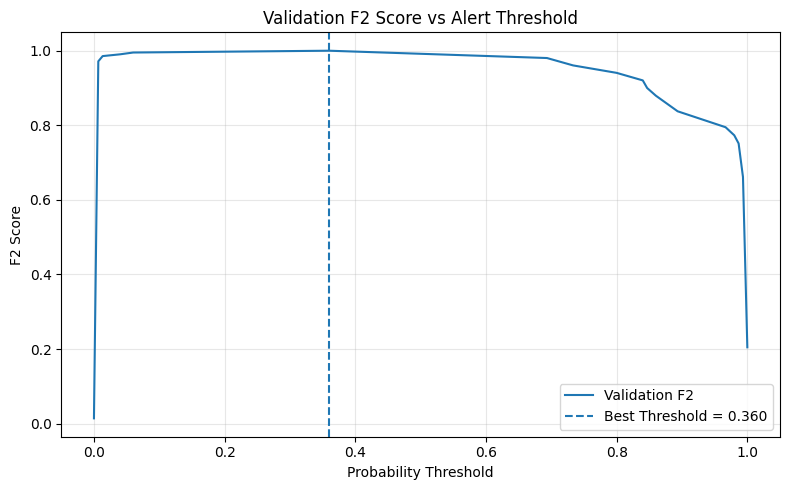


ALERT THRESHOLD TUNING COMPLETE
Default threshold      : 0.50000
Optimized threshold    : 0.36000
Default F2             : 0.98039
Optimized F2           : 1.00000
Optimized Recall       : 1.00000
Optimized Precision    : 1.00000
Future test data used : NO


In [34]:
# ============================================================
# 27. TUNE THE ALERT THRESHOLD WITH F2
# ============================================================
#
# WHAT:
# Finds the probability threshold that gives the highest
# F2-score on the validation dataset.
#
# WHY:
# In an early-warning system, missing a real waterlogging
# event can be more costly than giving some false alarms.
#
# F2 gives more importance to Recall than Precision.
#
# OUTPUT:
# Final warning threshold.
#
# IMPORTANT:
# Test data is NOT used in threshold tuning.
# ============================================================


# Only NEW import required in this section
from sklearn.metrics import precision_recall_curve


print("=" * 80)
print("27. ALERT THRESHOLD TUNING USING F2")
print("=" * 80)


# ============================================================
# 1. VALIDATION FEATURES
# ============================================================

X_threshold_val = X_val[
    selected_features
].copy()


# ============================================================
# 2. GET VALIDATION PROBABILITIES
# ============================================================
#
# tuned_pipeline was selected in Section 26.
#
# It was trained using training data only.
# Validation data has not been used to fit this model.
# ============================================================

val_probabilities = (

    tuned_pipeline

    .predict_proba(
        X_threshold_val
    )[:, 1]

)


print(
    "\nValidation samples:",
    f"{len(y_val):,}"
)


print(
    "Validation positives:",
    int(y_val.sum())
)


print(
    "Validation negatives:",
    int((y_val == 0).sum())
)


# ============================================================
# 3. PRECISION-RECALL VALUES FOR ALL THRESHOLDS
# ============================================================

precision_values, recall_values, thresholds = (

    precision_recall_curve(

        y_val,

        val_probabilities

    )

)


# Last precision/recall values do not have a corresponding
# threshold, so remove them.

precision_for_threshold = (
    precision_values[:-1]
)

recall_for_threshold = (
    recall_values[:-1]
)


# ============================================================
# 4. CALCULATE F2-SCORE
# ============================================================
#
# F-beta formula:
#
#        (1 + beta²) × Precision × Recall
# Fβ = -----------------------------------
#        beta² × Precision + Recall
#
# For F2:
# beta = 2
# beta² = 4
#
# Therefore Recall gets more importance.
# ============================================================

beta = 2


f2_scores = (

    (1 + beta**2)

    *

    (
        precision_for_threshold
        *
        recall_for_threshold
    )

    /

    (
        beta**2
        *
        precision_for_threshold

        +

        recall_for_threshold

        +

        1e-12
    )

)


# ============================================================
# 5. FIND BEST F2 THRESHOLD
# ============================================================

best_index = int(
    np.argmax(
        f2_scores
    )
)


best_threshold = float(
    thresholds[
        best_index
    ]
)


best_f2 = float(
    f2_scores[
        best_index
    ]
)


best_precision = float(
    precision_for_threshold[
        best_index
    ]
)


best_recall = float(
    recall_for_threshold[
        best_index
    ]
)


# ============================================================
# 6. DEFAULT THRESHOLD PERFORMANCE
# ============================================================

default_threshold = 0.50


default_prediction = (

    val_probabilities

    >=

    default_threshold

).astype(int)


default_precision = precision_score(

    y_val,

    default_prediction,

    zero_division=0

)


default_recall = recall_score(

    y_val,

    default_prediction,

    zero_division=0

)


default_f2 = fbeta_score(

    y_val,

    default_prediction,

    beta=2,

    zero_division=0

)


# ============================================================
# 7. TUNED THRESHOLD PREDICTIONS
# ============================================================

tuned_threshold_prediction = (

    val_probabilities

    >=

    best_threshold

).astype(int)


tuned_threshold_accuracy = accuracy_score(

    y_val,

    tuned_threshold_prediction

)


tuned_threshold_precision = precision_score(

    y_val,

    tuned_threshold_prediction,

    zero_division=0

)


tuned_threshold_recall = recall_score(

    y_val,

    tuned_threshold_prediction,

    zero_division=0

)


tuned_threshold_f1 = f1_score(

    y_val,

    tuned_threshold_prediction,

    zero_division=0

)


tuned_threshold_f2 = fbeta_score(

    y_val,

    tuned_threshold_prediction,

    beta=2,

    zero_division=0

)


# ============================================================
# 8. CONFUSION MATRIX VALUES
# ============================================================

y_val_array = y_val.to_numpy()


tn = int(

    (
        (y_val_array == 0)
        &
        (tuned_threshold_prediction == 0)
    ).sum()

)


fp = int(

    (
        (y_val_array == 0)
        &
        (tuned_threshold_prediction == 1)
    ).sum()

)


fn = int(

    (
        (y_val_array == 1)
        &
        (tuned_threshold_prediction == 0)
    ).sum()

)


tp = int(

    (
        (y_val_array == 1)
        &
        (tuned_threshold_prediction == 1)
    ).sum()

)


# ============================================================
# 9. DEFAULT VS F2-TUNED THRESHOLD
# ============================================================

threshold_comparison = pd.DataFrame({

    "Threshold_Type": [

        "Default Threshold",

        "F2 Optimized Threshold"

    ],

    "Threshold": [

        default_threshold,

        best_threshold

    ],

    "Precision": [

        default_precision,

        tuned_threshold_precision

    ],

    "Recall": [

        default_recall,

        tuned_threshold_recall

    ],

    "F2": [

        default_f2,

        tuned_threshold_f2

    ]

})


print()
print("=" * 80)
print("DEFAULT VS F2-TUNED THRESHOLD")
print("=" * 80)


display(

    threshold_comparison.round(5)

)


# ============================================================
# 10. FINAL WARNING THRESHOLD
# ============================================================

FINAL_WARNING_THRESHOLD = (
    best_threshold
)


print()
print("=" * 80)

print(
    "FINAL WARNING THRESHOLD"
)

print("=" * 80)


print(
    f"Threshold : "
    f"{FINAL_WARNING_THRESHOLD:.5f}"
)


print(
    f"Precision : "
    f"{best_precision:.5f}"
)


print(
    f"Recall    : "
    f"{best_recall:.5f}"
)


print(
    f"F2 Score  : "
    f"{best_f2:.5f}"
)


print()
print(
    "True Positives :",
    tp
)


print(
    "False Positives:",
    fp
)


print(
    "False Negatives:",
    fn
)


print(
    "True Negatives :",
    tn
)


# ============================================================
# 11. SAVE FINAL WARNING THRESHOLD
# ============================================================

threshold_info = {

    "threshold":
        FINAL_WARNING_THRESHOLD,

    "optimization_metric":
        "F2",

    "precision":
        best_precision,

    "recall":
        best_recall,

    "f2":
        best_f2,

    "beta":
        2

}


joblib.dump(

    threshold_info,

    MODEL_DIR
    /
    "waterlogging_alert_threshold.joblib"

)


print()
print(
    "Threshold saved:"
)


print(
    MODEL_DIR
    /
    "waterlogging_alert_threshold.joblib"
)


# ============================================================
# 12. F2 VS THRESHOLD PLOT
# ============================================================

plt.figure(
    figsize=(8, 5)
)


plt.plot(

    thresholds,

    f2_scores,

    label="Validation F2"

)


plt.axvline(

    FINAL_WARNING_THRESHOLD,

    linestyle="--",

    label=(
        f"Best Threshold = "
        f"{FINAL_WARNING_THRESHOLD:.3f}"
    )

)


plt.xlabel(
    "Probability Threshold"
)


plt.ylabel(
    "F2 Score"
)


plt.title(
    "Validation F2 Score vs Alert Threshold"
)


plt.legend()


plt.grid(
    alpha=0.3
)


plt.tight_layout()

plt.show()


# ============================================================
# 13. FINAL SUMMARY
# ============================================================

print()
print("=" * 80)

print(
    "ALERT THRESHOLD TUNING COMPLETE"
)

print("=" * 80)


print(
    f"Default threshold      : "
    f"{default_threshold:.5f}"
)


print(
    f"Optimized threshold    : "
    f"{FINAL_WARNING_THRESHOLD:.5f}"
)


print(
    f"Default F2             : "
    f"{default_f2:.5f}"
)


print(
    f"Optimized F2           : "
    f"{best_f2:.5f}"
)


print(
    f"Optimized Recall       : "
    f"{best_recall:.5f}"
)


print(
    f"Optimized Precision    : "
    f"{best_precision:.5f}"
)


print(
    "Future test data used : NO"
)


print("=" * 80)

# 28. Final evaluation on unseen future data

**What:** Retrains on train+validation and evaluates once on the latest test period.

**Why:** Test data must remain unseen until final evaluation.

**Output:** Final metrics and plots.

If weak labels are active, scores measure reproduction of the weak-label rule, not independently verified disaster accuracy.

28. FINAL EVALUATION ON UNSEEN FUTURE DATA

Fixed warning threshold: 0.36000

Training period:
2024-01-01 00:00:00 → 2026-04-22 03:00:00

Test period:
2026-04-22 06:00:00 → 2026-09-17 21:00:00

Chronological separation: True

Train + Validation rows: 80,856
Future Test rows: 14,280
Features: 30
Test positives: 379
Test negatives: 13901

Retraining final model...
Final training complete.

FINAL TEST PERFORMANCE


,Metric,Score
0,Accuracy,0.99937
1,Precision,0.97927
2,Recall,0.99736
3,F1 Score,0.98824
4,F2 Score,0.99369
5,ROC-AUC,0.99997
6,PR-AUC,0.99898



CONFUSION MATRIX


,Predicted No,Predicted Yes
Actual No Waterlogging,13893,8
Actual Waterlogging,1,378


True Positives  : 378
False Positives : 8
False Negatives : 1
True Negatives  : 13893


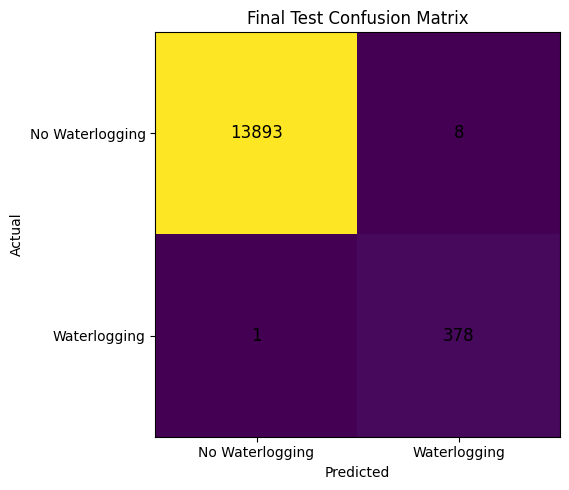

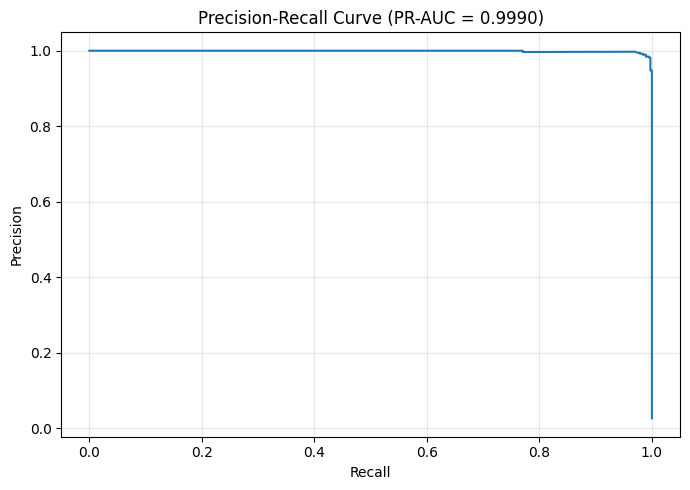

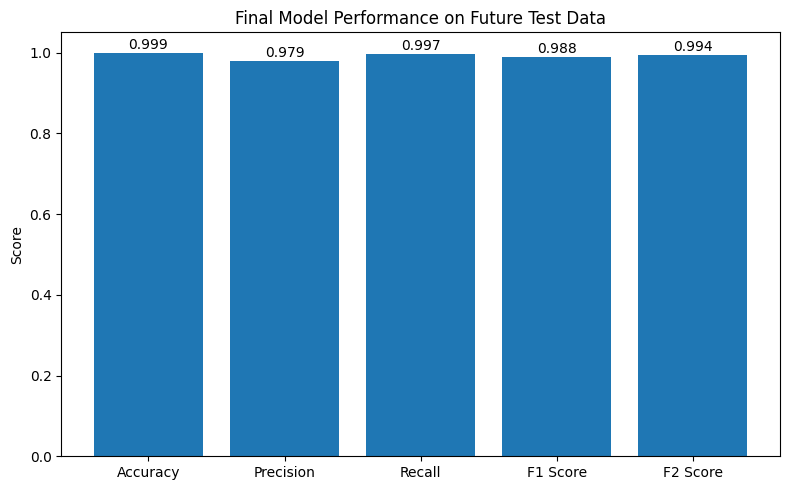


FINAL RESULT
Warning Threshold : 0.36000
Accuracy          : 0.99937
Precision         : 0.97927
Recall            : 0.99736
F1 Score          : 0.98824
F2 Score          : 0.99369
ROC-AUC           : 0.99997
PR-AUC            : 0.99898

TP=378 | FP=8 | FN=1 | TN=13893

Weak labels are active.
These scores measure reproduction of the weak-label waterlogging rule.
They are not independently verified real-world disaster accuracy.

Final model saved: models/final_waterlogging_model.joblib


In [35]:
# ============================================================
# 28. FINAL EVALUATION ON UNSEEN FUTURE DATA
# ============================================================
#
# WHAT:
# Retrain tuned Random Forest on Train + Validation
# and evaluate once on the future Test set.
#
# IMPORTANT:
# FINAL_WARNING_THRESHOLD was selected in Section 27.
# Test data is not used for tuning.
# ============================================================

print("=" * 75)
print("28. FINAL EVALUATION ON UNSEEN FUTURE DATA")
print("=" * 75)


# ============================================================
# 1. GET FIXED ALERT THRESHOLD
# ============================================================

if "FINAL_WARNING_THRESHOLD" not in globals():

    threshold_info = joblib.load(
        MODEL_DIR / "waterlogging_alert_threshold.joblib"
    )

    FINAL_WARNING_THRESHOLD = threshold_info["threshold"]


print(
    f"\nFixed warning threshold: "
    f"{FINAL_WARNING_THRESHOLD:.5f}"
)


# ============================================================
# 2. COMBINE TRAIN + VALIDATION
# ============================================================

final_train_df = (

    pd.concat(
        [train_df, val_df],
        ignore_index=True
    )

    .sort_values(
        ["datetime", "state", "district"]
    )

    .reset_index(drop=True)

)


# ============================================================
# 3. VERIFY TEST IS FUTURE DATA
# ============================================================

train_end = final_train_df["datetime"].max()
test_start = test_df["datetime"].min()
test_end = test_df["datetime"].max()


print("\nTraining period:")
print(
    final_train_df["datetime"].min(),
    "→",
    train_end
)


print("\nTest period:")
print(
    test_start,
    "→",
    test_end
)


if train_end >= test_start:

    raise ValueError(
        "Train/validation period overlaps test period."
    )


print("\nChronological separation: True")


# ============================================================
# 4. SELECT SAME 30 FEATURES
# ============================================================

X_final_train = final_train_df[
    selected_features
].copy()


y_final_train = final_train_df[
    "waterlogged"
].copy()


X_final_test = test_df[
    selected_features
].copy()


y_final_test = test_df[
    "waterlogged"
].copy()


print(
    "\nTrain + Validation rows:",
    f"{len(X_final_train):,}"
)


print(
    "Future Test rows:",
    f"{len(X_final_test):,}"
)


print(
    "Features:",
    X_final_train.shape[1]
)


print(
    "Test positives:",
    int(y_final_test.sum())
)


print(
    "Test negatives:",
    int((y_final_test == 0).sum())
)


# ============================================================
# 5. RETRAIN FINAL MODEL
# ============================================================
#
# clone() keeps tuned hyperparameters but removes
# previously learned values.
# ============================================================

final_model = clone(
    tuned_pipeline
)


print(
    "\nRetraining final model..."
)


final_model.fit(
    X_final_train,
    y_final_train
)


print(
    "Final training complete."
)


# ============================================================
# 6. TEST PROBABILITIES
# ============================================================

test_probability = (

    final_model

    .predict_proba(
        X_final_test
    )[:, 1]

)


# Use fixed F2 threshold from Section 27

test_prediction = (

    test_probability
    >=
    FINAL_WARNING_THRESHOLD

).astype(int)


# ============================================================
# 7. FINAL METRICS
# ============================================================

final_accuracy = accuracy_score(
    y_final_test,
    test_prediction
)


final_precision = precision_score(
    y_final_test,
    test_prediction,
    zero_division=0
)


final_recall = recall_score(
    y_final_test,
    test_prediction,
    zero_division=0
)


final_f1 = f1_score(
    y_final_test,
    test_prediction,
    zero_division=0
)


final_f2 = fbeta_score(
    y_final_test,
    test_prediction,
    beta=2,
    zero_division=0
)


final_roc_auc = roc_auc_score(
    y_final_test,
    test_probability
)


final_pr_auc = average_precision_score(
    y_final_test,
    test_probability
)


# ============================================================
# 8. CONFUSION MATRIX VALUES
# ============================================================

actual = y_final_test.to_numpy()


tn = int(
    ((actual == 0) & (test_prediction == 0)).sum()
)

fp = int(
    ((actual == 0) & (test_prediction == 1)).sum()
)

fn = int(
    ((actual == 1) & (test_prediction == 0)).sum()
)

tp = int(
    ((actual == 1) & (test_prediction == 1)).sum()
)


# ============================================================
# 9. FINAL METRIC TABLE
# ============================================================

final_metrics_df = pd.DataFrame({

    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "F2 Score",
        "ROC-AUC",
        "PR-AUC"
    ],

    "Score": [
        final_accuracy,
        final_precision,
        final_recall,
        final_f1,
        final_f2,
        final_roc_auc,
        final_pr_auc
    ]

})


print()
print("=" * 75)
print("FINAL TEST PERFORMANCE")
print("=" * 75)


display(
    final_metrics_df.round(5)
)


# ============================================================
# 10. CONFUSION MATRIX TABLE
# ============================================================

confusion_table = pd.DataFrame(

    [
        [tn, fp],
        [fn, tp]
    ],

    index=[
        "Actual No Waterlogging",
        "Actual Waterlogging"
    ],

    columns=[
        "Predicted No",
        "Predicted Yes"
    ]

)


print(
    "\nCONFUSION MATRIX"
)


display(
    confusion_table
)


print(
    f"True Positives  : {tp}"
)

print(
    f"False Positives : {fp}"
)

print(
    f"False Negatives : {fn}"
)

print(
    f"True Negatives  : {tn}"
)


# ============================================================
# 11. CONFUSION MATRIX PLOT
# ============================================================

matrix = np.array(
    [
        [tn, fp],
        [fn, tp]
    ]
)


plt.figure(
    figsize=(6, 5)
)


plt.imshow(
    matrix
)


for i in range(2):

    for j in range(2):

        plt.text(
            j,
            i,
            matrix[i, j],
            ha="center",
            va="center",
            fontsize=12
        )


plt.xticks(
    [0, 1],
    [
        "No Waterlogging",
        "Waterlogging"
    ]
)


plt.yticks(
    [0, 1],
    [
        "No Waterlogging",
        "Waterlogging"
    ]
)


plt.xlabel(
    "Predicted"
)


plt.ylabel(
    "Actual"
)


plt.title(
    "Final Test Confusion Matrix"
)


plt.tight_layout()
plt.show()


# ============================================================
# 12. PRECISION-RECALL CURVE
# ============================================================
#
# precision_recall_curve was already imported in Section 27.
# ============================================================

pr_precision, pr_recall, _ = (

    precision_recall_curve(
        y_final_test,
        test_probability
    )

)


plt.figure(
    figsize=(7, 5)
)


plt.plot(
    pr_recall,
    pr_precision
)


plt.xlabel(
    "Recall"
)


plt.ylabel(
    "Precision"
)


plt.title(
    f"Precision-Recall Curve "
    f"(PR-AUC = {final_pr_auc:.4f})"
)


plt.grid(
    alpha=0.3
)


plt.tight_layout()
plt.show()


# ============================================================
# 13. FINAL METRICS PLOT
# ============================================================

plot_metrics = final_metrics_df[
    final_metrics_df["Metric"].isin(
        [
            "Accuracy",
            "Precision",
            "Recall",
            "F1 Score",
            "F2 Score"
        ]
    )
]


plt.figure(
    figsize=(8, 5)
)


plt.bar(
    plot_metrics["Metric"],
    plot_metrics["Score"]
)


plt.ylim(
    0,
    1.05
)


plt.ylabel(
    "Score"
)


plt.title(
    "Final Model Performance on Future Test Data"
)


for i, value in enumerate(
    plot_metrics["Score"]
):

    plt.text(
        i,
        value + 0.01,
        f"{value:.3f}",
        ha="center"
    )


plt.tight_layout()
plt.show()


# ============================================================
# 14. SAVE FINAL MODEL
# ============================================================

final_model_path = (

    MODEL_DIR
    /
    "final_waterlogging_model.joblib"

)


joblib.dump(
    final_model,
    final_model_path
)


# ============================================================
# 15. SAVE FINAL TEST RESULTS
# ============================================================

final_predictions = test_df[
    [
        "state",
        "district",
        "datetime",
        "waterlogged"
    ]
].copy()


final_predictions[
    "prediction"
] = test_prediction


final_predictions[
    "probability"
] = test_probability


final_predictions.to_csv(

    MODEL_DIR
    /
    "final_test_predictions.csv",

    index=False

)


final_metrics_df.to_csv(

    MODEL_DIR
    /
    "final_test_metrics.csv",

    index=False

)


# ============================================================
# 16. WEAK-LABEL INTERPRETATION
# ============================================================

label_text = str(

    globals().get(
        "LABEL_MODE",
        globals().get(
            "label_mode",
            "UNKNOWN"
        )
    )

)


print()
print("=" * 75)
print("FINAL RESULT")
print("=" * 75)


print(
    f"Warning Threshold : "
    f"{FINAL_WARNING_THRESHOLD:.5f}"
)


print(
    f"Accuracy          : "
    f"{final_accuracy:.5f}"
)


print(
    f"Precision         : "
    f"{final_precision:.5f}"
)


print(
    f"Recall            : "
    f"{final_recall:.5f}"
)


print(
    f"F1 Score          : "
    f"{final_f1:.5f}"
)


print(
    f"F2 Score          : "
    f"{final_f2:.5f}"
)


print(
    f"ROC-AUC           : "
    f"{final_roc_auc:.5f}"
)


print(
    f"PR-AUC            : "
    f"{final_pr_auc:.5f}"
)


print()
print(
    f"TP={tp} | FP={fp} | "
    f"FN={fn} | TN={tn}"
)


if "WEAK" in label_text.upper():

    print()
    print(
        "Weak labels are active."
    )

    print(
        "These scores measure reproduction of the "
        "weak-label waterlogging rule."
    )

    print(
        "They are not independently verified "
        "real-world disaster accuracy."
    )


print()
print(
    "Final model saved:",
    final_model_path
)


print("=" * 75)

# 29. Compare and justify the best model



29. MODEL COMPARISON AND FINAL JUSTIFICATION


,Model,Accuracy,Precision,Recall,F1,F2,ROC_AUC,PR_AUC,Mean_ROC_AUC,Std_ROC_AUC
0,Random Forest,0.99993,1.00000,0.97561,0.98765,0.98039,1.0,1.00000,0.99875,0.00264
1,XGBoost,0.99993,1.00000,0.97561,0.98765,0.98039,1.0,0.99942,0.99731,0.00574
2,Logistic Regression,0.99958,0.87234,1.00000,0.93182,0.97156,1.0,0.99887,0.95685,0.09524
3,Extra Trees,0.99979,1.00000,0.92683,0.96203,0.94059,1.0,0.99882,0.99865,0.00271



Best Model: Tuned Random Forest
Alert Threshold: 0.36

Final Test Results
Accuracy : 0.99937
Precision: 0.97927
Recall   : 0.99736
F1 Score : 0.98824
F2 Score : 0.99369
ROC-AUC  : 0.99997
PR-AUC   : 0.99898


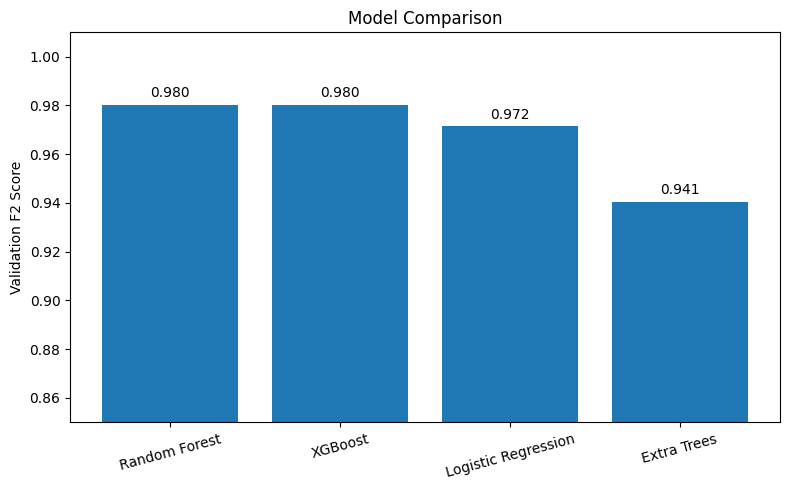


FINAL JUSTIFICATION
Tuned Random Forest was selected because it achieved strong Recall, F2, ROC-AUC and PR-AUC, while also showing stable time-aware cross-validation performance. The optimized alert threshold improves sensitivity for waterlogging warnings.

Weak-label note: results measure reproduction of the weak-label rule and are not independently verified real-world disaster accuracy.


In [36]:
print("=" * 80)
print("29. MODEL COMPARISON AND FINAL JUSTIFICATION")
print("=" * 80)

model_comparison = results_df.copy()

if "cv_summary_df" in globals():
    model_comparison = model_comparison.merge(
        cv_summary_df[["Model", "Mean_ROC_AUC", "Std_ROC_AUC"]],
        on="Model",
        how="left"
    )

model_comparison = model_comparison.sort_values(
    by=["F2", "Recall", "PR_AUC", "ROC_AUC"],
    ascending=False
).reset_index(drop=True)

display(
    model_comparison[
        [
            "Model",
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "F2",
            "ROC_AUC",
            "PR_AUC",
            "Mean_ROC_AUC",
            "Std_ROC_AUC"
        ]
    ].round(5)
)

final_model_name = "Tuned Random Forest"

print("\nBest Model:", final_model_name)
print("Alert Threshold:", round(FINAL_WARNING_THRESHOLD, 5))

print("\nFinal Test Results")
print("Accuracy :", round(final_accuracy, 5))
print("Precision:", round(final_precision, 5))
print("Recall   :", round(final_recall, 5))
print("F1 Score :", round(final_f1, 5))
print("F2 Score :", round(final_f2, 5))
print("ROC-AUC  :", round(final_roc_auc, 5))
print("PR-AUC   :", round(final_pr_auc, 5))

plot_data = model_comparison[["Model", "F2"]]

plt.figure(figsize=(8, 5))
plt.bar(plot_data["Model"], plot_data["F2"])
plt.ylim(0.85, 1.01)
plt.ylabel("Validation F2 Score")
plt.title("Model Comparison")

for i, value in enumerate(plot_data["F2"]):
    plt.text(i, value + 0.003, f"{value:.3f}", ha="center")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

print("\nFINAL JUSTIFICATION")
print(
    "Tuned Random Forest was selected because it achieved strong "
    "Recall, F2, ROC-AUC and PR-AUC, while also showing stable "
    "time-aware cross-validation performance. The optimized alert "
    "threshold improves sensitivity for waterlogging warnings."
)

print(
    "\nWeak-label note: results measure reproduction of the weak-label "
    "rule and are not independently verified real-world disaster accuracy."
)

# 30. Feature importance



30. PERMUTATION FEATURE IMPORTANCE

TOP 15 FEATURES


,Feature,Importance,Std
0,rainfall_24h,0.00032,0.00007
1,rainfall_7d,0.00025,0.00003
2,antecedent_rain_7d,0.00019,0.00002
3,rain_low_elevation_interaction,0.00004,0.00000
4,antecedent_rain_24h,0.00004,0.00000
5,antecedent_rain_3d,0.00003,0.00000
6,longitude,0.00003,0.00001
7,rainfall_3d,0.00002,0.00000
8,elevation,0.00002,0.00002
9,antecedent_rain_index,0.00002,0.00000


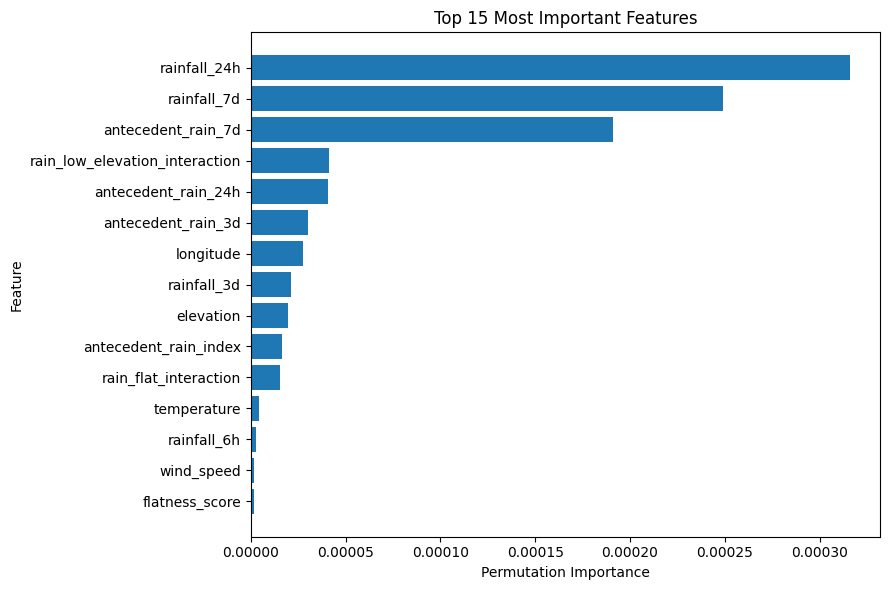


Most Important Feature: rainfall_24h
Importance: 0.00032


In [37]:
# ============================================================
# 30. FEATURE IMPORTANCE
# ============================================================

from sklearn.inspection import permutation_importance

print("=" * 70)
print("30. PERMUTATION FEATURE IMPORTANCE")
print("=" * 70)

# Use a sample for faster computation
sample_size = min(5000, len(X_final_test))

X_imp = X_final_test.sample(
    n=sample_size,
    random_state=42
)

y_imp = y_final_test.loc[X_imp.index]

result = permutation_importance(
    final_model,
    X_imp,
    y_imp,
    scoring="roc_auc",
    n_repeats=3,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_imp.columns,
    "Importance": result.importances_mean,
    "Std": result.importances_std
}).sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

top_features = importance_df.head(15)

print("\nTOP 15 FEATURES")
display(top_features.round(5))

plt.figure(figsize=(9, 6))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Permutation Importance")
plt.ylabel("Feature")
plt.title("Top 15 Most Important Features")

plt.tight_layout()
plt.show()

print("\nMost Important Feature:", top_features.iloc[0]["Feature"])
print("Importance:", round(top_features.iloc[0]["Importance"], 5))

# 31. Save model, metadata and processed dataset



In [38]:
# ============================================================
# 31. SAVE MODEL, METADATA AND PROCESSED DATASET
# ============================================================

import json

ARTIFACT_DIR = Path("artifacts")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

model_path = ARTIFACT_DIR / "india_waterlogging_model.joblib"
metadata_path = ARTIFACT_DIR / "india_waterlogging_metadata.json"
data_path = ARTIFACT_DIR / "india_waterlogging_processed.csv"


# Save complete preprocessing + classifier pipeline
joblib.dump(
    final_model,
    model_path
)


# Save processed historical dataset
df.to_csv(
    data_path,
    index=False
)


# Save metadata
metadata = {
    "project": "India Waterlogging Early Warning System",
    "model": "Tuned Random Forest",
    "target": "waterlogged",
    "selected_features": selected_features,
    "n_features": len(selected_features),

    "warning_threshold": float(FINAL_WARNING_THRESHOLD),

    "label_mode": str(
        globals().get(
            "LABEL_MODE",
            globals().get("label_mode", "UNKNOWN")
        )
    ),

    "training_start": str(
        final_train_df["datetime"].min()
    ),

    "training_end": str(
        final_train_df["datetime"].max()
    ),

    "test_start": str(
        test_df["datetime"].min()
    ),

    "test_end": str(
        test_df["datetime"].max()
    ),

    "processed_rows": int(len(df)),

    "final_metrics": {
        "accuracy": float(final_accuracy),
        "precision": float(final_precision),
        "recall": float(final_recall),
        "f1": float(final_f1),
        "f2": float(final_f2),
        "roc_auc": float(final_roc_auc),
        "pr_auc": float(final_pr_auc)
    },

    "confusion_matrix": {
        "true_positive": int(tp),
        "false_positive": int(fp),
        "false_negative": int(fn),
        "true_negative": int(tn)
    },

    "best_hyperparameters": (
        best_params
        if "best_params" in globals()
        else {}
    ),

    "weak_label_note": (
        "Scores measure reproduction of the weak-label rule "
        "and are not independently verified disaster accuracy."
    )
}


with open(
    metadata_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        metadata,
        file,
        indent=4,
        default=str
    )


print("=" * 70)
print("31. ARTIFACTS SAVED")
print("=" * 70)

print("Model    :", model_path)
print("Metadata :", metadata_path)
print("Dataset  :", data_path)

print()
print("Rows     :", f"{len(df):,}")
print("Features :", len(selected_features))
print("Threshold:", round(FINAL_WARNING_THRESHOLD, 5))

print("=" * 70)

31. ARTIFACTS SAVED
Model    : artifacts/india_waterlogging_model.joblib
Metadata : artifacts/india_waterlogging_metadata.json
Dataset  : artifacts/india_waterlogging_processed.csv

Rows     : 95,136
Features : 30
Threshold: 0.36


# 32. Live recent-data feature builder
This section fetches the latest 7 days of hourly weather data for a given latitude and longitude.

It calculates the same rainfall windows used during training:

- rainfall_1h
- rainfall_3h
- rainfall_6h
- rainfall_24h
- rainfall_3d
- rainfall_7d

It also collects temperature, humidity, wind speed, pressure, elevation, and slope.

The latest record is then passed through the same feature-engineering logic used during training and converted into the final 30 model input features.

The output is a single live feature row ready for real-time waterlogging prediction.


In [39]:
# ============================================================
# 32. LIVE RECENT-DATA FEATURE BUILDER
# ============================================================

def get_live_terrain(lat, lon):
    offset = 0.01

    lats = [lat, lat + offset, lat - offset, lat, lat]
    lons = [lon, lon, lon, lon + offset, lon - offset]

    r = requests.get(
        "https://api.open-meteo.com/v1/elevation",
        params={
            "latitude": ",".join(map(str, lats)),
            "longitude": ",".join(map(str, lons))
        },
        timeout=20
    )
    r.raise_for_status()

    z = np.array(r.json()["elevation"], dtype=float)

    elevation = z[0]

    north_south_distance = 2 * offset * 111320
    east_west_distance = (
        2 * offset * 111320 *
        np.cos(np.radians(lat))
    )

    dz_dy = (z[1] - z[2]) / north_south_distance
    dz_dx = (z[3] - z[4]) / east_west_distance

    slope = np.degrees(
        np.arctan(
            np.sqrt(dz_dx**2 + dz_dy**2)
        )
    )

    return float(elevation), float(slope)


def build_live_features(lat, lon, state="LIVE", district="LIVE"):

    url = "https://api.open-meteo.com/v1/forecast"

    params = {
        "latitude": lat,
        "longitude": lon,
        "hourly": [
            "temperature_2m",
            "relative_humidity_2m",
            "precipitation",
            "rain",
            "wind_speed_10m",
            "surface_pressure"
        ],
        "past_days": 7,
        "forecast_days": 1,
        "timezone": "Asia/Kolkata"
    }

    r = requests.get(
        url,
        params=params,
        timeout=30
    )

    r.raise_for_status()
    data = r.json()

    hourly = pd.DataFrame(
        data["hourly"]
    )

    hourly["datetime"] = pd.to_datetime(
        hourly["time"]
    )

    now_india = (
        pd.Timestamp.now(
            tz="Asia/Kolkata"
        )
        .tz_localize(None)
        .floor("h")
    )

    hourly = (
        hourly[
            hourly["datetime"] <= now_india
        ]
        .sort_values("datetime")
        .reset_index(drop=True)
    )

    if len(hourly) < 168:
        raise ValueError(
            "Less than 7 days of hourly data available."
        )

    hourly["rainfall_1h"] = (
        hourly["rain"]
        .fillna(0)
        .clip(lower=0)
    )

    hourly["rainfall_3h"] = (
        hourly["rainfall_1h"]
        .rolling(3, min_periods=1)
        .sum()
    )

    hourly["rainfall_6h"] = (
        hourly["rainfall_1h"]
        .rolling(6, min_periods=1)
        .sum()
    )

    hourly["rainfall_24h"] = (
        hourly["rainfall_1h"]
        .rolling(24, min_periods=1)
        .sum()
    )

    hourly["rainfall_3d"] = (
        hourly["rainfall_1h"]
        .rolling(72, min_periods=1)
        .sum()
    )

    hourly["rainfall_7d"] = (
        hourly["rainfall_1h"]
        .rolling(168, min_periods=1)
        .sum()
    )

    latest = hourly.iloc[-1]

    elevation, slope = get_live_terrain(
        lat,
        lon
    )

    live_row = pd.DataFrame([{
        "state": state,
        "district": district,
        "datetime": latest["datetime"],

        "temperature": latest["temperature_2m"],
        "humidity": latest["relative_humidity_2m"],
        "wind_speed": latest["wind_speed_10m"],
        "pressure": latest["surface_pressure"],

        "latitude": lat,
        "longitude": lon,

        "rainfall_1h": latest["rainfall_1h"],
        "rainfall_3h": latest["rainfall_3h"],
        "rainfall_6h": latest["rainfall_6h"],
        "rainfall_24h": latest["rainfall_24h"],
        "rainfall_3d": latest["rainfall_3d"],
        "rainfall_7d": latest["rainfall_7d"],

        "elevation": elevation,
        "slope": slope
    }])

    live_row = engineer_ml_features(
        live_row
    )

    live_features = live_row[
        selected_features
    ].copy()

    print("=" * 70)
    print("LIVE FEATURE ROW")
    print("=" * 70)

    print(
        "Location:",
        state,
        "-",
        district
    )

    print(
        "Coordinates:",
        lat,
        lon
    )

    print(
        "Latest time:",
        latest["datetime"]
    )

    print(
        "Rain 1h :",
        round(latest["rainfall_1h"], 2),
        "mm"
    )

    print(
        "Rain 24h:",
        round(latest["rainfall_24h"], 2),
        "mm"
    )

    print(
        "Rain 3d :",
        round(latest["rainfall_3d"], 2),
        "mm"
    )

    print(
        "Rain 7d :",
        round(latest["rainfall_7d"], 2),
        "mm"
    )

    print(
        "Elevation:",
        round(elevation, 2),
        "m"
    )

    print(
        "Slope:",
        round(slope, 4)
    )

    print(
        "Features:",
        live_features.shape[1]
    )

    display(
        live_features
    )

    return live_features


# Example
live_features = build_live_features(
    16.3067,
    80.4365,
    state="Andhra Pradesh",
    district="Guntur"
)

LIVE FEATURE ROW
Location: Andhra Pradesh - Guntur
Coordinates: 16.3067 80.4365
Latest time: 2026-09-17 23:00:00
Rain 1h : 0.8 mm
Rain 24h: 1.8 mm
Rain 3d : 4.3 mm
Rain 7d : 21.1 mm
Elevation: 39.0 m
Slope: 0.094
Features: 30


,temperature,humidity,wind_speed,pressure,latitude,longitude,rainfall_1h,rainfall_3h,rainfall_6h,rainfall_24h,...,hour_sin,hour_cos,antecedent_rain_24h,antecedent_rain_3d,antecedent_rain_7d,antecedent_rain_index,short_term_rain_ratio,flatness_score,rain_flat_interaction,rain_low_elevation_interaction
0,26.7,95,9.5,1006.0,16.3067,80.4365,0.8,0.8,0.8,1.8,...,-0.258819,0.965926,1.0,3.5,20.3,1.43,0.444444,0.914075,1.645336,1.294964


# 33. IMD live AWS overlay



In [40]:
# ============================================================
# 33. IMD LIVE AWS/ARG OVERLAY
# ============================================================

IMD_AWS_URL = "https://api.imd.gov.in/api/v1/aws_data"


def fetch_imd_aws():

    try:
        r = requests.get(IMD_AWS_URL, timeout=30)
        r.raise_for_status()

        data = r.json()

        if isinstance(data, list):
            records = data

        elif isinstance(data, dict):
            records = []

            for key in ["data", "records", "result", "results"]:
                if isinstance(data.get(key), list):
                    records = data[key]
                    break

            if not records and "Latitude" in data:
                records = [data]

        else:
            return pd.DataFrame()

        df = pd.DataFrame(records)

        if df.empty:
            return df

        df.columns = [
            str(c).strip().upper().replace(" ", "_")
            for c in df.columns
        ]

        numeric_cols = [
            "LATITUDE",
            "LONGITUDE",
            "CURR_TEMP",
            "RH",
            "WIND_SPEED",
            "MSLP"
        ]

        for col in numeric_cols:
            if col in df.columns:
                df[col] = pd.to_numeric(
                    df[col],
                    errors="coerce"
                )

        if "DATE" in df.columns and "TIME" in df.columns:

            df["OBS_DATETIME"] = pd.to_datetime(
                df["DATE"].astype(str)
                + " "
                + df["TIME"].astype(str),
                errors="coerce"
            )

        df = df.dropna(
            subset=["LATITUDE", "LONGITUDE"]
        ).reset_index(drop=True)

        return df

    except Exception as e:

        print("IMD AWS unavailable:", e)
        return pd.DataFrame()


def nearest_imd_station(
    imd_df,
    lat,
    lon,
    max_km=100
):

    if imd_df.empty:
        return None

    lat1 = np.radians(lat)
    lon1 = np.radians(lon)

    lat2 = np.radians(
        imd_df["LATITUDE"].to_numpy()
    )

    lon2 = np.radians(
        imd_df["LONGITUDE"].to_numpy()
    )

    a = (
        np.sin((lat2 - lat1) / 2) ** 2
        +
        np.cos(lat1)
        * np.cos(lat2)
        * np.sin((lon2 - lon1) / 2) ** 2
    )

    distance = (
        6371
        * 2
        * np.arcsin(np.sqrt(a))
    )

    temp = imd_df.copy()
    temp["DISTANCE_KM"] = distance

    nearest = temp.loc[
        temp["DISTANCE_KM"].idxmin()
    ]

    if nearest["DISTANCE_KM"] > max_km:
        return None

    return nearest


def mslp_to_surface_pressure(
    mslp,
    elevation,
    temperature
):

    temp_k = temperature + 273.15

    return float(
        mslp
        *
        np.exp(
            -9.80665 * elevation
            /
            (287.05 * temp_k)
        )
    )


def apply_imd_overlay(
    live_features,
    imd_df,
    lat,
    lon
):

    output = live_features.copy()

    station = nearest_imd_station(
        imd_df,
        lat,
        lon
    )

    if station is None:

        print("Using fallback weather values.")
        return output, None, "FALLBACK"

    if pd.notna(station.get("CURR_TEMP")):
        output["temperature"] = station["CURR_TEMP"]

    if pd.notna(station.get("RH")):
        output["humidity"] = station["RH"]

    if pd.notna(station.get("WIND_SPEED")):
        output["wind_speed"] = station["WIND_SPEED"]

    if pd.notna(station.get("MSLP")):

        output["pressure"] = mslp_to_surface_pressure(
            station["MSLP"],
            float(output["elevation"].iloc[0]),
            float(output["temperature"].iloc[0])
        )

    return output, station, "IMD_AWS"


# Fetch current IMD stations
imd_current_df = fetch_imd_aws()

print("=" * 70)
print("IMD AWS/ARG LIVE DATA")
print("=" * 70)

print(
    "Stations received:",
    len(imd_current_df)
)


# Apply IMD overlay to Section 32 live row
live_features_imd, nearest_station, weather_source = (
    apply_imd_overlay(
        live_features,
        imd_current_df,
        16.3067,
        80.4365
    )
)


print(
    "\nWeather source:",
    weather_source
)


if nearest_station is not None:

    print(
        "Nearest station:",
        nearest_station.get("STATION", "Unknown")
    )

    print(
        "District:",
        nearest_station.get("DISTRICT", "Unknown")
    )

    print(
        "Distance:",
        round(
            nearest_station["DISTANCE_KM"],
            2
        ),
        "km"
    )

    print(
        "IMD Temperature:",
        nearest_station.get("CURR_TEMP")
    )

    print(
        "IMD RH:",
        nearest_station.get("RH")
    )

    print(
        "IMD Wind:",
        nearest_station.get("WIND_SPEED")
    )

    print(
        "IMD MSLP:",
        nearest_station.get("MSLP")
    )


print(
    "\nFinal feature shape:",
    live_features_imd.shape
)

display(
    live_features_imd
)

IMD AWS unavailable: 401 Client Error: Unauthorized for url: https://api.imd.gov.in/api/v1/aws_data
IMD AWS/ARG LIVE DATA
Stations received: 0
Using fallback weather values.

Weather source: FALLBACK

Final feature shape: (1, 30)


,temperature,humidity,wind_speed,pressure,latitude,longitude,rainfall_1h,rainfall_3h,rainfall_6h,rainfall_24h,...,hour_sin,hour_cos,antecedent_rain_24h,antecedent_rain_3d,antecedent_rain_7d,antecedent_rain_index,short_term_rain_ratio,flatness_score,rain_flat_interaction,rain_low_elevation_interaction
0,26.7,95,9.5,1006.0,16.3067,80.4365,0.8,0.8,0.8,1.8,...,-0.258819,0.965926,1.0,3.5,20.3,1.43,0.444444,0.914075,1.645336,1.294964


“The system attempts to overlay current IMD AWS observations. If IMD access is unavailable or unauthorized, the pipeline automatically retains the fallback live weather features and continues prediction.”

# 34. Build a live district grid



In [41]:
# ============================================================
# 34. BUILD A LIVE DISTRICT GRID
# ============================================================

def build_district_grid(
    state,
    district,
    south,
    north,
    west,
    east,
    grid_size=5
):

    latitudes = np.linspace(
        south,
        north,
        grid_size
    )

    longitudes = np.linspace(
        west,
        east,
        grid_size
    )

    points = []

    point_id = 1

    for lat in latitudes:

        for lon in longitudes:

            points.append({
                "point_id": point_id,
                "state": state,
                "district": district,
                "latitude": round(float(lat), 6),
                "longitude": round(float(lon), 6)
            })

            point_id += 1

    return pd.DataFrame(points)


# Example demo bounding box for Guntur area
district_grid = build_district_grid(
    state="Andhra Pradesh",
    district="Guntur",
    south=16.15,
    north=16.45,
    west=80.25,
    east=80.65,
    grid_size=5
)


print("=" * 70)
print("34. LIVE DISTRICT GRID")
print("=" * 70)

print("District:", district_grid["district"].iloc[0])
print("Grid points:", len(district_grid))

print(
    "Latitude range:",
    district_grid["latitude"].min(),
    "to",
    district_grid["latitude"].max()
)

print(
    "Longitude range:",
    district_grid["longitude"].min(),
    "to",
    district_grid["longitude"].max()
)

display(district_grid)

print(
    "\nNote: Current grid uses a rectangular bounding box. "
    "For production, use an authoritative district polygon."
)

34. LIVE DISTRICT GRID
District: Guntur
Grid points: 25
Latitude range: 16.15 to 16.45
Longitude range: 80.25 to 80.65


,point_id,state,district,latitude,longitude
0,1,Andhra Pradesh,Guntur,16.150,80.25
1,2,Andhra Pradesh,Guntur,16.150,80.35
2,3,Andhra Pradesh,Guntur,16.150,80.45
3,4,Andhra Pradesh,Guntur,16.150,80.55
4,5,Andhra Pradesh,Guntur,16.150,80.65
5,6,Andhra Pradesh,Guntur,16.225,80.25
6,7,Andhra Pradesh,Guntur,16.225,80.35
7,8,Andhra Pradesh,Guntur,16.225,80.45
8,9,Andhra Pradesh,Guntur,16.225,80.55
9,10,Andhra Pradesh,Guntur,16.225,80.65



Note: Current grid uses a rectangular bounding box. For production, use an authoritative district polygon.


# 35. 🔴 Enter any Indian state + district and predict CURRENT risk

Run this cell **after model training**.

Example:

```text
Enter State: Andhra Pradesh
Enter District: Guntur
```

It:
- geocodes the district,
- creates grid points,
- downloads latest 7-day rainfall/current weather,
- gets terrain/LULC/drainage,
- overlays nearest IMD AWS data when available,
- predicts risk for every grid cell,
- prints overall district risk,
- saves a CSV and HTML map.

**Output:** LOW / MEDIUM / HIGH risk and highest-risk grid cells.

In [42]:
# ============================================================
# 35. LIVE DISTRICT WATERLOGGING RISK PREDICTION
# ============================================================

from geopy.geocoders import Nominatim
import folium


if "FINAL_WARNING_THRESHOLD" not in globals():
    threshold_info = joblib.load(
        ARTIFACT_DIR / "waterlogging_alert_threshold.joblib"
    )
    FINAL_WARNING_THRESHOLD = threshold_info["threshold"]


def geocode_indian_district(state, district):

    geolocator = Nominatim(
        user_agent="india_waterlogging_model"
    )

    location = geolocator.geocode(
        {
            "county": district,
            "state": state,
            "country": "India"
        },
        exactly_one=True,
        addressdetails=True,
        country_codes="in"
    )

    if location is None:
        location = geolocator.geocode(
            f"{district} district, {state}, India",
            exactly_one=True,
            addressdetails=True,
            country_codes="in"
        )

    if location is None:
        raise ValueError("District not found.")

    bbox = location.raw.get("boundingbox")

    if bbox is None:
        raise ValueError("District bounding box not available.")

    south, north, west, east = map(float, bbox)

    return {
        "display_name": location.address,
        "latitude": float(location.latitude),
        "longitude": float(location.longitude),
        "south": south,
        "north": north,
        "west": west,
        "east": east
    }


def make_bbox_grid(geo, grid_size=5):

    latitudes = np.linspace(
        geo["south"],
        geo["north"],
        grid_size
    )

    longitudes = np.linspace(
        geo["west"],
        geo["east"],
        grid_size
    )

    rows = []
    grid_id = 1

    for lat in latitudes:
        for lon in longitudes:

            rows.append({
                "grid_id": f"G{grid_id:02d}",
                "latitude": float(lat),
                "longitude": float(lon)
            })

            grid_id += 1

    return pd.DataFrame(rows)


def latest_grid_features(lat, lon):

    url = "https://api.open-meteo.com/v1/forecast"

    params = {
        "latitude": lat,
        "longitude": lon,
        "hourly": [
            "temperature_2m",
            "relative_humidity_2m",
            "rain",
            "wind_speed_10m",
            "surface_pressure"
        ],
        "past_days": 7,
        "forecast_days": 1,
        "timezone": "Asia/Kolkata"
    }

    r = requests.get(
        url,
        params=params,
        timeout=30
    )

    r.raise_for_status()

    hourly = pd.DataFrame(
        r.json()["hourly"]
    )

    hourly["datetime"] = pd.to_datetime(
        hourly["time"]
    )

    now_india = (
        pd.Timestamp.now(tz="Asia/Kolkata")
        .tz_localize(None)
        .floor("h")
    )

    hourly = (
        hourly[
            hourly["datetime"] <= now_india
        ]
        .sort_values("datetime")
        .reset_index(drop=True)
    )

    if len(hourly) < 168:
        raise ValueError(
            "Insufficient 7-day weather history."
        )

    hourly["rainfall_1h"] = (
        hourly["rain"]
        .fillna(0)
        .clip(lower=0)
    )

    hourly["rainfall_3h"] = (
        hourly["rainfall_1h"]
        .rolling(3, min_periods=1)
        .sum()
    )

    hourly["rainfall_6h"] = (
        hourly["rainfall_1h"]
        .rolling(6, min_periods=1)
        .sum()
    )

    hourly["rainfall_24h"] = (
        hourly["rainfall_1h"]
        .rolling(24, min_periods=1)
        .sum()
    )

    hourly["rainfall_3d"] = (
        hourly["rainfall_1h"]
        .rolling(72, min_periods=1)
        .sum()
    )

    hourly["rainfall_7d"] = (
        hourly["rainfall_1h"]
        .rolling(168, min_periods=1)
        .sum()
    )

    latest = hourly.iloc[-1]

    elevation, slope = get_live_terrain(
        lat,
        lon
    )

    row = pd.DataFrame([{
        "datetime": latest["datetime"],

        "temperature":
            latest["temperature_2m"],

        "humidity":
            latest["relative_humidity_2m"],

        "wind_speed":
            latest["wind_speed_10m"],

        "pressure":
            latest["surface_pressure"],

        "latitude": lat,
        "longitude": lon,

        "rainfall_1h":
            latest["rainfall_1h"],

        "rainfall_3h":
            latest["rainfall_3h"],

        "rainfall_6h":
            latest["rainfall_6h"],

        "rainfall_24h":
            latest["rainfall_24h"],

        "rainfall_3d":
            latest["rainfall_3d"],

        "rainfall_7d":
            latest["rainfall_7d"],

        "elevation": elevation,
        "slope": slope
    }])

    row = engineer_ml_features(row)

    return row[selected_features].copy()


def overlay_imd_quiet(features, imd_df, lat, lon):

    if imd_df is None or imd_df.empty:
        return features, None, "FALLBACK"

    station = nearest_imd_station(
        imd_df,
        lat,
        lon
    )

    if station is None:
        return features, None, "FALLBACK"

    output = features.copy()

    temp = station.get("CURR_TEMP")
    humidity = station.get("RH")
    wind = station.get("WIND_SPEED")
    mslp = station.get("MSLP")

    if pd.notna(temp):
        output.loc[:, "temperature"] = float(temp)

    if pd.notna(humidity):
        output.loc[:, "humidity"] = float(humidity)

    if pd.notna(wind):
        output.loc[:, "wind_speed"] = float(wind)

    if pd.notna(mslp):

        output.loc[:, "pressure"] = (
            mslp_to_surface_pressure(
                float(mslp),
                float(output["elevation"].iloc[0]),
                float(output["temperature"].iloc[0])
            )
        )

    return output, station, "IMD_AWS"


def risk_level(probability):

    if probability >= FINAL_WARNING_THRESHOLD:
        return "HIGH"

    if probability >= (
        FINAL_WARNING_THRESHOLD * 0.60
    ):
        return "MEDIUM"

    return "LOW"


def safe_slug(text):

    return (
        str(text)
        .strip()
        .lower()
        .replace(" ", "_")
        .replace("/", "_")
    )


# ------------------------------------------------------------
# INPUT
# ------------------------------------------------------------

LIVE_STATE = input(
    "Enter State: "
).strip()

LIVE_DISTRICT = input(
    "Enter District: "
).strip()

LIVE_GRID_SIZE = 5


# ------------------------------------------------------------
# GEOCODE
# ------------------------------------------------------------

print("\nFinding district...")

geo = geocode_indian_district(
    LIVE_STATE,
    LIVE_DISTRICT
)


print(
    "\nResolved:",
    geo["display_name"]
)

print(
    "Center:",
    geo["latitude"],
    geo["longitude"]
)

print(
    "BBox:",
    geo["south"],
    geo["west"],
    geo["north"],
    geo["east"]
)


# ------------------------------------------------------------
# GRID
# ------------------------------------------------------------

live_grid = make_bbox_grid(
    geo,
    LIVE_GRID_SIZE
)


print(
    "\nGrid points:",
    len(live_grid)
)


# ------------------------------------------------------------
# FETCH IMD ONCE
# ------------------------------------------------------------

imd_current_df = fetch_imd_aws()


if imd_current_df.empty:
    print(
        "IMD unavailable - fallback weather will be used."
    )
else:
    print(
        "IMD stations available:",
        len(imd_current_df)
    )


# ------------------------------------------------------------
# GRID PREDICTION
# ------------------------------------------------------------

live_rows = []


for i, point in live_grid.iterrows():

    try:

        features = latest_grid_features(
            point["latitude"],
            point["longitude"]
        )


        features, station, source = overlay_imd_quiet(
            features,
            imd_current_df,
            point["latitude"],
            point["longitude"]
        )


        probability = float(
            final_model.predict_proba(
                features[selected_features]
            )[0, 1]
        )


        level = risk_level(
            probability
        )


        warning = int(
            probability
            >=
            FINAL_WARNING_THRESHOLD
        )


        station_name = None
        station_distance = np.nan


        if station is not None:

            station_name = (
                station.get("STATION")
                or station.get("CALL_SIGN")
                or station.get("ID")
            )

            station_distance = (
                station.get(
                    "DISTANCE_KM",
                    np.nan
                )
            )


        row = {
            "grid_id":
                point["grid_id"],

            "state":
                LIVE_STATE,

            "district":
                LIVE_DISTRICT,

            "latitude":
                point["latitude"],

            "longitude":
                point["longitude"],

            "datetime":
                features.get(
                    "datetime",
                    pd.Series([pd.NaT])
                ).iloc[0]
                if "datetime" in features.columns
                else pd.Timestamp.now(),

            "rainfall_1h":
                float(
                    features["rainfall_1h"].iloc[0]
                ),

            "rainfall_3h":
                float(
                    features["rainfall_3h"].iloc[0]
                ),

            "rainfall_6h":
                float(
                    features["rainfall_6h"].iloc[0]
                ),

            "rainfall_24h":
                float(
                    features["rainfall_24h"].iloc[0]
                ),

            "rainfall_3d":
                float(
                    features["rainfall_3d"].iloc[0]
                ),

            "rainfall_7d":
                float(
                    features["rainfall_7d"].iloc[0]
                ),

            "temperature":
                float(
                    features["temperature"].iloc[0]
                ),

            "humidity":
                float(
                    features["humidity"].iloc[0]
                ),

            "wind_speed":
                float(
                    features["wind_speed"].iloc[0]
                ),

            "pressure":
                float(
                    features["pressure"].iloc[0]
                ),

            "elevation":
                float(
                    features["elevation"].iloc[0]
                ),

            "slope":
                float(
                    features["slope"].iloc[0]
                ),

            "waterlogging_probability":
                probability,

            "waterlogging_probability_percent":
                probability * 100,

            "risk_level":
                level,

            "warning":
                warning,

            "weather_source":
                source,

            "imd_station":
                station_name,

            "imd_station_distance_km":
                station_distance
        }


        live_rows.append(row)


        print(
            f"{i+1:02d}/{len(live_grid)} "
            f"{point['grid_id']} | "
            f"{level} | "
            f"{probability*100:.2f}%"
        )


    except Exception as exc:

        print(
            f"{i+1:02d}/{len(live_grid)} "
            f"{point['grid_id']} failed: "
            f"{exc}"
        )


# ------------------------------------------------------------
# RESULTS
# ------------------------------------------------------------

live_df = pd.DataFrame(
    live_rows
)


if live_df.empty:
    raise ValueError(
        "No live grid predictions completed."
    )


risk_order = {
    "LOW": 0,
    "MEDIUM": 1,
    "HIGH": 2
}


district_risk = max(
    live_df["risk_level"],
    key=lambda x: risk_order[x]
)


avg_risk = (
    live_df[
        "waterlogging_probability"
    ].mean()
)


max_risk = (
    live_df[
        "waterlogging_probability"
    ].max()
)


high_cells = int(
    (
        live_df["risk_level"]
        ==
        "HIGH"
    ).sum()
)


medium_cells = int(
    (
        live_df["risk_level"]
        ==
        "MEDIUM"
    ).sum()
)


low_cells = int(
    (
        live_df["risk_level"]
        ==
        "LOW"
    ).sum()
)


warning_cells = int(
    live_df["warning"].sum()
)


# ------------------------------------------------------------
# SUMMARY
# ------------------------------------------------------------

print()
print("=" * 70)
print("CURRENT DISTRICT WATERLOGGING EARLY-WARNING RESULT")
print("=" * 70)

print(
    "State                 :",
    LIVE_STATE
)

print(
    "District              :",
    LIVE_DISTRICT
)

print(
    "Average probability   :",
    f"{avg_risk*100:.2f}%"
)

print(
    "Maximum grid risk     :",
    f"{max_risk*100:.2f}%"
)

print(
    "Low-risk cells        :",
    low_cells
)

print(
    "Medium-risk cells     :",
    medium_cells
)

print(
    "High-risk cells       :",
    high_cells
)

print(
    "Warning cells         :",
    f"{warning_cells}/{len(live_df)}"
)

print(
    "Warning threshold     :",
    f"{FINAL_WARNING_THRESHOLD:.2f}"
)

print(
    "OVERALL DISTRICT RISK :",
    district_risk
)

print("=" * 70)


# ------------------------------------------------------------
# TOP HOTSPOTS
# ------------------------------------------------------------

show_cols = [
    "grid_id",
    "latitude",
    "longitude",
    "rainfall_1h",
    "rainfall_24h",
    "rainfall_3d",
    "rainfall_7d",
    "temperature",
    "humidity",
    "elevation",
    "slope",
    "waterlogging_probability_percent",
    "risk_level",
    "warning",
    "weather_source",
    "imd_station",
    "imd_station_distance_km"
]


display(

    live_df[
        show_cols
    ]

    .sort_values(
        "waterlogging_probability_percent",
        ascending=False
    )

    .reset_index(drop=True)

    .round(3)

)


# ------------------------------------------------------------
# SAVE CSV
# ------------------------------------------------------------

csv_path = (

    ARTIFACT_DIR
    /
    (
        f"live_risk_"
        f"{safe_slug(LIVE_STATE)}_"
        f"{safe_slug(LIVE_DISTRICT)}.csv"
    )

)


live_df.to_csv(
    csv_path,
    index=False
)


print(
    "\nSaved live result:",
    csv_path
)


# ------------------------------------------------------------
# MAP
# ------------------------------------------------------------

fmap = folium.Map(

    location=[
        geo["latitude"],
        geo["longitude"]
    ],

    zoom_start=10
)


risk_colors = {
    "LOW": "green",
    "MEDIUM": "orange",
    "HIGH": "red"
}


for _, row in live_df.iterrows():

    popup = (

        f"{row['grid_id']}<br>"
        f"Risk: {row['risk_level']}<br>"
        f"Probability: "
        f"{row['waterlogging_probability_percent']:.1f}%<br>"
        f"Rain 24h: "
        f"{row['rainfall_24h']:.1f} mm<br>"
        f"Source: "
        f"{row['weather_source']}"

    )


    folium.CircleMarker(

        location=[
            row["latitude"],
            row["longitude"]
        ],

        radius=8,

        color=risk_colors[
            row["risk_level"]
        ],

        fill=True,

        fill_color=risk_colors[
            row["risk_level"]
        ],

        fill_opacity=0.75,

        popup=popup,

        tooltip=(
            f"{row['grid_id']} | "
            f"{row['risk_level']} | "
            f"{row['waterlogging_probability_percent']:.1f}%"
        )

    ).add_to(fmap)


map_path = (

    ARTIFACT_DIR
    /
    (
        f"live_risk_map_"
        f"{safe_slug(LIVE_STATE)}_"
        f"{safe_slug(LIVE_DISTRICT)}.html"
    )

)


fmap.save(
    map_path
)


print(
    "Saved interactive map:",
    map_path
)


display(
    fmap
)


print()
print(
    "Current model uses the same 30 selected features "
    "used during training."
)

print(
    "LULC and drainage variables are not injected because "
    "they were unavailable in the trained model."
)

print(
    "The rectangular grid is for prototype analysis; "
    "production should use an authoritative district polygon."
)

Enter State: patna
Enter District: patna

Finding district...

Resolved: Patna, Bihar, India
Center: 25.416667 85.166667
BBox: 24.716667 84.466667 26.116667 85.866667

Grid points: 25
IMD AWS unavailable: 401 Client Error: Unauthorized for url: https://api.imd.gov.in/api/v1/aws_data
IMD unavailable - fallback weather will be used.
01/25 G01 | LOW | 0.00%
02/25 G02 | LOW | 0.00%
03/25 G03 | LOW | 0.00%
04/25 G04 | LOW | 0.00%
05/25 G05 | LOW | 0.00%
06/25 G06 | LOW | 0.00%
07/25 G07 | LOW | 0.00%
08/25 G08 | LOW | 0.00%
09/25 G09 | LOW | 0.00%
10/25 G10 | LOW | 0.00%
11/25 G11 | LOW | 0.00%
12/25 G12 | LOW | 0.00%
13/25 G13 | LOW | 0.00%
14/25 G14 | LOW | 0.00%
15/25 G15 | LOW | 0.00%
16/25 G16 | LOW | 0.00%
17/25 G17 | LOW | 0.00%
18/25 G18 | LOW | 0.00%
19/25 G19 | LOW | 0.00%
20/25 G20 | LOW | 0.00%
21/25 G21 | LOW | 0.00%
22/25 G22 | LOW | 0.00%
23/25 G23 | LOW | 0.00%
24/25 G24 | LOW | 0.00%
25/25 G25 | LOW | 0.00%

CURRENT DISTRICT WATERLOGGING EARLY-WARNING RESULT
State          

,grid_id,latitude,longitude,rainfall_1h,rainfall_24h,rainfall_3d,rainfall_7d,temperature,humidity,elevation,slope,waterlogging_probability_percent,risk_level,warning,weather_source,imd_station,imd_station_distance_km
0,G01,24.717,84.467,0.0,0.6,3.2,5.7,26.3,91.0,110.0,0.176,0.0,LOW,0,FALLBACK,None,NaN
1,G02,24.717,84.817,0.0,0.5,3.0,6.6,25.9,93.0,118.0,0.256,0.0,LOW,0,FALLBACK,None,NaN
2,G03,24.717,85.167,0.0,0.3,2.3,6.2,26.0,93.0,131.0,0.487,0.0,LOW,0,FALLBACK,None,NaN
3,G04,24.717,85.517,0.0,2.0,4.8,9.6,25.6,96.0,126.0,0.176,0.0,LOW,0,FALLBACK,None,NaN
4,G05,24.717,85.867,0.0,2.1,6.4,13.9,25.2,95.0,256.0,1.431,0.0,LOW,0,FALLBACK,None,NaN
5,G06,25.067,84.467,0.0,0.7,3.0,5.8,26.0,95.0,85.0,0.038,0.0,LOW,0,FALLBACK,None,NaN
6,G07,25.067,84.817,0.0,0.5,3.2,6.6,25.9,91.0,77.0,0.062,0.0,LOW,0,FALLBACK,None,NaN
7,G08,25.067,85.167,0.0,1.0,2.8,6.2,25.9,92.0,74.0,0.062,0.0,LOW,0,FALLBACK,None,NaN
8,G09,25.067,85.517,0.0,0.3,2.3,6.4,26.4,90.0,61.0,0.096,0.0,LOW,0,FALLBACK,None,NaN
9,G10,25.067,85.867,0.0,0.5,1.9,5.5,26.9,91.0,54.0,0.062,0.0,LOW,0,FALLBACK,None,NaN



Saved live result: artifacts/live_risk_patna_patna.csv
Saved interactive map: artifacts/live_risk_map_patna_patna.html



Current model uses the same 30 selected features used during training.
LULC and drainage variables are not injected because they were unavailable in the trained model.
The rectangular grid is for prototype analysis; production should use an authoritative district polygon.


## Download Model and Predictions as PKL

In [44]:
# ============================================================
# 35. LIVE DISTRICT WATERLOGGING PREDICTION
# ============================================================

from geopy.geocoders import Nominatim
import folium


def geocode_indian_district(state, district):

    geolocator = Nominatim(
        user_agent="india_waterlogging_live"
    )

    location = geolocator.geocode(
        f"{district} district, {state}, India",
        exactly_one=True,
        addressdetails=True,
        country_codes="in"
    )

    if location is None:
        location = geolocator.geocode(
            f"{district}, {state}, India",
            exactly_one=True,
            addressdetails=True,
            country_codes="in"
        )

    if location is None:
        raise ValueError("District not found.")

    bbox = location.raw.get("boundingbox")

    if bbox is None:
        raise ValueError("District bounding box unavailable.")

    south, north, west, east = map(float, bbox)

    return {
        "display_name": location.address,
        "latitude": float(location.latitude),
        "longitude": float(location.longitude),
        "south": south,
        "north": north,
        "west": west,
        "east": east
    }


def make_live_grid(geo, size=5):

    lats = np.linspace(
        geo["south"],
        geo["north"],
        size
    )

    lons = np.linspace(
        geo["west"],
        geo["east"],
        size
    )

    rows = []
    n = 1

    for lat in lats:
        for lon in lons:

            rows.append({
                "grid_id": f"G{n:02d}",
                "latitude": float(lat),
                "longitude": float(lon)
            })

            n += 1

    return pd.DataFrame(rows)


LIVE_STATE = input("Enter State: ").strip()
LIVE_DISTRICT = input("Enter District: ").strip()


print("\nFinding district...")


geo = geocode_indian_district(
    LIVE_STATE,
    LIVE_DISTRICT
)


print("\nResolved:", geo["display_name"])
print("Center:", geo["latitude"], geo["longitude"])


live_grid = make_live_grid(
    geo,
    size=5
)


print("Grid points:", len(live_grid))


try:
    imd_current_df = fetch_imd_aws()
except:
    imd_current_df = pd.DataFrame()


results = []


for i, point in live_grid.iterrows():

    print(
        f"Predicting {i+1}/{len(live_grid)} "
        f"{point['grid_id']}..."
    )

    try:

        X_point = build_live_features(
            point["latitude"],
            point["longitude"],
            LIVE_STATE,
            LIVE_DISTRICT
        )


        weather_source = "FALLBACK"
        station_name = None
        station_distance = np.nan


        if (
            imd_current_df is not None
            and not imd_current_df.empty
        ):

            try:

                X_point, station, weather_source = (
                    apply_imd_overlay(
                        X_point,
                        imd_current_df,
                        point["latitude"],
                        point["longitude"]
                    )
                )

                if station is not None:

                    station_name = (
                        station.get("STATION")
                        or station.get("Station")
                        or station.get("CALL_SIGN")
                        or station.get("ID")
                    )

                    station_distance = station.get(
                        "DISTANCE_KM",
                        np.nan
                    )

            except:
                weather_source = "FALLBACK"


        X_point = X_point[
            selected_features
        ].copy()


        probability = float(
            final_model.predict_proba(
                X_point
            )[0, 1]
        )


        warning = int(
            probability >= FINAL_WARNING_THRESHOLD
        )


        results.append({

            "grid_id":
                point["grid_id"],

            "latitude":
                point["latitude"],

            "longitude":
                point["longitude"],

            "rainfall_1h":
                float(X_point["rainfall_1h"].iloc[0]),

            "rainfall_3h":
                float(X_point["rainfall_3h"].iloc[0]),

            "rainfall_6h":
                float(X_point["rainfall_6h"].iloc[0]),

            "rainfall_24h":
                float(X_point["rainfall_24h"].iloc[0]),

            "rainfall_3d":
                float(X_point["rainfall_3d"].iloc[0]),

            "rainfall_7d":
                float(X_point["rainfall_7d"].iloc[0]),

            "temperature":
                float(X_point["temperature"].iloc[0]),

            "humidity":
                float(X_point["humidity"].iloc[0]),

            "wind_speed":
                float(X_point["wind_speed"].iloc[0]),

            "pressure":
                float(X_point["pressure"].iloc[0]),

            "elevation":
                float(X_point["elevation"].iloc[0]),

            "slope":
                float(X_point["slope"].iloc[0]),

            "waterlogging_probability":
                probability,

            "probability_percent":
                probability * 100,

            "warning":
                warning,

            "weather_source":
                weather_source,

            "imd_station":
                station_name,

            "imd_station_distance_km":
                station_distance
        })


    except Exception as e:

        print(
            point["grid_id"],
            "failed:",
            e
        )


live_df = pd.DataFrame(results)


if live_df.empty:
    raise ValueError(
        "No live predictions completed."
    )


live_df = live_df.sort_values(
    "waterlogging_probability",
    ascending=False
).reset_index(drop=True)


avg_probability = (
    live_df["waterlogging_probability"].mean()
)

max_probability = (
    live_df["waterlogging_probability"].max()
)

warning_cells = int(
    live_df["warning"].sum()
)


district_warning = int(
    warning_cells > 0
)


print()
print("=" * 68)
print("CURRENT DISTRICT WATERLOGGING PREDICTION")
print("=" * 68)

print("State                :", LIVE_STATE)
print("District             :", LIVE_DISTRICT)

print(
    "Average probability  :",
    f"{avg_probability*100:.4f}%"
)

print(
    "Maximum probability  :",
    f"{max_probability*100:.4f}%"
)

print(
    "Warning cells        :",
    f"{warning_cells}/{len(live_df)}"
)

print(
    "ML threshold         :",
    FINAL_WARNING_THRESHOLD
)

print(
    "DISTRICT WARNING     :",
    "WARNING" if district_warning else "NO WARNING"
)

print("=" * 68)


display(
    live_df[
        [
            "grid_id",
            "latitude",
            "longitude",
            "rainfall_1h",
            "rainfall_3h",
            "rainfall_6h",
            "rainfall_24h",
            "rainfall_3d",
            "rainfall_7d",
            "temperature",
            "humidity",
            "elevation",
            "slope",
            "probability_percent",
            "warning",
            "weather_source"
        ]
    ].round(4)
)


safe_state = (
    LIVE_STATE
    .lower()
    .replace(" ", "_")
)

safe_district = (
    LIVE_DISTRICT
    .lower()
    .replace(" ", "_")
)


csv_path = ARTIFACT_DIR / (
    f"live_risk_{safe_state}_{safe_district}.csv"
)


live_df.to_csv(
    csv_path,
    index=False
)


print(
    "\nSaved:",
    csv_path
)


fmap = folium.Map(
    location=[
        geo["latitude"],
        geo["longitude"]
    ],
    zoom_start=10
)


for _, row in live_df.iterrows():

    marker_color = (
        "red"
        if row["warning"] == 1
        else "green"
    )


    popup = (
        f"{row['grid_id']}<br>"
        f"Probability: "
        f"{row['probability_percent']:.4f}%<br>"
        f"Rain 1h: "
        f"{row['rainfall_1h']:.1f} mm<br>"
        f"Rain 24h: "
        f"{row['rainfall_24h']:.1f} mm<br>"
        f"Rain 7d: "
        f"{row['rainfall_7d']:.1f} mm<br>"
        f"Source: "
        f"{row['weather_source']}"
    )


    folium.CircleMarker(
        location=[
            row["latitude"],
            row["longitude"]
        ],
        radius=8,
        color=marker_color,
        fill=True,
        fill_color=marker_color,
        fill_opacity=0.75,
        popup=popup,
        tooltip=(
            f"{row['grid_id']} | "
            f"{row['probability_percent']:.4f}%"
        )
    ).add_to(fmap)


map_path = ARTIFACT_DIR / (
    f"live_map_{safe_state}_{safe_district}.html"
)


fmap.save(map_path)

print(
    "Saved map:",
    map_path
)

display(fmap)

Enter State: andhra pradesh
Enter District: guntur

Finding district...

Resolved: Guntur, Andhra Pradesh, India
Center: 16.2853547 80.5686143
Grid points: 25
IMD AWS unavailable: 401 Client Error: Unauthorized for url: https://api.imd.gov.in/api/v1/aws_data
Predicting 1/25 G01...
LIVE FEATURE ROW
Location: andhra pradesh - guntur
Coordinates: 15.9812881 80.1229691
Latest time: 2026-09-17 23:00:00
Rain 1h : 0.1 mm
Rain 24h: 2.7 mm
Rain 3d : 4.5 mm
Rain 7d : 16.1 mm
Elevation: 34.0 m
Slope: 0.2138
Features: 30


,temperature,humidity,wind_speed,pressure,latitude,longitude,rainfall_1h,rainfall_3h,rainfall_6h,rainfall_24h,...,hour_sin,hour_cos,antecedent_rain_24h,antecedent_rain_3d,antecedent_rain_7d,antecedent_rain_index,short_term_rain_ratio,flatness_score,rain_flat_interaction,rain_low_elevation_interaction
0,26.7,91,9.5,1006.6,15.981288,80.122969,0.1,0.8,0.8,2.7,...,-0.258819,0.965926,2.6,4.4,16.0,2.197143,0.296296,0.823861,2.224425,2.014925


Predicting 2/25 G02...
LIVE FEATURE ROW
Location: andhra pradesh - guntur
Coordinates: 15.9812881 80.2932572
Latest time: 2026-09-17 23:00:00
Rain 1h : 0.0 mm
Rain 24h: 2.7 mm
Rain 3d : 9.6 mm
Rain 7d : 22.3 mm
Elevation: 9.0 m
Slope: 0.0268
Features: 30


,temperature,humidity,wind_speed,pressure,latitude,longitude,rainfall_1h,rainfall_3h,rainfall_6h,rainfall_24h,...,hour_sin,hour_cos,antecedent_rain_24h,antecedent_rain_3d,antecedent_rain_7d,antecedent_rain_index,short_term_rain_ratio,flatness_score,rain_flat_interaction,rain_low_elevation_interaction
0,27.1,88,8.3,1009.3,15.981288,80.293257,0.0,0.2,0.2,2.7,...,-0.258819,0.965926,2.7,9.6,22.3,2.947143,0.074074,0.973929,2.629607,2.477064


Predicting 3/25 G03...
LIVE FEATURE ROW
Location: andhra pradesh - guntur
Coordinates: 15.9812881 80.46354529999999
Latest time: 2026-09-17 23:00:00
Rain 1h : 0.2 mm
Rain 24h: 2.2 mm
Rain 3d : 8.2 mm
Rain 7d : 25.0 mm
Elevation: 4.0 m
Slope: 0.0268
Features: 30


...

Predicting 25/25 G25...
LIVE FEATURE ROW
Location: andhra pradesh - guntur
Coordinates: 16.5893928 80.8041215
Latest time: 2026-09-17 23:00:00
Rain 1h : 0.0 mm
Rain 24h: 0.9 mm
Rain 3d : 1.5 mm
Rain 7d : 16.1 mm
Elevation: 28.0 m
Slope: 0.094
Features: 30


,temperature,humidity,wind_speed,pressure,latitude,longitude,rainfall_1h,rainfall_3h,rainfall_6h,rainfall_24h,...,hour_sin,hour_cos,antecedent_rain_24h,antecedent_rain_3d,antecedent_rain_7d,antecedent_rain_index,short_term_rain_ratio,flatness_score,rain_flat_interaction,rain_low_elevation_interaction
0,27.6,89,16.3,1007.2,16.589393,80.804121,0.0,0.0,0.0,0.9,...,-0.258819,0.965926,0.9,1.5,16.1,1.06,0.0,0.914038,0.822634,0.703125



CURRENT DISTRICT WATERLOGGING PREDICTION
State                : andhra pradesh
District             : guntur
Average probability  : 0.0000%
Maximum probability  : 0.0000%
Warning cells        : 0/22
ML threshold         : 0.36
DISTRICT WARNING     : NO WARNING


,grid_id,latitude,longitude,rainfall_1h,rainfall_3h,rainfall_6h,rainfall_24h,rainfall_3d,rainfall_7d,temperature,humidity,elevation,slope,probability_percent,warning,weather_source
0,G01,15.9813,80.1230,0.1,0.8,0.8,2.7,4.5,16.1,26.7,91.0,34.0,0.2138,0.0,0,FALLBACK
1,G02,15.9813,80.2933,0.0,0.2,0.2,2.7,9.6,22.3,27.1,88.0,9.0,0.0268,0.0,0,FALLBACK
2,G03,15.9813,80.4635,0.2,0.8,0.8,2.2,8.2,25.0,26.6,92.0,4.0,0.0268,0.0,0,FALLBACK
3,G04,15.9813,80.6338,0.4,1.1,1.1,2.5,4.2,20.8,26.8,92.0,7.0,0.0371,0.0,0,FALLBACK
4,G05,15.9813,80.8041,0.5,0.5,0.5,1.5,2.0,13.9,26.9,95.0,2.0,0.0371,0.0,0,FALLBACK
5,G09,16.1333,80.6338,0.5,0.7,0.7,1.2,2.0,19.6,26.7,92.0,6.0,0.1064,0.0,0,FALLBACK
6,G10,16.1333,80.8041,1.0,1.0,1.0,1.7,4.0,21.1,26.9,91.0,6.0,0.0268,0.0,0,FALLBACK
7,G11,16.2853,80.1230,0.1,0.2,0.2,1.4,2.4,11.4,27.1,88.0,62.0,0.2902,0.0,0,FALLBACK
8,G12,16.2853,80.2933,0.3,0.5,0.5,0.6,1.7,16.9,26.8,92.0,75.0,0.6188,0.0,0,FALLBACK
9,G13,16.2853,80.4635,0.8,0.8,0.8,1.8,4.3,21.1,26.7,95.0,21.0,0.1910,0.0,0,FALLBACK



Saved: artifacts/live_risk_andhra_pradesh_guntur.csv
Saved map: artifacts/live_map_andhra_pradesh_guntur.html


# 38. Data-source references

Official India-focused sources used/referenced:

- IMD API platform: `https://api.imd.gov.in/public/index.php`
- IMD API reference: `https://api.imd.gov.in/public/api_reference.html`
- IMD WIS2 OGC API: `https://wis2box.imd.gov.in/oapi/collections`
- MOSDAC GSMaP-ISRO: `https://mosdac.gov.in/gsmap-isro-rain`
- MOSDAC Download API manual: `https://mosdac.gov.in/downloadapi-manual`
- Bhuvan WMS: `https://bhuvan-vec2.nrsc.gov.in/bhuvan/wms`
- Bhuvan thematic data: `https://bhuvan.nrsc.gov.in/wiki/index.php/Thematic_Data`
- NDEM/Bhuvan NHP: `https://bhuvan.nrsc.gov.in/nhp/`
- India-WRIS: `https://indiawris.gov.in/`

No-key fallbacks used for automatic execution at arbitrary Indian locations:
- Open-Meteo historical/forecast APIs
- OpenStreetMap Nominatim/Overpass

Always report which source mode and label mode were actually used in your final submission.

In [46]:
import pickle
from pathlib import Path

# Create a directory for pkl files if it doesn't exist
PKL_DIR = Path("pkl_files")
PKL_DIR.mkdir(parents=True, exist_ok=True)

# Save the final trained model
model_pkl_path = PKL_DIR / "final_waterlogging_model.pkl"
with open(model_pkl_path, 'wb') as f:
    pickle.dump(final_model, f)
print(f"Final model saved to: {model_pkl_path}")

# Save the final test predictions DataFrame
predictions_pkl_path = PKL_DIR / "final_test_predictions.pkl"
with open(predictions_pkl_path, 'wb') as f:
    pickle.dump(final_predictions, f)
print(f"Final test predictions saved to: {predictions_pkl_path}")

Final model saved to: pkl_files/final_waterlogging_model.pkl
Final test predictions saved to: pkl_files/final_test_predictions.pkl


In [47]:
from google.colab import files

# Download the final model
files.download(model_pkl_path)

# Download the final test predictions
files.download(predictions_pkl_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>